In [ ]:
from google.colab import files
import zipfile, os

uploaded = files.upload()
zip_file = next(iter(uploaded))

os.makedirs("/content/RVF10K", exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/RVF10K")

print("✅ RVF10K uploaded and extracted!")
print(os.listdir("/content/RVF10K"))

Saving archive.zip to archive.zip
✅ RVF10K uploaded and extracted!
['valid.csv', 'rvf10k', 'train.csv']


In [ ]:
import pandas as pd
import os

base = "/content/RVF10K"

train = pd.read_csv(os.path.join(base, "train.csv"))
valid = pd.read_csv(os.path.join(base, "valid.csv"))

print("TRAIN:")
print(train.head())
print("\nColumns:", train.columns.tolist())
print("\nTraining shape:", train.shape)

print("\nVALIDATION:")
print(valid.head())
print("\nValidation shape:", valid.shape)

print("\nDataset folders:")
print(os.listdir(os.path.join(base, "rvf10k")))

TRAIN:
   Unnamed: 0                                      original_path     id  \
0        1052  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  28609   
1       13406  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  30395   
2       16376  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  22430   
3       31373  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  58380   
4       21034  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  62044   

   label label_str                  path  
0      1      real  train/real/28609.jpg  
1      1      real  train/real/30395.jpg  
2      1      real  train/real/22430.jpg  
3      1      real  train/real/58380.jpg  
4      1      real  train/real/62044.jpg  

Columns: ['Unnamed: 0', 'original_path', 'id', 'label', 'label_str', 'path']

Training shape: (7000, 6)

VALIDATION:
   Unnamed: 0                                      original_path     id  \
0       15833  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  24731   
1       12725  /

========== DATASET SUMMARY ==========
Training samples   : 7000
Validation samples : 3000
Total samples      : 10000

========== CLASS DISTRIBUTION ==========

Training:
label_str
real    3500
fake    3500
Name: count, dtype: int64

Validation:
label_str
real    1500
fake    1500
Name: count, dtype: int64

========== CLASS PERCENTAGE ==========

Training:
label_str
real    50.0
fake    50.0
Name: proportion, dtype: float64

Validation:
label_str
real    50.0
fake    50.0
Name: proportion, dtype: float64


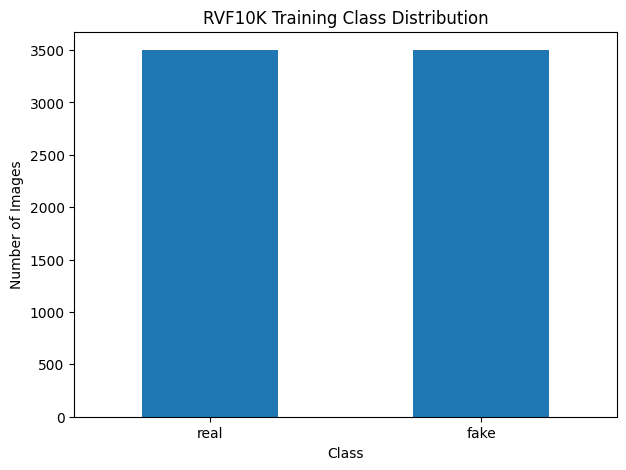


========== IMAGE PATH CHECK ==========
train/real/28609.jpg -> True
train/real/30395.jpg -> True
train/real/22430.jpg -> True
train/real/58380.jpg -> True
train/real/62044.jpg -> True

========== IMAGE DIMENSIONS ==========
Images checked : 500
Width  - Min: 256 Max: 256
Height - Min: 256 Max: 256
Most common size:
[((256, 256), 500)]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os

# Paths
BASE = "/content/RVF10K"
IMAGE_BASE = os.path.join(BASE, "rvf10k")

# Load CSV files
train = pd.read_csv(os.path.join(BASE, "train.csv"))
valid = pd.read_csv(os.path.join(BASE, "valid.csv"))

print("========== DATASET SUMMARY ==========")
print("Training samples   :", len(train))
print("Validation samples :", len(valid))
print("Total samples      :", len(train) + len(valid))

print("\n========== CLASS DISTRIBUTION ==========")
print("\nTraining:")
print(train["label_str"].value_counts())

print("\nValidation:")
print(valid["label_str"].value_counts())

print("\n========== CLASS PERCENTAGE ==========")
print("\nTraining:")
print(train["label_str"].value_counts(normalize=True) * 100)

print("\nValidation:")
print(valid["label_str"].value_counts(normalize=True) * 100)

# Plot class distribution
plt.figure(figsize=(7,5))
train["label_str"].value_counts().plot(kind="bar")
plt.title("RVF10K Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

# Check image paths
print("\n========== IMAGE PATH CHECK ==========")

for i in range(5):
    relative_path = train.iloc[i]["path"]
    full_path = os.path.join(IMAGE_BASE, relative_path)

    print(relative_path, "->", os.path.exists(full_path))

# Get image dimensions
print("\n========== IMAGE DIMENSIONS ==========")

widths = []
heights = []

for path in train["path"].head(500):
    full_path = os.path.join(IMAGE_BASE, path)

    if os.path.exists(full_path):
        with Image.open(full_path) as img:
            widths.append(img.width)
            heights.append(img.height)

print("Images checked :", len(widths))

if widths:
    print("Width  - Min:", min(widths), "Max:", max(widths))
    print("Height - Min:", min(heights), "Max:", max(heights))
    print("Most common size:")

    from collections import Counter
    print(Counter(zip(widths, heights)).most_common(10))

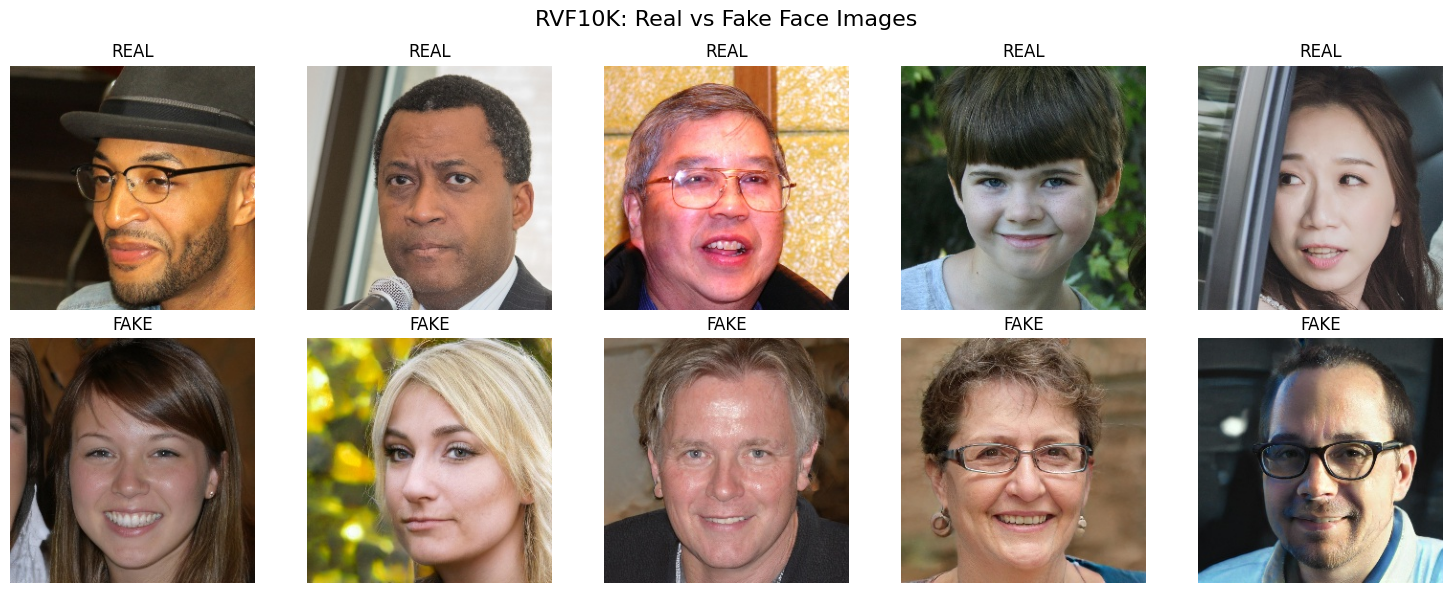

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

# Select 5 real and 5 fake images
real_paths = train[train["label_str"] == "real"]["path"].sample(5, random_state=42)
fake_paths = train[train["label_str"] == "fake"]["path"].sample(5, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Real images
for i, path in enumerate(real_paths):
    img = Image.open(os.path.join(IMAGE_BASE, path))
    axes[0, i].imshow(img)
    axes[0, i].set_title("REAL")
    axes[0, i].axis("off")

# Fake images
for i, path in enumerate(fake_paths):
    img = Image.open(os.path.join(IMAGE_BASE, path))
    axes[1, i].imshow(img)
    axes[1, i].set_title("FAKE")
    axes[1, i].axis("off")

plt.suptitle("RVF10K: Real vs Fake Face Images", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from PIL import Image
import os

def get_image_stats(df, n=500):
    brightness = []
    contrast = []

    sample = df.sample(n, random_state=42)

    for path in sample["path"]:
        full_path = os.path.join(IMAGE_BASE, path)

        img = np.array(Image.open(full_path).convert("RGB"))

        gray = np.mean(img, axis=2)

        brightness.append(np.mean(gray))
        contrast.append(np.std(gray))

    return np.mean(brightness), np.mean(contrast)

real_brightness, real_contrast = get_image_stats(
    train[train["label_str"] == "real"]
)

fake_brightness, fake_contrast = get_image_stats(
    train[train["label_str"] == "fake"]
)

print("========== IMAGE STATISTICS ==========")

print("\nREAL images:")
print("Average brightness:", round(real_brightness, 2))
print("Average contrast  :", round(real_contrast, 2))

print("\nFAKE images:")
print("Average brightness:", round(fake_brightness, 2))
print("Average contrast  :", round(fake_contrast, 2))

========== IMAGE STATISTICS ==========

REAL images:
Average brightness: 114.04
Average contrast  : 58.25

FAKE images:
Average brightness: 112.78
Average contrast  : 55.74


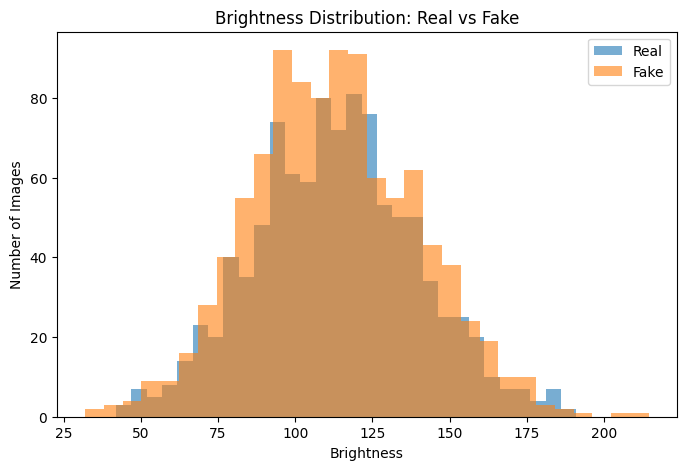

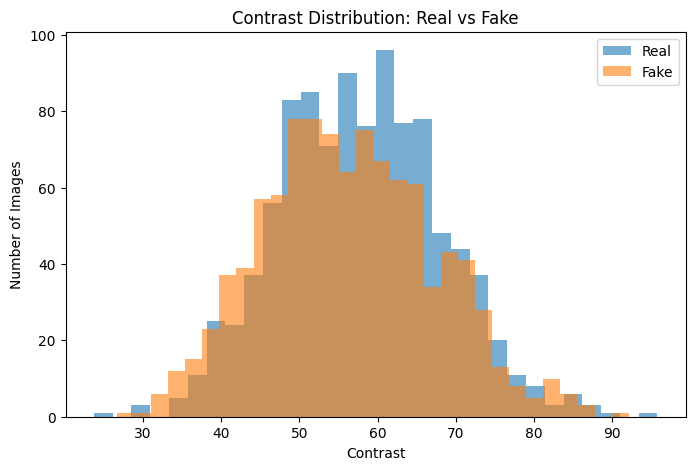

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

def collect_stats(df, n=1000):
    sample = df.sample(n, random_state=42)

    brightness = []
    contrast = []

    for path in sample["path"]:
        full_path = os.path.join(IMAGE_BASE, path)

        img = np.array(
            Image.open(full_path).convert("RGB")
        )

        gray = np.mean(img, axis=2)

        brightness.append(np.mean(gray))
        contrast.append(np.std(gray))

    return brightness, contrast


real_b, real_c = collect_stats(
    train[train["label_str"] == "real"]
)

fake_b, fake_c = collect_stats(
    train[train["label_str"] == "fake"]
)


# Brightness distribution
plt.figure(figsize=(8,5))

plt.hist(real_b, bins=30, alpha=0.6, label="Real")
plt.hist(fake_b, bins=30, alpha=0.6, label="Fake")

plt.xlabel("Brightness")
plt.ylabel("Number of Images")
plt.title("Brightness Distribution: Real vs Fake")
plt.legend()
plt.show()


# Contrast distribution
plt.figure(figsize=(8,5))

plt.hist(real_c, bins=30, alpha=0.6, label="Real")
plt.hist(fake_c, bins=30, alpha=0.6, label="Fake")

plt.xlabel("Contrast")
plt.ylabel("Number of Images")
plt.title("Contrast Distribution: Real vs Fake")
plt.legend()
plt.show()

In [ ]:

# EDA: Duplicate Image Check

#md5 (message digest algorithm) hashing makes sure that there is no data leakage that is testing part comes to training part
#converts a file into a unique fixed-length hash value (digital fingerprint). If two image files are exactly the same, their MD5 hashes will also be the same.
import hashlib
import os

def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Checking duplicate images...")
print("This may take a little time for 10,000 images.")

train_hashes = {}
valid_hashes = {}

# Hash training images
for path in train["path"]:
    full_path = os.path.join(IMAGE_BASE, path)

    if os.path.exists(full_path):
        h = image_hash(full_path)
        train_hashes[h] = train_hashes.get(h, 0) + 1

# Hash validation images
for path in valid["path"]:
    full_path = os.path.join(IMAGE_BASE, path)

    if os.path.exists(full_path):
        h = image_hash(full_path)
        valid_hashes[h] = valid_hashes.get(h, 0) + 1

# Exact duplicates within training
train_duplicates = sum(
    count - 1 for count in train_hashes.values() if count > 1
)

# Exact duplicates within validation
valid_duplicates = sum(
    count - 1 for count in valid_hashes.values() if count > 1
)

# Duplicates between train and validation
cross_duplicates = len(
    set(train_hashes.keys()) & set(valid_hashes.keys())
)

print("\n========== DUPLICATE CHECK ==========")
print("Training images checked   :", len(train_hashes))
print("Validation images checked :", len(valid_hashes))

print("\nDuplicates within training   :", train_duplicates)
print("Duplicates within validation :", valid_duplicates)
print("Duplicates between train/validation :", cross_duplicates)

if cross_duplicates == 0:
    print("\n✅ No exact train-validation duplicates found.")
else:
    print("\n Exact duplicates exist between train and validation.")

Checking duplicate images...
This may take a little time for 10,000 images.

========== DUPLICATE CHECK ==========
Training images checked   : 7000
Validation images checked : 3000

Duplicates within training   : 0
Duplicates within validation : 0
Duplicates between train/validation : 0

✅ No exact train-validation duplicates found.


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
import os


# 1. SETTINGS


IMG_SIZE = (128, 128) #image is resized to 128 x 128, earlier it was 256x256x3)
BATCH_SIZE = 32 #model processes 32 images at a time

train_dir = os.path.join(IMAGE_BASE, "train")
valid_dir = os.path.join(IMAGE_BASE, "valid")


# 2. LOAD DATA


train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary", #bcuz only two classes fake and real
    shuffle=True,#Training images are randomly shuffled so the model doesn't learn from a fixed order.
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False#We don't need to randomly shuffle validation data because we're only evaluating the model.
)

print("Classes:", train_ds.class_names)


# 3. NORMALIZATION


normalization = tf.keras.layers.Rescaling(1./255) #images normally hve pixels 0-255 ,we normalise it to 0-1 to make it more stable)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y)
)

valid_ds = valid_ds.map(
    lambda x, y: (normalization(x), y)
)


# 4. BASELINE ANN


ann_model = Sequential([

    Flatten(input_shape=(128,  3128,)),#flatten converts it into one long vector (49152 values)

    Dense(256, activation="relu"),#if take more value for this like 512 , more computation required and chance of overfitting)
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid") #this is binary classfication output ,sigmoid gives value between o to 1)
])


# 5. COMPILE


ann_model.compile(
    optimizer="adam", #adaptive moment estimator, it is an opitimization algorithm that updates model weights during training to reduce loss. it automatically adjusts the learning rte of each parameter making training faster and more stable.
    loss="binary_crossentropy",#how far is predicted entropy from actual class.(lower loss means prediction is closer to correct answer)
    metrics=["accuracy"]
)

ann_model.summary()

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Classes: ['fake', 'real']


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,583,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,624,385 (48.16 MB)

 Trainable params: 12,624,385 (48.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = ann_model.fit(   # trains the neural network by feeding it the training data,adjusting it wghts to reduce the loss.repeatd for spicified no. of epochs
    train_ds,
    validation_data=valid_ds,
    epochs=15
)#7000 training images/32(batch size)=219 batches

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 63s 272ms/step - accuracy: 0.5661 - loss: 1.2960 - val_accuracy: 0.6107 - val_loss: 0.6667
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 72s 328ms/step - accuracy: 0.5873 - loss: 0.7334 - val_accuracy: 0.6023 - val_loss: 0.7083
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 53s 239ms/step - accuracy: 0.6300 - loss: 0.6569 - val_accuracy: 0.6763 - val_loss: 0.5978
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 53s 242ms/step - accuracy: 0.6596 - loss: 0.6182 - val_accuracy: 0.6637 - val_loss: 0.6152
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 53s 243ms/step - accuracy: 0.6727 - loss: 0.6061 - val_accuracy: 0.6950 - val_loss: 0.5837
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 53s 241ms/step - accuracy: 0.6687 - loss: 0.6093 - val_accuracy: 0.5703 - val_loss: 0.7883
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 242ms/step - accuracy: 0.6879 - loss: 0.5973 - val_accuracy: 0.6597 - val_loss: 0.6211
Epoch 8/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 53s 240ms/step - accuracy: 0.6859 - loss: 0

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

        fake       0.50      0.00      0.00      1500
        real       0.50      1.00      0.67      1500

    accuracy                           0.50      3000
   macro avg       0.50      0.50      0.33      3000
weighted avg       0.50      0.50      0.33      3000

ROC-AUC: 0.4997

Confusion Matrix:
[[   1 1499]
 [   1 1499]]


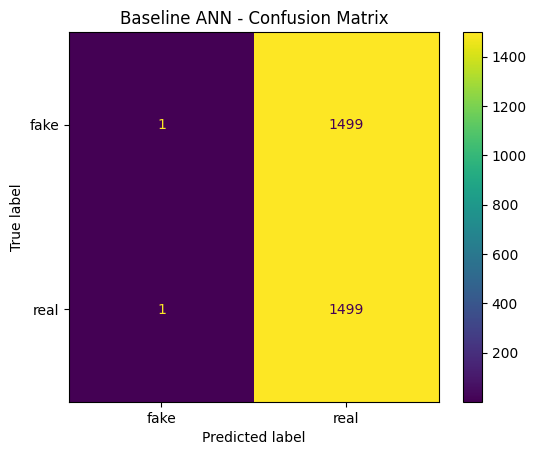

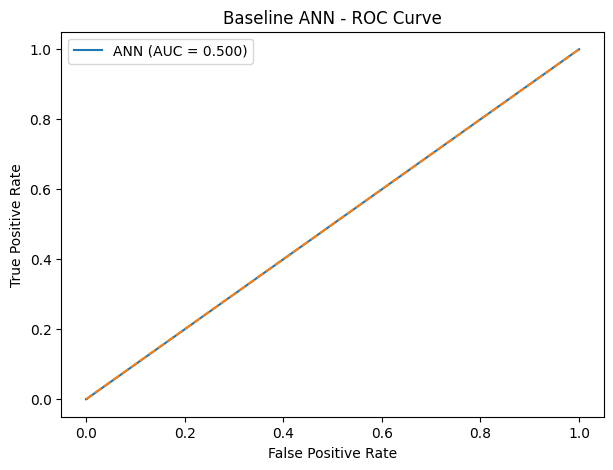

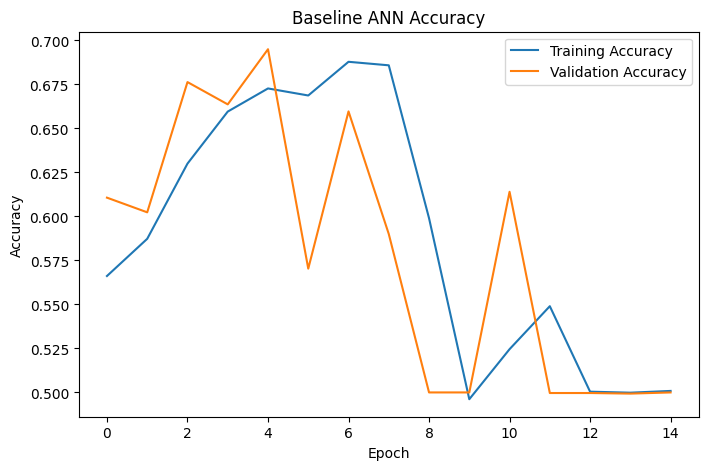

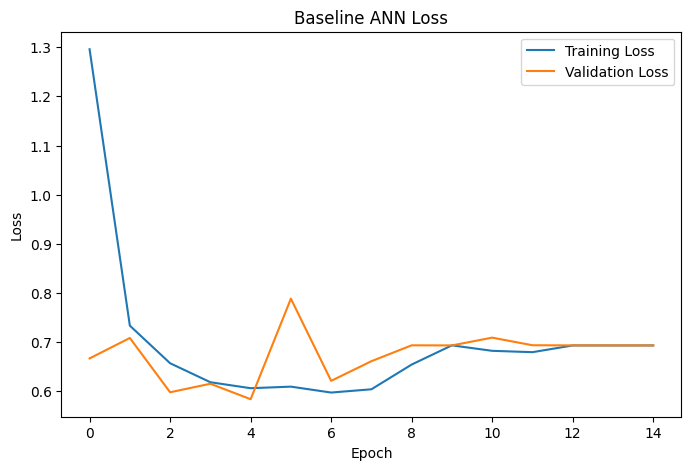

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    roc_curve
)


# 1. PREDICTIONS


y_true = []
y_prob = []

for images, labels in valid_ds:
    predictions = ann_model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_prob.extend(predictions.flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int) #threshokd 0.5


# 2. CLASSIFICATION REPORT


print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["fake", "real"]
    )
)


# 3. ROC-AUC


auc = roc_auc_score(y_true, y_prob)

print("ROC-AUC:", round(auc, 4))

# 4. CONFUSION MATRIX


cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["fake", "real"]
).plot()

plt.title("Baseline ANN - Confusion Matrix")
plt.show()

# ==========================================
# 5. ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label=f"ANN (AUC = {auc:.3f})")
plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline ANN - ROC Curve")
plt.legend()

plt.show()


# 6. TRAINING CURVES


plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline ANN Accuracy")
plt.legend()

plt.show()

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline ANN Loss")
plt.legend()

plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# CREATE ANN AGAIN


ann_model = Sequential([
    Flatten(input_shape=(128, 128, 3)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# SAVE BEST MODEL


checkpoint = ModelCheckpoint(
    "best_ann_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)


# STOP WHEN VALIDATION STOPS IMPROVING


early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    mode="max",#higher is output
    restore_best_weights=True,
    verbose=1 #display
)


# TRAIN


history = ann_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=15,
    callbacks=[checkpoint, early_stop] #chckpoint saves the best model based on val_accurcy
)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.5426 - loss: 1.5631
Epoch 1: val_accuracy improved from None to 0.53367, saving model to best_ann_model.keras

Epoch 1: finished saving model to best_ann_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 78s 331ms/step - accuracy: 0.5619 - loss: 1.0815 - val_accuracy: 0.5337 - val_loss: 0.8675
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.6045 - loss: 0.7322
Epoch 2: val_accuracy improved from 0.53367 to 0.65000, saving model to best_ann_model.keras

Epoch 2: finished saving model to best_ann_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 63s 245ms/step - accuracy: 0.6027 - loss: 0.7130 - val_accuracy: 0.6500 - val_loss: 0.6236
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.6256 - loss: 0.6514
Epoch 3: val_accuracy improved from 0.65000 to 0.68367, saving model to best_ann_model.keras

Epoch 3: finished saving model to best_ann_model.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 82s 247ms/step - accura

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

        fake       0.72      0.71      0.72      1500
        real       0.71      0.73      0.72      1500

    accuracy                           0.72      3000
   macro avg       0.72      0.72      0.72      3000
weighted avg       0.72      0.72      0.72      3000

ROC-AUC: 0.7914

Confusion Matrix:
[[1059  441]
 [ 403 1097]]


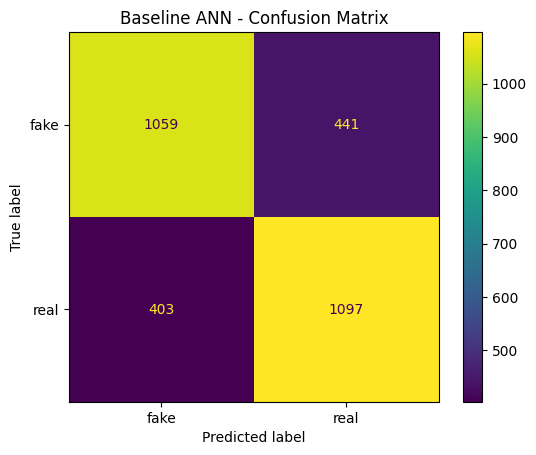

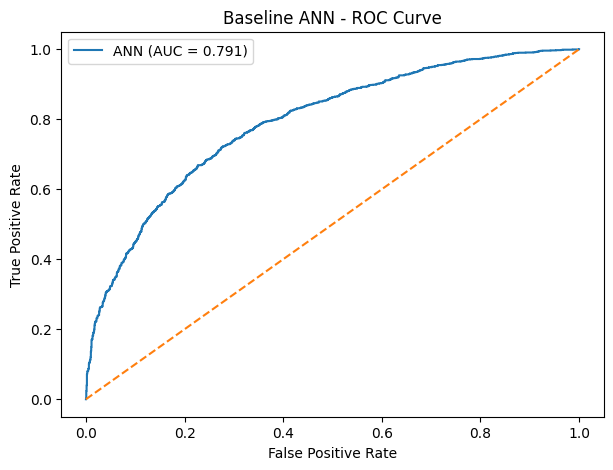

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    roc_curve
)


# PREDICTIONS


y_true = []
y_prob = []

for images, labels in valid_ds:
    predictions = ann_model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_prob.extend(predictions.flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = (y_prob >= 0.5).astype(int)

# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["fake", "real"]
    )
)

# ==========================================
# ROC-AUC
# ==========================================

auc = roc_auc_score(y_true, y_prob)

print("ROC-AUC:", round(auc, 4))

# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["fake", "real"]
).plot()

plt.title("Baseline ANN - Confusion Matrix")
plt.show()

# ==========================================
# ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"ANN (AUC = {auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline ANN - ROC Curve")
plt.legend()

plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


# IMPROVED ANN

improved_ann = Sequential([

    Input(shape=(128, 128, 3)),

    # Flatten image
    Flatten(),

    # First layer
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),

    # Second layer
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    # Third layer
    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    # Output
    Dense(1, activation="sigmoid")
])

improved_ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# CALLBACKS


checkpoint = ModelCheckpoint(
    "best_improved_ann.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    mode="max",
    restore_best_weights=True,
    verbose=1
)


# TRAIN


history_improved = improved_ann.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=20,
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.5534 - loss: 0.7733
Epoch 1: val_accuracy improved from None to 0.57600, saving model to best_improved_ann.keras

Epoch 1: finished saving model to best_improved_ann.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 67s 284ms/step - accuracy: 0.5599 - loss: 0.7461 - val_accuracy: 0.5760 - val_loss: 0.7055
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.6067 - loss: 0.6830
Epoch 2: val_accuracy improved from 0.57600 to 0.62600, saving model to best_improved_ann.keras

Epoch 2: finished saving model to best_improved_ann.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 84s 294ms/step - accuracy: 0.6187 - loss: 0.6723 - val_accuracy: 0.6260 - val_loss: 0.6521
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.6439 - loss: 0.6348
Epoch 3: val_accuracy improved from 0.62600 to 0.64167, saving model to best_improved_ann.keras

Epoch 3: finished saving model to best_improved_ann.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 67s 2

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if "rvf10k" in root.lower() or "RVF10K" in root:
        print(root)

In [ ]:
import os

print("ZIP:", os.path.exists("/content/archive.zip"))
print("Improved model:", os.path.exists("/content/best_improved_ann.keras"))
print("Baseline model:", os.path.exists("/content/best_ann_model.keras"))

ZIP: False
Improved model: False
Baseline model: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Deepfake_Project"

os.makedirs(PROJECT, exist_ok=True)
os.makedirs(os.path.join(PROJECT, "models"), exist_ok=True)
os.makedirs(os.path.join(PROJECT, "results"), exist_ok=True)
os.makedirs(os.path.join(PROJECT, "plots"), exist_ok=True)

print("Permanent project folder created:")
print(PROJECT)

Permanent project folder created:
/content/drive/MyDrive/Deepfake_Project


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import shutil
import os

source = "/content/archive.zip"
destination = "/content/drive/MyDrive/Deepfake_Project/archive.zip"

shutil.copy2(source, destination)

print("Saved permanently to Google Drive!")
print("File exists:", os.path.exists(destination))

Saved permanently to Google Drive!
File exists: True


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Deepfake_Project/archive.zip"
EXTRACT_PATH = "/content/RVF10K"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted!")
print("Contents:")
print(os.listdir(EXTRACT_PATH))

Dataset extracted!
Contents:
['valid.csv', 'rvf10k', 'train.csv']


In [ ]:
import os

for root, dirs, files in os.walk("/content/RVF10K"):
    level = root.replace("/content/RVF10K", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        dirs[:] = []

RVF10K/
  rvf10k/
    valid/
    train/


In [ ]:
import os

IMAGE_BASE = "/content/RVF10K/rvf10k"

print("Train folders:", os.listdir(os.path.join(IMAGE_BASE, "train")))
print("Valid folders:", os.listdir(os.path.join(IMAGE_BASE, "valid")))

print("\nTrain counts:")
for folder in ["real", "fake"]:
    path = os.path.join(IMAGE_BASE, "train", folder)
    print(folder, len(os.listdir(path)))

print("\nValidation counts:")
for folder in ["real", "fake"]:
    path = os.path.join(IMAGE_BASE, "valid", folder)
    print(folder, len(os.listdir(path)))

Train folders: ['fake', 'real']
Valid folders: ['fake', 'real']

Train counts:
real 3500
fake 3500

Validation counts:
real 1500
fake 1500


In [ ]:
import tensorflow as tf
import os

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

IMAGE_BASE = "/content/RVF10K/rvf10k"

train_dir = os.path.join(IMAGE_BASE, "train")
valid_dir = os.path.join(IMAGE_BASE, "valid")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Classes: ['fake', 'real']


In [ ]:
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

valid_ds = valid_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
valid_ds = valid_ds.prefetch(tf.data.AUTOTUNE)

print("Datasets ready.")

Datasets ready.


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Permanent model location
MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras"

# Improved ANN
improved_ann = Sequential([
    Input(shape=(128, 128, 3)),

    Flatten(),

    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.4),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

improved_ann.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Save BEST model directly to Google Drive
checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

history_improved = improved_ann.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=20,
    callbacks=[checkpoint, early_stop]
)

print("\nTraining complete!")
print("Best model saved to:", MODEL_PATH)

Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.5352 - loss: 0.8114
Epoch 1: val_accuracy improved from None to 0.60433, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 70s 285ms/step - accuracy: 0.5550 - loss: 0.7637 - val_accuracy: 0.6043 - val_loss: 0.6634
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.5992 - loss: 0.6924
Epoch 2: val_accuracy improved from 0.60433 to 0.65433, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 57s 260ms/step - accuracy: 0.6016 - loss: 0.6849 - val_accuracy: 0.6543 - val_loss: 0.6191
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.6329 - loss: 0.6446
E

In [ ]:
from tensorflow.keras.models import load_model

MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras"

improved_ann = load_model(MODEL_PATH)

print("Model loaded successfully!")

Model loaded successfully!


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        fake     0.7067    0.7053    0.7060      1500
        real     0.7059    0.7073    0.7066      1500

    accuracy                         0.7063      3000
   macro avg     0.7063    0.7063    0.7063      3000
weighted avg     0.7063    0.7063    0.7063      3000

Accuracy : 0.7063 (70.63%)
ROC-AUC  : 0.7779

CONFUSION MATRIX
[[1058  442]
 [ 439 1061]]


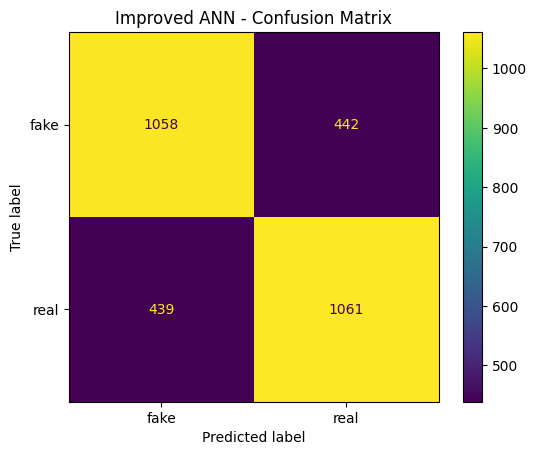

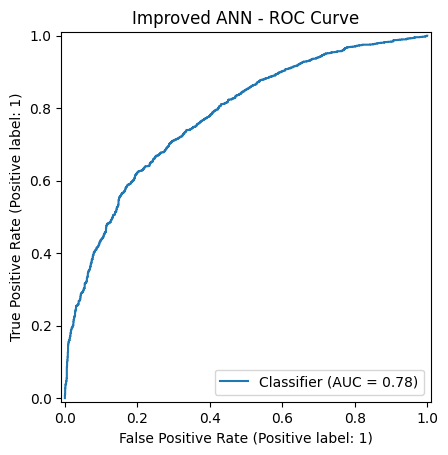

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

# Get predictions
y_true = []
y_prob = []

for images, labels in valid_ds:
    predictions = improved_ann.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_prob.extend(predictions.flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probabilities to predictions
y_pred = (y_prob >= 0.5).astype(int)

# Classification report
print("CLASSIFICATION REPORT")
print("=" * 60)
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["fake", "real"],
        digits=4
    )
)

# Accuracy
accuracy = np.mean(y_true == y_pred)

# ROC-AUC
auc = roc_auc_score(y_true, y_prob)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

print("\nCONFUSION MATRIX")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["fake", "real"]
).plot()

plt.title("Improved ANN - Confusion Matrix")
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_true, y_prob)

plt.title("Improved ANN - ROC Curve")
plt.show()

In [ ]:

# EfficientNetB0 CNN BASELINE — Deepfake Detection


import os
import json
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# 1. Permanent Google Drive paths


PROJECT = "/content/drive/MyDrive/Deepfake_Project"

MODEL_DIR = os.path.join(PROJECT, "models")
RESULTS_DIR = os.path.join(PROJECT, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "best_efficientnetb0.keras")
HISTORY_PATH = os.path.join(RESULTS_DIR, "efficientnetb0_history.json")

# ------------------------------------------------------------
# 2. Build EfficientNetB0
# ------------------------------------------------------------

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Freeze pretrained layers for baseline experiment
base_model.trainable = False

# ------------------------------------------------------------
# 3. Classification head
# ------------------------------------------------------------

inputs = tf.keras.Input(shape=(128, 128, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

cnn_model = Model(inputs, outputs)

# ------------------------------------------------------------
# 4. Compile
# ------------------------------------------------------------

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 5. Display model
# ------------------------------------------------------------

cnn_model.summary()

# ------------------------------------------------------------
# 6. Callbacks — SAVE DIRECTLY TO GOOGLE DRIVE
# ------------------------------------------------------------

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# ------------------------------------------------------------
# 7. Train
# ------------------------------------------------------------

print("\nStarting EfficientNetB0 training...\n")

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=15,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

# ------------------------------------------------------------
# 8. Save training history permanently
# ------------------------------------------------------------

history_data = {
    key: [float(v) for v in values]
    for key, values in history_cnn.history.items()
}

with open(HISTORY_PATH, "w") as f:
    json.dump(history_data, f, indent=4)

# ------------------------------------------------------------
# 9. Find best validation accuracy
# ------------------------------------------------------------

best_epoch = (
    max(range(len(history_cnn.history["val_accuracy"])),
        key=lambda i: history_cnn.history["val_accuracy"][i])
    + 1
)

best_val_accuracy = max(history_cnn.history["val_accuracy"])

print("\n" + "=" * 60)
print("EFFICIENTNETB0 TRAINING COMPLETE")
print("=" * 60)

print(f"Best Epoch             : {best_epoch}")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")

print("\nModel saved to:")
print(MODEL_PATH)

print("\nTraining history saved to:")
print(HISTORY_PATH)

print("\nModel exists:", os.path.exists(MODEL_PATH))
print("History exists:", os.path.exists(HISTORY_PATH))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Starting EfficientNetB0 training...

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - accuracy: 0.5094 - loss: 0.7067
Epoch 1: val_accuracy improved from None to 0.50000, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 236s 980ms/step - accuracy: 0.5024 - loss: 0.6989 - val_accuracy: 0.5000 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 654ms/step - accuracy: 0.5077 - loss: 0.6932
Epoch 2: val_accuracy did not improve from 0.50000
219/219 ━━━━━━━━━━━━━━━━━━━━ 251s 930ms/step - accuracy: 0.5014 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 668ms/step - accuracy: 0.4964 - loss: 0.6932
Epoch 3: val_accuracy did not improve from 0.50000

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.

KeyboardInterrupt: 

In [ ]:
for images, labels in train_ds.take(1):
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())
    print("Mean:", tf.reduce_mean(images).numpy())

Minimum: 0.0
Maximum: 1.0
Mean: 0.43277594


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# =========================================================
# 1. CREATE FRESH DATASETS FOR EFFICIENTNET
# =========================================================

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

IMAGE_BASE = "/content/RVF10K/rvf10k"
train_dir = os.path.join(IMAGE_BASE, "train")
valid_dir = os.path.join(IMAGE_BASE, "valid")

eff_train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

eff_valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# EfficientNet gets the ORIGINAL 0-255 pixel values.
eff_train_ds = eff_train_ds.prefetch(tf.data.AUTOTUNE)
eff_valid_ds = eff_valid_ds.prefetch(tf.data.AUTOTUNE)

# =========================================================
# 2. CHECK INPUT RANGE
# =========================================================

for images, labels in eff_train_ds.take(1):
    print("Input minimum:", tf.reduce_min(images).numpy())
    print("Input maximum:", tf.reduce_max(images).numpy())

# =========================================================
# 3. BUILD EFFICIENTNETB0
# =========================================================

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Freeze pretrained CNN
base_model.trainable = False

inputs = tf.keras.Input(shape=(128, 128, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

cnn_model = Model(inputs, outputs)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

# =========================================================
# 4. SAVE TO GOOGLE DRIVE
# =========================================================

PROJECT = "/content/drive/MyDrive/Deepfake_Project"
MODEL_DIR = os.path.join(PROJECT, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_efficientnetb0.keras"
)

# =========================================================
# 5. CALLBACKS
# =========================================================

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# =========================================================
# 6. TRAIN
# =========================================================

print("\nStarting EfficientNetB0 training...")

history_cnn = cnn_model.fit(
    eff_train_ds,
    validation_data=eff_valid_ds,
    epochs=15,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

print("\nTraining completed!")
print("Best model saved at:")
print(MODEL_PATH)

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Input minimum: 0.0
Input maximum: 255.0


Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Starting EfficientNetB0 training...
Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 659ms/step - accuracy: 0.6557 - loss: 0.6100
Epoch 1: val_accuracy improved from None to 0.75100, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 245s 1s/step - accuracy: 0.7050 - loss: 0.5623 - val_accuracy: 0.7510 - val_loss: 0.5151 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step - accuracy: 0.7616 - loss: 0.4857
Epoch 2: val_accuracy improved from 0.75100 to 0.77133, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 228s 1s/step - accuracy: 0.7660 - loss: 0.4855 - val_accuracy: 0.7713 - val_loss: 0.4846 - learning_rate: 0.0010


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Load the best saved EfficientNetB0 model
MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras"

best_model = tf.keras.models.load_model(MODEL_PATH)

# Get predictions
y_true = []
y_prob = []

for images, labels in eff_valid_ds:
    predictions = best_model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().astype(int))
    y_prob.extend(predictions)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("\n" + "="*50)
print("EFFICIENTNETB0 FINAL EVALUATION")
print("="*50)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["fake", "real"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))


EFFICIENTNETB0 FINAL EVALUATION
Accuracy : 0.7987 (79.87%)
ROC-AUC  : 0.8810

Classification Report:
              precision    recall  f1-score   support

        fake     0.7800    0.8320    0.8052      1500
        real     0.8200    0.7653    0.7917      1500

    accuracy                         0.7987      3000
   macro avg     0.8000    0.7987    0.7984      3000
weighted avg     0.8000    0.7987    0.7984      3000


Confusion Matrix:
[[1248  252]
 [ 352 1148]]


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving scamai-deepfake-detector-dataset-1.0.1.zip to scamai-deepfake-detector-dataset-1.0.1.zip


In [ ]:
import os
import zipfile

ZIP_PATH = "/content/scamai-deepfake-detector-dataset-1.0.1.zip"
EXTRACT_PATH = "/content/RWFS"

print("Extracting RWFS dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Extraction completed!\n")

print("Dataset structure:\n")

for root, dirs, files in os.walk(EXTRACT_PATH):
    level = root.replace(EXTRACT_PATH, "").count(os.sep)

    if level <= 3:
        print(
            "  " * level +
            os.path.basename(root) +
            f"  ({len(files)} files)"
        )

Extracting RWFS dataset...
Extraction completed!

Dataset structure:

RWFS  (0 files)
  scamai-deepfake-detector-dataset-1.0.1  (2 files)
    fake-20250420T082018Z-001  (0 files)
      fake  (500 files)
    real-20250420T081907Z-001  (0 files)
      real  (500 files)


In [ ]:
import os
import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# PATHS
# ============================================================

RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras"

# ============================================================
# LOAD THE TRAINED EFFICIENTNETB0
# ============================================================

print("Loading EfficientNetB0...")

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")

# ============================================================
# LOAD RWFS
# ============================================================

rwfs_ds = tf.keras.utils.image_dataset_from_directory(
    RWFS_DIR,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("\nClasses:", rwfs_ds.class_names)

# ============================================================
# PREDICTIONS
# ============================================================

print("\nTesting on RWFS...")
print("NO TRAINING is happening.")

y_true = []
y_prob = []

for images, labels in rwfs_ds:

    predictions = model.predict(
        images,
        verbose=0
    ).ravel()

    y_true.extend(labels.numpy().astype(int))
    y_prob.extend(predictions)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# ============================================================
# CLASS PREDICTIONS
# ============================================================

y_pred = (y_prob >= 0.5).astype(int)

# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("\n" + "=" * 60)
print("RWFS UNSEEN DATASET RESULTS")
print("=" * 60)

print(f"\nAccuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=rwfs_ds.class_names,
        digits=4
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true,
        y_pred
    )
)

# ============================================================
# GENERALIZATION GAP
# ============================================================

RVF10K_ACCURACY = 79.87

rwfs_accuracy = accuracy * 100

gap = RVF10K_ACCURACY - rwfs_accuracy

print("\n" + "=" * 60)
print("GENERALIZATION GAP")
print("=" * 60)

print(f"\nRVF10K validation : {RVF10K_ACCURACY:.2f}%")
print(f"RWFS unseen data  : {rwfs_accuracy:.2f}%")
print(f"Accuracy drop     : {gap:.2f} percentage points")

Loading EfficientNetB0...
Model loaded successfully.
Found 1000 files belonging to 2 classes.

Classes: ['fake-20250420T082018Z-001', 'real-20250420T081907Z-001']

Testing on RWFS...
NO TRAINING is happening.

RWFS UNSEEN DATASET RESULTS

Accuracy : 0.5080 (50.80%)
ROC-AUC  : 0.5447

Classification Report:
                           precision    recall  f1-score   support

fake-20250420T082018Z-001     0.5465    0.0940    0.1604       500
real-20250420T081907Z-001     0.5044    0.9220    0.6521       500

                 accuracy                         0.5080      1000
                macro avg     0.5254    0.5080    0.4062      1000
             weighted avg     0.5254    0.5080    0.4062      1000


Confusion Matrix:
[[ 47 453]
 [ 39 461]]

GENERALIZATION GAP

RVF10K validation : 79.87%
RWFS unseen data  : 50.80%
Accuracy drop     : 29.07 percentage points


Fake images: 5
Real images: 5

Fake image sizes:
(425, 500)
(450, 600)
(214, 421)
(333, 500)
(338, 483)

Real image sizes:
(878, 980)
(345, 500)
(819, 1229)
(347, 500)
(350, 375)


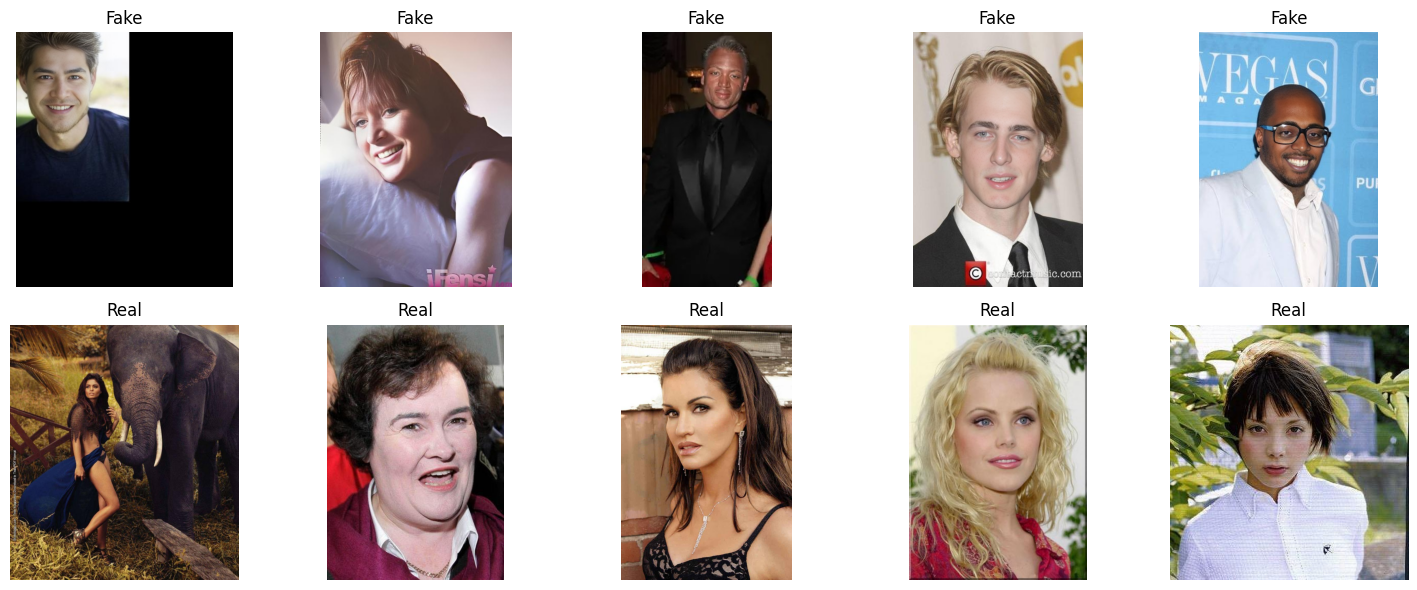

In [ ]:
import matplotlib.pyplot as plt
import os
from PIL import Image

RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

fake_dir = os.path.join(
    RWFS_DIR,
    "fake-20250420T082018Z-001",
    "fake"
)

real_dir = os.path.join(
    RWFS_DIR,
    "real-20250420T081907Z-001",
    "real"
)

fake_images = [
    os.path.join(fake_dir, f)
    for f in os.listdir(fake_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
][:5]

real_images = [
    os.path.join(real_dir, f)
    for f in os.listdir(real_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
][:5]

print("Fake images:", len(fake_images))
print("Real images:", len(real_images))

# Show image information
print("\nFake image sizes:")
for path in fake_images:
    print(Image.open(path).size)

print("\nReal image sizes:")
for path in real_images:
    print(Image.open(path).size)

# Display samples
plt.figure(figsize=(15, 6))

for i, path in enumerate(fake_images):
    img = Image.open(path)
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title("Fake")

for i, path in enumerate(real_images):
    img = Image.open(path)
    plt.subplot(2, 5, i + 6)
    plt.imshow(img)
    plt.axis("off")
    plt.title("Real")

plt.tight_layout()
plt.show()

In [ ]:
# ================================
# STEP 1: Test EfficientNetB0 on RWFS
# ================================

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

# Paths
RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"
MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras"

# Load RWFS
rwfs_ds = tf.keras.utils.image_dataset_from_directory(
    RWFS_DIR,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Classes:", rwfs_ds.class_names)

# Load trained model
model = tf.keras.models.load_model(MODEL_PATH)

# Predictions
y_true = np.concatenate([y.numpy().flatten() for _, y in rwfs_ds])
y_prob = model.predict(rwfs_ds, verbose=1).flatten()
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("\n==============================")
print("RWFS RESULTS")
print("==============================")
print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fake", "Real"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Found 1000 files belonging to 2 classes.
Classes: ['fake-20250420T082018Z-001', 'real-20250420T081907Z-001']
32/32 ━━━━━━━━━━━━━━━━━━━━ 27s 774ms/step

RWFS RESULTS
Accuracy : 0.5080 (50.80%)
ROC-AUC  : 0.5447

Classification Report:
              precision    recall  f1-score   support

        Fake       0.55      0.09      0.16       500
        Real       0.50      0.92      0.65       500

    accuracy                           0.51      1000
   macro avg       0.53      0.51      0.41      1000
weighted avg       0.53      0.51      0.41      1000


Confusion Matrix:
[[ 47 453]
 [ 39 461]]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
import os

# =========================
# PATHS
# =========================
TRAIN_DIR = "/content/RVF10K/rvf10k/train"
VALID_DIR = "/content/RVF10K/rvf10k/valid"

MODEL_DIR = "/content/drive/MyDrive/Deepfake_Project/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# =========================
# DATASET
# IMPORTANT: NO /255 NORMALIZATION
# EfficientNet handles preprocessing internally
# =========================
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Performance
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
valid_ds = valid_ds.prefetch(tf.data.AUTOTUNE)

print("Classes: ['fake', 'real']")

# =========================
# DATA AUGMENTATION
# =========================
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15)
], name="augmentation")

# =========================
# EFFICIENTNETB0
# =========================
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

# Freeze pretrained layers
base_model.trainable = False

inputs = tf.keras.Input(shape=(128, 128, 3))

# Augmentation
x = augmentation(inputs)

# EfficientNet
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model_aug = Model(inputs, outputs)

# =========================
# COMPILE
# =========================
model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_aug.summary()

# =========================
# CALLBACKS
# =========================
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    os.path.join(MODEL_DIR, "best_efficientnet_aug.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_accuracy",
    factor=0.5,
    patience=2,
    mode="max",
    verbose=1
)

# =========================
# TRAIN
# =========================
history_aug = model_aug.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=15,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Classes: ['fake', 'real']


Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 776ms/step - accuracy: 0.6370 - loss: 0.6252
Epoch 1: val_accuracy improved from None to 0.73500, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnet_aug.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnet_aug.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 248s 1s/step - accuracy: 0.6811 - loss: 0.5915 - val_accuracy: 0.7350 - val_loss: 0.5373 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 797ms/step - accuracy: 0.7283 - loss: 0.5418
Epoch 2: val_accuracy did not improve from 0.73500
219/219 ━━━━━━━━━━━━━━━━━━━━ 235s 1s/step - accuracy: 0.7304 - loss: 0.5359 - val_accuracy: 0.7250 - val_loss: 0.5429 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 763ms/step - accuracy: 0.7411 - loss: 0.5233
Epoch 3: val_accuracy improved from 0.73500 to 0.74500, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_efficientnet_aug.keras


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded file(s):")
for filename in uploaded.keys():
    print(filename)

Saving scamai-deepfake-detector-dataset-1.0.1.zip to scamai-deepfake-detector-dataset-1.0.1.zip

Uploaded file(s):
scamai-deepfake-detector-dataset-1.0.1.zip


In [ ]:
import os
import shutil

# Permanent folder in Google Drive
DRIVE_DATASET_DIR = "/content/drive/MyDrive/Deepfake_Project/datasets"
os.makedirs(DRIVE_DATASET_DIR, exist_ok=True)

# Uploaded ZIP
ZIP_PATH = "/content/scamai-deepfake-detector-dataset-1.0.1.zip"

# Permanent destination
PERMANENT_ZIP = os.path.join(
    DRIVE_DATASET_DIR,
    "scamai-deepfake-detector-dataset-1.0.1.zip"
)

# Copy ZIP to Google Drive
shutil.copy2(ZIP_PATH, PERMANENT_ZIP)

print("✅ ZIP permanently saved to Google Drive!")
print(PERMANENT_ZIP)
print(f"Size: {os.path.getsize(PERMANENT_ZIP) / (1024**2):.2f} MB")

✅ ZIP permanently saved to Google Drive!
/content/drive/MyDrive/Deepfake_Project/datasets/scamai-deepfake-detector-dataset-1.0.1.zip
Size: 71.96 MB


In [ ]:
import zipfile
import os

# Permanent ZIP in Google Drive
ZIP_PATH = "/content/drive/MyDrive/Deepfake_Project/datasets/scamai-deepfake-detector-dataset-1.0.1.zip"

# Temporary extraction location for this Colab session
EXTRACT_DIR = "/content/RWFS"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("✅ RWFS extracted successfully!")

# Show folders
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

✅ RWFS extracted successfully!
RWFS/
  scamai-deepfake-detector-dataset-1.0.1/
    fake-20250420T082018Z-001/
      fake/
    real-20250420T081907Z-001/
      real/


In [ ]:
# ============================================
# STEP 3B — AUGMENTED EFFICIENTNET ON RWFS
# ============================================

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------
# 1. Permanent saved model
# --------------------------------------------
MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_efficientnet_aug.keras"

print("Model exists:", os.path.exists(MODEL_PATH))

# --------------------------------------------
# 2. RWFS dataset
# --------------------------------------------
RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

print("RWFS exists:", os.path.exists(RWFS_DIR))

rwfs_ds = tf.keras.utils.image_dataset_from_directory(
    RWFS_DIR,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Classes:", rwfs_ds.class_names)

# --------------------------------------------
# 3. Load saved model
# --------------------------------------------
model_aug = tf.keras.models.load_model(MODEL_PATH)

print("✅ Augmented EfficientNet loaded!")

# --------------------------------------------
# 4. Predictions
# --------------------------------------------
y_true = np.concatenate([
    y.numpy().flatten()
    for _, y in rwfs_ds
])

y_prob = model_aug.predict(
    rwfs_ds,
    verbose=1
).flatten()

y_pred = (y_prob >= 0.5).astype(int)

# --------------------------------------------
# 5. Metrics
# --------------------------------------------
accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("\n======================================")
print("AUGMENTED EFFICIENTNET — RWFS")
print("======================================")

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fake", "Real"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Model exists: True
RWFS exists: True
Found 1000 files belonging to 2 classes.
Classes: ['fake-20250420T082018Z-001', 'real-20250420T081907Z-001']
✅ Augmented EfficientNet loaded!
32/32 ━━━━━━━━━━━━━━━━━━━━ 30s 838ms/step

AUGMENTED EFFICIENTNET — RWFS
Accuracy : 0.4740 (47.40%)
ROC-AUC  : 0.4682

Classification Report:
              precision    recall  f1-score   support

        Fake       0.41      0.11      0.18       500
        Real       0.48      0.84      0.61       500

    accuracy                           0.47      1000
   macro avg       0.45      0.47      0.39      1000
weighted avg       0.45      0.47      0.39      1000


Confusion Matrix:
[[ 56 444]
 [ 82 418]]


In [ ]:
# ============================================
# STEP 4 — Analyze RWFS Prediction Behavior
# ============================================

import numpy as np

# y_true, y_prob and y_pred already exist
# from the previous experiment

fake_mask = (y_true == 0)
real_mask = (y_true == 1)

fake_probs = y_prob[fake_mask]
real_probs = y_prob[real_mask]

print("======================================")
print("RWFS PREDICTION ANALYSIS")
print("======================================")

print("\nFAKE IMAGES")
print(f"Average predicted probability of REAL: {fake_probs.mean():.4f}")
print(f"Minimum probability: {fake_probs.min():.4f}")
print(f"Maximum probability: {fake_probs.max():.4f}")

print("\nREAL IMAGES")
print(f"Average predicted probability of REAL: {real_probs.mean():.4f}")
print(f"Minimum probability: {real_probs.min():.4f}")
print(f"Maximum probability: {real_probs.max():.4f}")

# Predictions
fake_pred_real = np.sum((y_true == 0) & (y_pred == 1))
fake_pred_fake = np.sum((y_true == 0) & (y_pred == 0))

real_pred_real = np.sum((y_true == 1) & (y_pred == 1))
real_pred_fake = np.sum((y_true == 1) & (y_pred == 0))

print("\n======================================")
print("PREDICTION COUNTS")
print("======================================")

print(f"Fake correctly detected : {fake_pred_fake}")
print(f"Fake incorrectly Real   : {fake_pred_real}")

print(f"Real correctly detected : {real_pred_real}")
print(f"Real incorrectly Fake   : {real_pred_fake}")

RWFS PREDICTION ANALYSIS

FAKE IMAGES
Average predicted probability of REAL: 0.8064
Minimum probability: 0.0252
Maximum probability: 1.0000

REAL IMAGES
Average predicted probability of REAL: 0.7719
Minimum probability: 0.0123
Maximum probability: 0.9999

PREDICTION COUNTS
Fake correctly detected : 56
Fake incorrectly Real   : 444
Real correctly detected : 418
Real incorrectly Fake   : 82


Top 10 confidently misclassified FAKE images:

1. k3MSORY0.jpg | P(Real) = 1.0000
2. remaker_pair_10.jpg | P(Real) = 1.0000
3. 3 (9).jpg | P(Real) = 0.9999
4. 7 (15).jpg | P(Real) = 0.9999
5. 3 (23).jpg | P(Real) = 0.9998
6. 2 (8).jpg | P(Real) = 0.9998
7. 3 (13).jpg | P(Real) = 0.9998
8. 691_face-swap.png | P(Real) = 0.9997
9. 4 (4).jpg | P(Real) = 0.9997
10. e363aac2-11f8-4d0d-b475-fed593b709f8.jpg | P(Real) = 0.9997


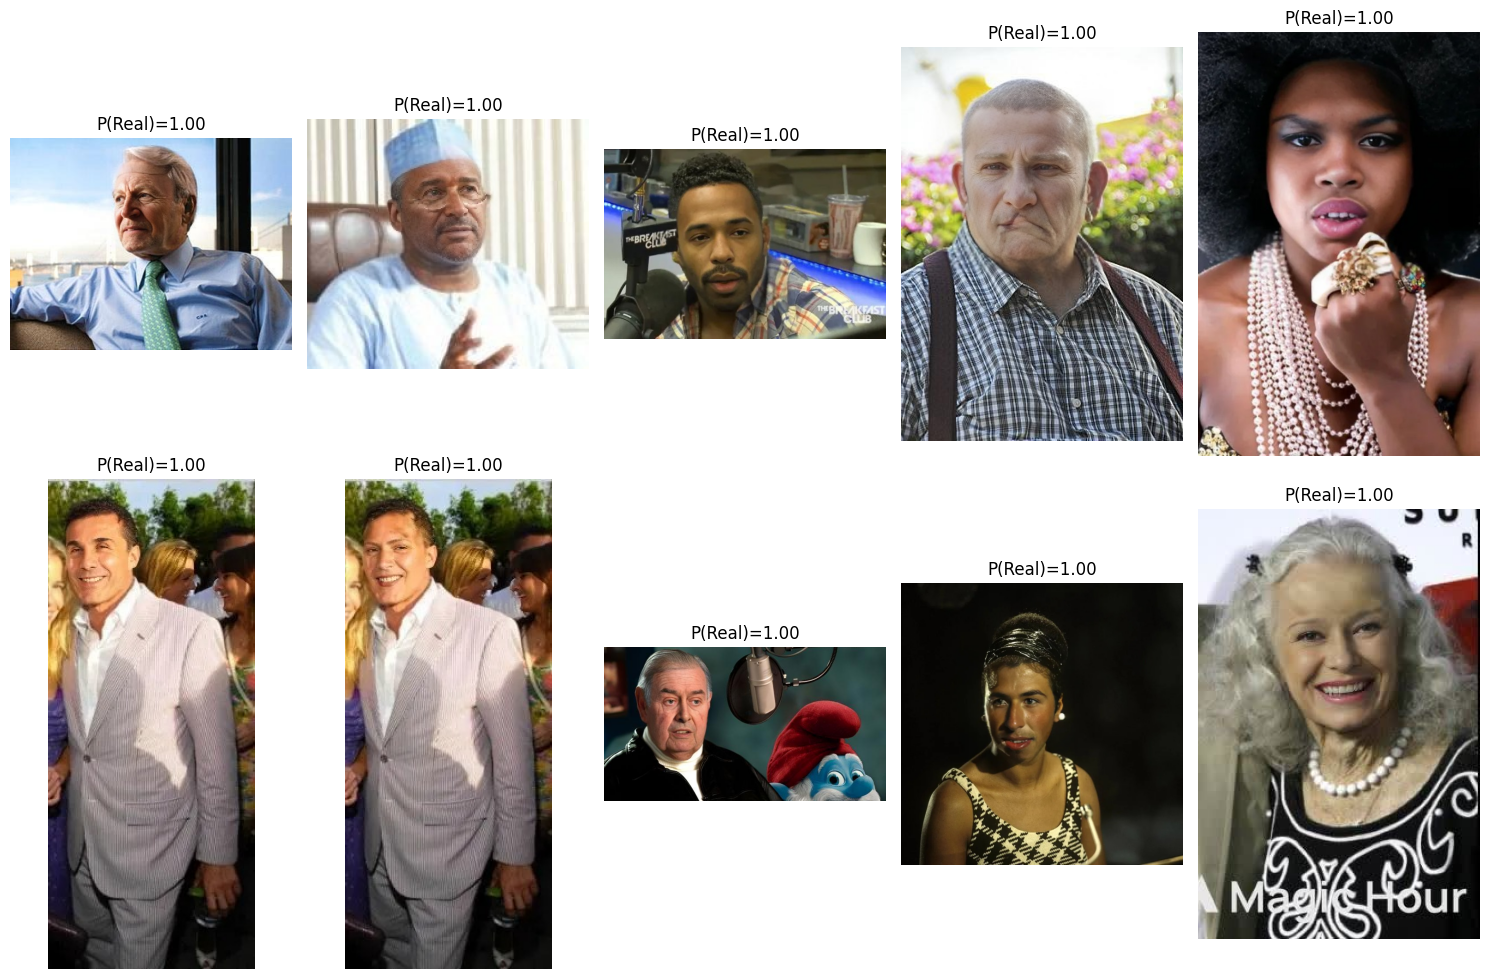

In [ ]:
# ============================================
# STEP 5 — VISUALIZE CONFIDENTLY WRONG FAKES
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

fake_dir = os.path.join(
    RWFS_DIR,
    "fake-20250420T082018Z-001",
    "fake"
)

fake_files = sorted([
    os.path.join(fake_dir, f)
    for f in os.listdir(fake_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

# Get fake-image indices
fake_indices = np.where(y_true == 0)[0]

# Model probability of REAL for fake images
fake_probs = y_prob[fake_indices]

# Most confidently predicted as REAL
top_positions = np.argsort(fake_probs)[-10:][::-1]
top_indices = fake_indices[top_positions]

print("Top 10 confidently misclassified FAKE images:")
print()

for rank, idx in enumerate(top_indices, 1):
    print(
        f"{rank}. {os.path.basename(fake_files[top_positions[rank-1]])} "
        f"| P(Real) = {y_prob[idx]:.4f}"
    )

# Display
plt.figure(figsize=(15, 10))

for i, idx in enumerate(top_indices):
    img = Image.open(fake_files[top_positions[i]])

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"P(Real)={y_prob[idx]:.2f}")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# STEP 6A — PERMANENT EXPERIMENT RESULTS
# ============================================

import os
import pandas as pd

RESULTS_DIR = "/content/drive/MyDrive/Deepfake_Project/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

results = pd.DataFrame([
    {
        "Model": "EfficientNetB0",
        "Training_Dataset": "RVF10K",
        "Test_Dataset": "RVF10K",
        "Accuracy": 0.7987,
        "ROC_AUC": 0.8810
    },
    {
        "Model": "EfficientNetB0",
        "Training_Dataset": "RVF10K",
        "Test_Dataset": "RWFS",
        "Accuracy": 0.5080,
        "ROC_AUC": 0.5447
    },
    {
        "Model": "EfficientNetB0 + Augmentation",
        "Training_Dataset": "RVF10K",
        "Test_Dataset": "RVF10K",
        "Accuracy": 0.7790,
        "ROC_AUC": None
    },
    {
        "Model": "EfficientNetB0 + Augmentation",
        "Training_Dataset": "RVF10K",
        "Test_Dataset": "RWFS",
        "Accuracy": 0.4740,
        "ROC_AUC": 0.4682
    }
])

RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "baseline_cross_dataset_results.csv"
)

results.to_csv(RESULT_PATH, index=False)

print("✅ Results permanently saved!")
print(RESULT_PATH)

print("\nCurrent experiment table:")
display(results)

✅ Results permanently saved!
/content/drive/MyDrive/Deepfake_Project/results/baseline_cross_dataset_results.csv

Current experiment table:


,Model,Training_Dataset,Test_Dataset,Accuracy,ROC_AUC
0,EfficientNetB0,RVF10K,RVF10K,0.7987,0.8810
1,EfficientNetB0,RVF10K,RWFS,0.5080,0.5447
2,EfficientNetB0 + Augmentation,RVF10K,RVF10K,0.7790,NaN
3,EfficientNetB0 + Augmentation,RVF10K,RWFS,0.4740,0.4682


In [ ]:
# ============================================
# STEP 7 — RWFS DATASET STATISTICS
# ============================================

import os
import numpy as np
import pandas as pd
from PIL import Image

RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

fake_dir = os.path.join(
    RWFS_DIR,
    "fake-20250420T082018Z-001",
    "fake"
)

real_dir = os.path.join(
    RWFS_DIR,
    "real-20250420T081907Z-001",
    "real"
)

def analyze_images(folder, max_images=500):

    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    files = sorted(files)[:max_images]

    brightness = []
    contrast = []
    widths = []
    heights = []

    for path in files:
        try:
            img = Image.open(path).convert("RGB")

            arr = np.array(img).astype(np.float32)

            # Brightness
            brightness.append(arr.mean())

            # Contrast
            contrast.append(arr.std())

            # Original dimensions
            width, height = img.size
            widths.append(width)
            heights.append(height)

        except Exception as e:
            print("Error:", path, e)

    return {
        "count": len(files),
        "avg_brightness": np.mean(brightness),
        "avg_contrast": np.mean(contrast),
        "min_width": np.min(widths),
        "max_width": np.max(widths),
        "min_height": np.min(heights),
        "max_height": np.max(heights)
    }


# Analyze both classes
fake_stats = analyze_images(fake_dir)
real_stats = analyze_images(real_dir)

comparison = pd.DataFrame([
    {
        "Dataset": "RWFS",
        "Class": "Fake",
        **fake_stats
    },
    {
        "Dataset": "RWFS",
        "Class": "Real",
        **real_stats
    }
])

print("======================================")
print("RWFS DATASET STATISTICS")
print("======================================")

display(comparison)

# --------------------------------------------
# Save permanently
# --------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/Deepfake_Project/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

SAVE_PATH = os.path.join(
    RESULTS_DIR,
    "rwfs_dataset_statistics.csv"
)

comparison.to_csv(SAVE_PATH, index=False)

print("\n✅ Statistics permanently saved:")
print(SAVE_PATH)

RWFS DATASET STATISTICS


,Dataset,Class,count,avg_brightness,avg_contrast,min_width,max_width,min_height,max_height
0,RWFS,Fake,500,106.711601,67.034546,105,2000,100,3000
1,RWFS,Real,500,112.297218,69.080002,130,4288,140,3645



✅ Statistics permanently saved:
/content/drive/MyDrive/Deepfake_Project/results/rwfs_dataset_statistics.csv


In [ ]:
# ============================================
# STEP 8 — TEST ASPECT-RATIO PRESERVING INPUT
# ============================================

import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------
# Paths
# --------------------------------------------

MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras"

RWFS_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

# --------------------------------------------
# Load RWFS with aspect ratio preserved
# --------------------------------------------

rwfs_padded = tf.keras.utils.image_dataset_from_directory(
    RWFS_DIR,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    shuffle=False,
    pad_to_aspect_ratio=True
)

print("Classes:", rwfs_padded.class_names)

# --------------------------------------------
# Load ORIGINAL EfficientNet
# --------------------------------------------

original_model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Original EfficientNet loaded")

# --------------------------------------------
# Predictions
# --------------------------------------------

y_true_pad = np.concatenate([
    y.numpy().flatten()
    for _, y in rwfs_padded
])

y_prob_pad = original_model.predict(
    rwfs_padded,
    verbose=1
).flatten()

y_pred_pad = (y_prob_pad >= 0.5).astype(int)

# --------------------------------------------
# Metrics
# --------------------------------------------

accuracy_pad = accuracy_score(
    y_true_pad,
    y_pred_pad
)

auc_pad = roc_auc_score(
    y_true_pad,
    y_prob_pad
)

print("\n======================================")
print("ORIGINAL EFFICIENTNET + PADDING")
print("RWFS RESULTS")
print("======================================")

print(f"Accuracy : {accuracy_pad:.4f} ({accuracy_pad*100:.2f}%)")
print(f"ROC-AUC  : {auc_pad:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_true_pad,
        y_pred_pad,
        target_names=["Fake", "Real"]
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_pad,
        y_pred_pad
    )
)

Found 1000 files belonging to 2 classes.
Classes: ['fake-20250420T082018Z-001', 'real-20250420T081907Z-001']
✅ Original EfficientNet loaded
32/32 ━━━━━━━━━━━━━━━━━━━━ 33s 940ms/step

ORIGINAL EFFICIENTNET + PADDING
RWFS RESULTS
Accuracy : 0.4980 (49.80%)
ROC-AUC  : 0.5368

Classification Report:
              precision    recall  f1-score   support

        Fake       0.45      0.02      0.04       500
        Real       0.50      0.98      0.66       500

    accuracy                           0.50      1000
   macro avg       0.48      0.50      0.35      1000
weighted avg       0.48      0.50      0.35      1000


Confusion Matrix:
[[ 10 490]
 [ 12 488]]


In [ ]:
# ============================================================
# STEP 8 — PERMANENT RWFS TRAIN / TEST SPLIT
# ============================================================

import os
import shutil
import random
import pandas as pd

# ------------------------------------------------------------
# Source RWFS
# ------------------------------------------------------------
SOURCE_DIR = "/content/RWFS/scamai-deepfake-detector-dataset-1.0.1"

FAKE_SOURCE = os.path.join(
    SOURCE_DIR,
    "fake-20250420T082018Z-001",
    "fake"
)

REAL_SOURCE = os.path.join(
    SOURCE_DIR,
    "real-20250420T081907Z-001",
    "real"
)

# ------------------------------------------------------------
# PERMANENT Google Drive location
# ------------------------------------------------------------
DRIVE_RWFS = "/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split"

TRAIN_FAKE = os.path.join(DRIVE_RWFS, "train", "fake")
TRAIN_REAL = os.path.join(DRIVE_RWFS, "train", "real")

TEST_FAKE = os.path.join(DRIVE_RWFS, "test", "fake")
TEST_REAL = os.path.join(DRIVE_RWFS, "test", "real")

for folder in [TRAIN_FAKE, TRAIN_REAL, TEST_FAKE, TEST_REAL]:
    os.makedirs(folder, exist_ok=True)

# ------------------------------------------------------------
# Reproducible random split
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)

def get_images(folder):
    return sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        )
    ])

fake_files = get_images(FAKE_SOURCE)
real_files = get_images(REAL_SOURCE)

print("Original dataset:")
print("Fake :", len(fake_files))
print("Real :", len(real_files))

# Shuffle reproducibly
random.shuffle(fake_files)
random.shuffle(real_files)

# 80% train / 20% test
fake_train = fake_files[:int(len(fake_files) * 0.8)]
fake_test  = fake_files[int(len(fake_files) * 0.8):]

real_train = real_files[:int(len(real_files) * 0.8)]
real_test  = real_files[int(len(real_files) * 0.8):]

# ------------------------------------------------------------
# Copy files permanently
# ------------------------------------------------------------

def copy_files(file_list, source_dir, destination_dir):

    for filename in file_list:

        source = os.path.join(source_dir, filename)
        destination = os.path.join(destination_dir, filename)

        shutil.copy2(source, destination)


print("\nCopying Fake training images...")
copy_files(fake_train, FAKE_SOURCE, TRAIN_FAKE)

print("Copying Fake test images...")
copy_files(fake_test, FAKE_SOURCE, TEST_FAKE)

print("Copying Real training images...")
copy_files(real_train, REAL_SOURCE, TRAIN_REAL)

print("Copying Real test images...")
copy_files(real_test, REAL_SOURCE, TEST_REAL)

# ------------------------------------------------------------
# Create split record
# ------------------------------------------------------------

split_records = []

for f in fake_train:
    split_records.append({
        "filename": f,
        "label": 0,
        "class": "fake",
        "split": "train"
    })

for f in fake_test:
    split_records.append({
        "filename": f,
        "label": 0,
        "class": "fake",
        "split": "test"
    })

for f in real_train:
    split_records.append({
        "filename": f,
        "label": 1,
        "class": "real",
        "split": "train"
    })

for f in real_test:
    split_records.append({
        "filename": f,
        "label": 1,
        "class": "real",
        "split": "test"
    })

split_df = pd.DataFrame(split_records)

CSV_PATH = os.path.join(
    DRIVE_RWFS,
    "rwfs_train_test_split_seed42.csv"
)

split_df.to_csv(CSV_PATH, index=False)

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("\n======================================")
print("PERMANENT RWFS SPLIT")
print("======================================")

print("\nTraining:")
print("Fake:", len(fake_train))
print("Real:", len(real_train))
print("Total:", len(fake_train) + len(real_train))

print("\nTesting:")
print("Fake:", len(fake_test))
print("Real:", len(real_test))
print("Total:", len(fake_test) + len(real_test))

print("\nSeed:", SEED)

print("\n✅ Permanently saved to:")
print(DRIVE_RWFS)

print("\n✅ Split CSV:")
print(CSV_PATH)

Original dataset:
Fake : 500
Real : 500

Copying Fake training images...
Copying Fake test images...
Copying Real training images...
Copying Real test images...

PERMANENT RWFS SPLIT

Training:
Fake: 400
Real: 400
Total: 800

Testing:
Fake: 100
Real: 100
Total: 200

Seed: 42

✅ Permanently saved to:
/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split

✅ Split CSV:
/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/rwfs_train_test_split_seed42.csv


In [ ]:
import zipfile
import os

# Permanent RVF10K ZIP
ZIP_PATH = "/content/drive/MyDrive/Deepfake_Project/archive.zip"

# Temporary extraction for this Colab session
EXTRACT_DIR = "/content/RVF10K"

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("ZIP exists:", os.path.exists(ZIP_PATH))

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("✅ RVF10K extracted successfully!")

# Show structure
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

ZIP exists: True
✅ RVF10K extracted successfully!
RVF10K/
  rvf10k/
    valid/
      fake/
      real/
    train/
      fake/
      real/


In [ ]:
import os

print("RVF10K folder exists:",
      os.path.exists("/content/RVF10K/rvf10k"))

print("Train exists:",
      os.path.exists("/content/RVF10K/rvf10k/train"))

print("Valid exists:",
      os.path.exists("/content/RVF10K/rvf10k/valid"))

RVF10K folder exists: True
Train exists: True
Valid exists: True


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import os

# ============================================================
# PATHS
# ============================================================

RVF10K_TRAIN = "/content/RVF10K/rvf10k/train"
RVF10K_VALID = "/content/RVF10K/rvf10k/valid"

RWFS_TRAIN = "/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/train"

MODEL_DIR = "/content/drive/MyDrive/Deepfake_Project/models"
RESULTS_DIR = "/content/drive/MyDrive/Deepfake_Project/results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# ============================================================
# LOAD RVF10K
# ============================================================

rvf_train = tf.keras.utils.image_dataset_from_directory(
    RVF10K_TRAIN,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

rvf_valid = tf.keras.utils.image_dataset_from_directory(
    RVF10K_VALID,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# ============================================================
# LOAD RWFS TRAIN
# ============================================================

rwfs_train = tf.keras.utils.image_dataset_from_directory(
    RWFS_TRAIN,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

# ============================================================
# COMBINE RVF10K + RWFS TRAIN
# ============================================================

combined_train = (
    rvf_train
    .concatenate(rwfs_train)
    .shuffle(
        buffer_size=7800,
        seed=SEED,
        reshuffle_each_iteration=True
    )
    .prefetch(tf.data.AUTOTUNE)
)

rvf_valid = rvf_valid.prefetch(tf.data.AUTOTUNE)

# ============================================================
# EFFICIENTNETB0
# ============================================================

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(128, 128, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model_combined = Model(inputs, outputs)

# ============================================================
# COMPILE
# ============================================================

model_combined.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_combined.summary()

# ============================================================
# CALLBACKS
# ============================================================

checkpoint_path = (
    "/content/drive/MyDrive/Deepfake_Project/models/"
    "efficientnet_rvf10k_rwfs.keras"
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

# ============================================================
# TRAIN
# ============================================================

history = model_combined.fit(
    combined_train,
    validation_data=rvf_valid,
    epochs=15,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

print("✅ Training complete!")
print("Best model saved at:")
print(checkpoint_path)

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Found 800 files belonging to 2 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 0s 775ms/step - accuracy: 0.6546 - loss: 0.6249
Epoch 1: val_accuracy improved from None to 0.72833, saving model to /content/drive/MyDrive/Deepfake_Project/models/efficientnet_rvf10k_rwfs.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/efficientnet_rvf10k_rwfs.keras
244/244 ━━━━━━━━━━━━━━━━━━━━ 304s 1s/step - accuracy: 0.6831 - loss: 0.5934 - val_accuracy: 0.7283 - val_loss: 0.5358 - learning_rate: 0.0010
Epoch 2/15
244/244 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.7567 - loss: 0.5076
Epoch 2: val_accuracy improved from 0.72833 to 0.75667, saving model to /content/drive/MyDrive/Deepfake_Project/models/efficientnet_rvf10k_rwfs.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/efficientnet_rvf10k_rwfs.keras
244/244 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.7459 - loss: 0.5175 - val_accuracy: 0.7567 - val_loss: 0.5056 - learning_rate: 0.0010
Epoch 3/15
244/24

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/Deepfake_Project/models"

print("Models folder exists:", os.path.exists(MODEL_DIR))

if os.path.exists(MODEL_DIR):
    print("\nSaved models:")
    for f in os.listdir(MODEL_DIR):
        print(f)

Models folder exists: True

Saved models:
best_improved_ann.keras
best_efficientnetb0.keras
best_efficientnet_aug.keras
efficientnet_rvf10k_rwfs.keras


In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# LOAD SAVED MODEL
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/efficientnet_rvf10k_rwfs.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("✅ Model loaded successfully!")

# ============================================================
# LOAD UNSEEN RWFS TEST SET
# ============================================================

RWFS_TEST = "/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/test"

rwfs_test = tf.keras.utils.image_dataset_from_directory(
    RWFS_TEST,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Classes:", rwfs_test.class_names)

# ============================================================
# TRUE LABELS
# ============================================================

y_true = np.concatenate([
    y.numpy().flatten()
    for x, y in rwfs_test
])

# ============================================================
# PREDICTIONS
# ============================================================

y_prob = model.predict(rwfs_test).flatten()

y_pred = (y_prob >= 0.5).astype(int)

# ============================================================
# RESULTS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("\n========================================")
print("FINAL UNSEEN RWFS TEST RESULTS")
print("========================================")

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=rwfs_test.class_names
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

✅ Model loaded successfully!
Found 200 files belonging to 2 classes.
Classes: ['fake', 'real']
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 914ms/step

FINAL UNSEEN RWFS TEST RESULTS
Accuracy : 0.6200 (62.00%)
ROC-AUC  : 0.6847

Classification Report:
              precision    recall  f1-score   support

        fake       0.68      0.45      0.54       100
        real       0.59      0.79      0.68       100

    accuracy                           0.62       200
   macro avg       0.64      0.62      0.61       200
weighted avg       0.64      0.62      0.61       200


Confusion Matrix:
[[45 55]
 [21 79]]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Deepfake_Project/archive.zip"
EXTRACT_DIR = "/content/RVF10K"

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("ZIP exists:", os.path.exists(ZIP_PATH))

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("✅ RVF10K extracted")

ZIP exists: True
✅ RVF10K extracted


In [ ]:
import os

print("Train:", os.path.exists("/content/RVF10K/rvf10k/train"))
print("Valid:", os.path.exists("/content/RVF10K/rvf10k/valid"))

print("\nTrain classes:")
print(os.listdir("/content/RVF10K/rvf10k/train"))

Train: True
Valid: True

Train classes:
['fake', 'real']


In [ ]:
from tensorflow.keras.applications import EfficientNetB0

test_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128,128,3)
)

print("EfficientNetB0 weights loaded successfully!")

EfficientNetB0 weights loaded successfully!


In [ ]:
rgb_base = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)
rgb_base._name = "rgb_efficientnet"
rgb_base.trainable = False

In [ ]:
freq_base = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)
freq_base._name = "frequency_efficientnet"
freq_base.trainable = False

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

# Clear old incomplete models
tf.keras.backend.clear_session()

# ============================================================
# INPUTS
# ============================================================

rgb_input = tf.keras.Input(
    shape=(128, 128, 3),
    name="rgb_input"
)

freq_input = tf.keras.Input(
    shape=(128, 128, 3),
    name="frequency_input"
)


# ============================================================
# ONE SHARED EFFICIENTNET BACKBONE
# ============================================================

efficientnet = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

efficientnet.trainable = False


# ============================================================
# RGB BRANCH
# ============================================================

rgb_features = efficientnet(
    rgb_input,
    training=False
)

rgb_features = layers.GlobalAveragePooling2D(
    name="rgb_global_pool"
)(rgb_features)


# ============================================================
# FREQUENCY BRANCH
# ============================================================

freq_features = efficientnet(
    freq_input,
    training=False
)

freq_features = layers.GlobalAveragePooling2D(
    name="frequency_global_pool"
)(freq_features)


# ============================================================
# FUSION
# ============================================================

combined = layers.Concatenate(
    name="rgb_frequency_fusion"
)([
    rgb_features,
    freq_features
])


# ============================================================
# CLASSIFIER
# ============================================================

x = layers.Dense(
    256,
    activation="relu",
    name="fusion_dense_256"
)(combined)

x = layers.BatchNormalization(
    name="fusion_batch_norm"
)(x)

x = layers.Dropout(
    0.4,
    name="fusion_dropout"
)(x)

x = layers.Dense(
    128,
    activation="relu",
    name="fusion_dense_128"
)(x)

x = layers.Dropout(
    0.3,
    name="fusion_dropout_2"
)(x)

output = layers.Dense(
    1,
    activation="sigmoid",
    name="prediction"
)(x)


# ============================================================
# CREATE FINAL MODEL
# ============================================================

frequency_model = Model(
    inputs=[rgb_input, freq_input],
    outputs=output,
    name="RGB_Frequency_Model"
)


# ============================================================
# COMPILE
# ============================================================

frequency_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("========================================")
print("✅ RGB + FREQUENCY MODEL CREATED")
print("========================================")

frequency_model.summary()

✅ RGB + FREQUENCY MODEL CREATED


Model: "RGB_Frequency_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frequency_input     │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 4, 4,      │  4,049,571 │ rgb_input[0][0],  │
│ (Functional)        │ 1280)             │            │ frequency_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_global_pool     │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frequency_global_p… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_frequency_fusi… │ (None, 2560)      │          0 │ rgb_global_pool[… │
│ (Concatenate)       │                   │            │ frequency_global… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense_256    │ (None, 256)       │    655,616 │ rgb_frequency_fu… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 256)       │      1,024 │ fusion_dense_256… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_batch_nor… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense_128    │ (None, 128)       │     32,896 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout_2    │ (None, 128)       │          0 │ fusion_dense_128… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prediction (Dense)  │ (None, 1)         │        129 │ fusion_dropout_2… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,739,236 (18.08 MB)

 Trainable params: 689,153 (2.63 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [ ]:
# Check whether GPU is actually available

import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("✅ GPU is available")
else:
    print("❌ NO GPU - this is why training is extremely slow")

GPU: []
❌ NO GPU - this is why training is extremely slow


In [ ]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: []


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Deepfake_Project/archive.zip"
EXTRACT_DIR = "/content/RVF10K"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Train exists:",
      os.path.exists("/content/RVF10K/rvf10k/train"))

print("Valid exists:",
      os.path.exists("/content/RVF10K/rvf10k/valid"))

Train exists: True
Valid exists: True


In [ ]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: []


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

tf.keras.backend.clear_session()

# =========================
# INPUTS
# =========================

rgb_input = tf.keras.Input(
    shape=(128, 128, 3),
    name="rgb_input"
)

freq_input = tf.keras.Input(
    shape=(128, 128, 3),
    name="frequency_input"
)

# =========================
# SHARED EFFICIENTNET
# =========================

efficientnet = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

efficientnet.trainable = False

# =========================
# RGB FEATURES
# =========================

rgb_features = efficientnet(
    rgb_input,
    training=False
)

rgb_features = layers.GlobalAveragePooling2D(
    name="rgb_global_pool"
)(rgb_features)

# =========================
# FREQUENCY FEATURES
# =========================

freq_features = efficientnet(
    freq_input,
    training=False
)

freq_features = layers.GlobalAveragePooling2D(
    name="frequency_global_pool"
)(freq_features)

# =========================
# FUSION
# =========================

combined = layers.Concatenate(
    name="rgb_frequency_fusion"
)([rgb_features, freq_features])

x = layers.Dense(
    256,
    activation="relu"
)(combined)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

output = layers.Dense(
    1,
    activation="sigmoid",
    name="prediction"
)(x)

# =========================
# FINAL MODEL
# =========================

frequency_model = Model(
    inputs=[rgb_input, freq_input],
    outputs=output,
    name="RGB_Frequency_Model"
)

frequency_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("✅ MODEL CREATED")
frequency_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ MODEL CREATED


Model: "RGB_Frequency_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frequency_input     │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 4, 4,      │  4,049,571 │ rgb_input[0][0],  │
│ (Functional)        │ 1280)             │            │ frequency_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_global_pool     │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frequency_global_p… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_frequency_fusi… │ (None, 2560)      │          0 │ rgb_global_pool[… │
│ (Concatenate)       │                   │            │ frequency_global… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    655,616 │ rgb_frequency_fu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prediction (Dense)  │ (None, 1)         │        129 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,739,236 (18.08 MB)

 Trainable params: 689,153 (2.63 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Deepfake_Project/archive.zip"
EXTRACT_DIR = "/content/RVF10K"

print("ZIP exists:", os.path.exists(ZIP_PATH))

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("✅ RVF10K extracted")

ZIP exists: True
✅ RVF10K extracted


In [ ]:
TRAIN_DIR = "/content/RVF10K/rvf10k/train"
VALID_DIR = "/content/RVF10K/rvf10k/valid"

print("Train exists:", os.path.exists(TRAIN_DIR))
print("Valid exists:", os.path.exists(VALID_DIR))

if os.path.exists(TRAIN_DIR):
    print("Train classes:", os.listdir(TRAIN_DIR))

if os.path.exists(VALID_DIR):
    print("Valid classes:", os.listdir(VALID_DIR))

Train exists: True
Valid exists: True
Train classes: ['real', 'fake']
Valid classes: ['real', 'fake']


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

tf.keras.backend.clear_session()

rgb_input = tf.keras.Input(
    shape=(128, 128, 3),
    name="rgb_input"
)

freq_input = tf.keras.Input(
    shape=(128, 128, 3),
    name="frequency_input"
)

# Shared pretrained EfficientNetB0
efficientnet = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

efficientnet.trainable = False

# RGB branch
rgb_features = efficientnet(rgb_input, training=False)
rgb_features = layers.GlobalAveragePooling2D(
    name="rgb_global_pool"
)(rgb_features)

# Frequency branch
freq_features = efficientnet(freq_input, training=False)
freq_features = layers.GlobalAveragePooling2D(
    name="frequency_global_pool"
)(freq_features)

# Combine
combined = layers.Concatenate(
    name="rgb_frequency_fusion"
)([rgb_features, freq_features])

x = layers.Dense(256, activation="relu")(combined)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)

x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

output = layers.Dense(
    1,
    activation="sigmoid",
    name="prediction"
)(x)

frequency_model = Model(
    inputs=[rgb_input, freq_input],
    outputs=output,
    name="RGB_Frequency_Model"
)

frequency_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("✅ MODEL CREATED")
frequency_model.summary()

✅ MODEL CREATED


Model: "RGB_Frequency_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frequency_input     │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 4, 4,      │  4,049,571 │ rgb_input[0][0],  │
│ (Functional)        │ 1280)             │            │ frequency_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_global_pool     │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frequency_global_p… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_frequency_fusi… │ (None, 2560)      │          0 │ rgb_global_pool[… │
│ (Concatenate)       │                   │            │ frequency_global… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    655,616 │ rgb_frequency_fu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prediction (Dense)  │ (None, 1)         │        129 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,739,236 (18.08 MB)

 Trainable params: 689,153 (2.63 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [ ]:
TRAIN_DIR = "/content/RVF10K/rvf10k/train"
VALID_DIR = "/content/RVF10K/rvf10k/valid"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Classes: ['fake', 'real']


In [ ]:
def create_frequency(images, labels):

    # RGB → grayscale
    gray = tf.image.rgb_to_grayscale(images)

    # Laplacian kernel
    kernel = tf.constant(
        [[0., 1., 0.],
         [1., -4., 1.],
         [0., 1., 0.]],
        dtype=tf.float32
    )

    kernel = tf.reshape(kernel, [3, 3, 1, 1])

    # Apply Laplacian filter
    frequency = tf.nn.conv2d(
        gray,
        kernel,
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    # Absolute high-frequency response
    frequency = tf.abs(frequency)

    # Normalize each image
    max_value = tf.reduce_max(
        frequency,
        axis=[1, 2, 3],
        keepdims=True
    )

    frequency = frequency / (max_value + 1e-8)

    # 1 channel → 3 channels
    frequency = tf.tile(
        frequency,
        [1, 1, 1, 3]
    )

    # Match EfficientNet input scale
    frequency = frequency * 255.0

    return (
        {
            "rgb_input": images,
            "frequency_input": frequency
        },
        labels
    )


train_ds_freq = train_ds.map(
    create_frequency,
    num_parallel_calls=tf.data.AUTOTUNE
)

valid_ds_freq = valid_ds.map(
    create_frequency,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds_freq = train_ds_freq.prefetch(tf.data.AUTOTUNE)
valid_ds_freq = valid_ds_freq.prefetch(tf.data.AUTOTUNE)

print("✅ Frequency preprocessing ready")

✅ Frequency preprocessing ready


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/Deepfake_Project/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_rgb_frequency.keras"
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    BEST_MODEL_PATH,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_accuracy",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("✅ Checkpoint ready")
print("Saving to:", BEST_MODEL_PATH)

✅ Checkpoint ready
Saving to: /content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras


In [ ]:
history = frequency_model.fit(
    train_ds_freq,
    validation_data=valid_ds_freq,
    epochs=15,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

print("========================================")
print("✅ TRAINING COMPLETE")
print("========================================")
print("Best model:", BEST_MODEL_PATH)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.6350 - loss: 0.7168
Epoch 1: val_accuracy improved from None to 0.75600, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 120s 318ms/step - accuracy: 0.6753 - loss: 0.6442 - val_accuracy: 0.7560 - val_loss: 0.5070 - learning_rate: 0.0010
Epoch 2/15
218/219 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7616 - loss: 0.5167
Epoch 2: val_accuracy improved from 0.75600 to 0.76600, saving model to /content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 26s 118ms/step - accuracy: 0.7563 - loss: 0.5136 - val_accuracy: 0.7660 - val_loss: 0.4819 - learning_rate: 0.0010
Epoch 3/15
218/219 ━━━━━━━━━━━━━━━━━━

In [ ]:
import os

RWFS_TEST = "/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/test"

print("RWFS test exists:", os.path.exists(RWFS_TEST))

if os.path.exists(RWFS_TEST):
    print("Classes:", os.listdir(RWFS_TEST))

RWFS test exists: True
Classes: ['fake', 'real']


In [ ]:
import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# ============================================================
# PATHS
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras"

RWFS_TEST = "/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/test"

# ============================================================
# LOAD MODEL
# ============================================================

model = load_model(MODEL_PATH)

print("Model loaded successfully.")
print("RWFS test exists:", os.path.exists(RWFS_TEST))
print("Classes:", os.listdir(RWFS_TEST))


# ============================================================
# LOAD RWFS TEST SET
# IMPORTANT: NO RWFS TRAINING DATA IS USED
# ============================================================

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

rwfs_test = tf.keras.utils.image_dataset_from_directory(
    RWFS_TEST,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="binary"
)

print("\nClass names:", rwfs_test.class_names)


# ============================================================
# FREQUENCY FEATURE FUNCTION
# ============================================================

def create_frequency(images):
    """
    Create high-frequency maps using Laplacian filtering.
    """

    # Convert RGB to grayscale
    gray = tf.image.rgb_to_grayscale(images)

    # Laplacian kernel
    kernel = tf.constant(
        [[0,  1, 0],
         [1, -4, 1],
         [0,  1, 0]],
        dtype=tf.float32
    )

    kernel = tf.reshape(kernel, [3, 3, 1, 1])

    # Apply Laplacian filter
    frequency = tf.nn.conv2d(
        gray,
        kernel,
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    # Absolute value
    frequency = tf.abs(frequency)

    # Normalize each image
    min_val = tf.reduce_min(frequency, axis=[1, 2, 3], keepdims=True)
    max_val = tf.reduce_max(frequency, axis=[1, 2, 3], keepdims=True)

    frequency = (frequency - min_val) / (max_val - min_val + 1e-7)

    # Convert grayscale frequency map to 3 channels
    frequency = tf.image.grayscale_to_rgb(frequency)

    # Match EfficientNet input scale
    frequency = frequency * 255.0

    return frequency


# ============================================================
# PREDICTION
# ============================================================

y_true = []
y_prob = []

for images, labels in rwfs_test:

    # RGB branch
    rgb_images = tf.cast(images, tf.float32)

    # Frequency branch
    frequency_images = create_frequency(rgb_images)

    # Model prediction
    predictions = model.predict(
        {
            "rgb_input": rgb_images,
            "frequency_input": frequency_images
        },
        verbose=0
    )

    y_true.extend(labels.numpy().flatten())
    y_prob.extend(predictions.flatten())


y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probability to class
y_pred = (y_prob >= 0.5).astype(int)


# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("\n" + "="*60)
print("RGB + FREQUENCY → UNSEEN RWFS TEST RESULTS")
print("="*60)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Fake", "Real"],
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))


# ============================================================
# COMPARE WITH ORIGINAL EFFICIENTNET BASELINE
# ============================================================

baseline_accuracy = 0.5080
baseline_auc = 0.5447

accuracy_improvement = (accuracy - baseline_accuracy) * 100
auc_improvement = auc - baseline_auc

print("\n" + "="*60)
print("IMPROVEMENT OVER ORIGINAL EFFICIENTNET")
print("="*60)

print(
    f"Accuracy: {baseline_accuracy*100:.2f}% → "
    f"{accuracy*100:.2f}%"
)

print(
    f"Accuracy improvement: "
    f"{accuracy_improvement:+.2f} percentage points"
)

print(
    f"ROC-AUC: {baseline_auc:.4f} → "
    f"{auc:.4f}"
)

print(
    f"ROC-AUC improvement: "
    f"{auc_improvement:+.4f}"
)

Model loaded successfully.
RWFS test exists: True
Classes: ['fake', 'real']
Found 200 files belonging to 2 classes.

Class names: ['fake', 'real']

RGB + FREQUENCY → UNSEEN RWFS TEST RESULTS
Accuracy : 0.5100 (51.00%)
ROC-AUC  : 0.5549

Classification Report:
              precision    recall  f1-score   support

        Fake     0.5833    0.0700    0.1250       100
        Real     0.5053    0.9500    0.6597       100

    accuracy                         0.5100       200
   macro avg     0.5443    0.5100    0.3924       200
weighted avg     0.5443    0.5100    0.3924       200

Confusion Matrix:
[[ 7 93]
 [ 5 95]]

IMPROVEMENT OVER ORIGINAL EFFICIENTNET
Accuracy: 50.80% → 51.00%
Accuracy improvement: +0.20 percentage points
ROC-AUC: 0.5447 → 0.5549
ROC-AUC improvement: +0.0102


In [ ]:
from google.colab import files
import zipfile, os

uploaded = files.upload()
zip_file = next(iter(uploaded))

os.makedirs("/content/RVF10K", exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/RVF10K")

print("✅ RVF10K uploaded and extracted!")
print(os.listdir("/content/RVF10K"))

Saving archive.zip to archive.zip
✅ RVF10K uploaded and extracted!
['train.csv', 'valid.csv', 'rvf10k']


In [ ]:
import os

print(os.listdir("/content/RVF10K"))

for root, dirs, files in os.walk("/content/RVF10K"):
    print(root)

['train.csv', 'valid.csv', 'rvf10k']
/content/RVF10K
/content/RVF10K/rvf10k
/content/RVF10K/rvf10k/train
/content/RVF10K/rvf10k/train/real
/content/RVF10K/rvf10k/train/fake
/content/RVF10K/rvf10k/valid
/content/RVF10K/rvf10k/valid/real
/content/RVF10K/rvf10k/valid/fake


In [ ]:
BASE = "/content/RVF10K"
IMAGE_BASE = os.path.join(BASE, "rvf10k")

train_dir = os.path.join(IMAGE_BASE, "train")
valid_dir = os.path.join(IMAGE_BASE, "valid")

In [ ]:
import tensorflow as tf
import os
import numpy as np

# Paths
BASE = "/content/RVF10K"
IMAGE_BASE = os.path.join(BASE, "rvf10k")

train_dir = os.path.join(IMAGE_BASE, "train")
valid_dir = os.path.join(IMAGE_BASE, "valid")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load data
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Save class names BEFORE map()
class_names = train_ds.class_names

# Normalize
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y)
)

valid_ds = valid_ds.map(
    lambda x, y: (normalization(x), y)
)

print("Classes:", class_names)

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Classes: ['fake', 'real']


In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, Dense, Flatten, MaxPooling2D,
    AveragePooling2D, GlobalAveragePooling2D,
    Dropout, BatchNormalization, Activation,
    Concatenate, Add
)
from tensorflow.keras.applications import VGG16, VGG19
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# =========================================================
# 1. SETTINGS
# =========================================================

BASE = "/content/RVF10K"
IMAGE_BASE = os.path.join(BASE, "rvf10k")

train_dir = os.path.join(IMAGE_BASE, "train")
valid_dir = os.path.join(IMAGE_BASE, "valid")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 10

# =========================================================
# 2. LOAD DATA ONCE
# =========================================================

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names

# Normalize 0-255 -> 0-1
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

valid_ds = valid_ds.map(
    lambda x, y: (normalization(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
valid_ds = valid_ds.prefetch(tf.data.AUTOTUNE)

print("Classes:", class_names)

# Save true validation labels
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in valid_ds
])

# =========================================================
# 3. LENET
# =========================================================

def build_lenet():

    model = Sequential([
        Input(shape=(128, 128, 3)),

        Conv2D(6, (5, 5), activation="relu"),
        AveragePooling2D((2, 2)),

        Conv2D(16, (5, 5), activation="relu"),
        AveragePooling2D((2, 2)),

        Conv2D(120, (5, 5), activation="relu"),

        Flatten(),

        Dense(84, activation="relu"),

        Dense(1, activation="sigmoid")
    ])

    return model


# =========================================================
# 4. RESNEXT
# =========================================================

def resnext_block(x, filters, stride=1, groups=8):

    shortcut = x
    output_filters = filters * 2

    x = Conv2D(
        filters, (1, 1),
        padding="same",
        use_bias=False
    )(x)

    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = Conv2D(
        filters,
        (3, 3),
        strides=stride,
        padding="same",
        groups=groups,
        use_bias=False
    )(x)

    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = Conv2D(
        output_filters,
        (1, 1),
        padding="same",
        use_bias=False
    )(x)

    x = BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != output_filters:

        shortcut = Conv2D(
            output_filters,
            (1, 1),
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation("relu")(x)

    return x


def build_resnext():

    inputs = Input(shape=(128, 128, 3))

    x = Conv2D(
        64, (7, 7),
        strides=2,
        padding="same",
        use_bias=False
    )(inputs)

    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = MaxPooling2D(
        (3, 3),
        strides=2,
        padding="same"
    )(x)

    x = resnext_block(x, 64)
    x = resnext_block(x, 64)

    x = resnext_block(x, 128, stride=2)
    x = resnext_block(x, 128)

    x = resnext_block(x, 256, stride=2)
    x = resnext_block(x, 256)

    x = resnext_block(x, 512, stride=2)
    x = resnext_block(x, 512)

    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)

    outputs = Dense(1, activation="sigmoid")(x)

    return Model(inputs, outputs, name="ResNeXt")


# =========================================================
# 5. GOOGLENET
# =========================================================

def inception_block(x, filters):

    f1, f3r, f3, f5r, f5, pool_proj = filters

    branch1 = Conv2D(
        f1, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = Conv2D(
        f3r, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch2 = Conv2D(
        f3, (3, 3),
        padding="same",
        activation="relu"
    )(branch2)

    branch3 = Conv2D(
        f5r, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    branch3 = Conv2D(
        f5, (5, 5),
        padding="same",
        activation="relu"
    )(branch3)

    branch4 = MaxPooling2D(
        (3, 3),
        strides=1,
        padding="same"
    )(x)

    branch4 = Conv2D(
        pool_proj, (1, 1),
        padding="same",
        activation="relu"
    )(branch4)

    return Concatenate()([
        branch1,
        branch2,
        branch3,
        branch4
    ])


def build_googlenet():

    inputs = Input(shape=(128, 128, 3))

    x = Conv2D(
        64, (7, 7),
        strides=2,
        padding="same",
        activation="relu"
    )(inputs)

    x = MaxPooling2D(
        (3, 3),
        strides=2,
        padding="same"
    )(x)

    x = Conv2D(
        64, (1, 1),
        padding="same",
        activation="relu"
    )(x)

    x = Conv2D(
        192, (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = MaxPooling2D(
        (3, 3),
        strides=2,
        padding="same"
    )(x)

    x = inception_block(
        x, (64, 96, 128, 16, 32, 32)
    )

    x = inception_block(
        x, (128, 128, 192, 32, 96, 64)
    )

    x = MaxPooling2D(
        (3, 3),
        strides=2,
        padding="same"
    )(x)

    x = inception_block(
        x, (192, 96, 208, 16, 48, 64)
    )

    x = inception_block(
        x, (160, 112, 224, 24, 64, 64)
    )

    x = inception_block(
        x, (128, 128, 256, 24, 64, 64)
    )

    x = MaxPooling2D(
        (3, 3),
        strides=2,
        padding="same"
    )(x)

    x = inception_block(
        x, (256, 160, 320, 32, 128, 128)
    )

    x = inception_block(
        x, (384, 192, 384, 48, 128, 128)
    )

    x = GlobalAveragePooling2D()(x)

    x = Dropout(0.4)(x)

    outputs = Dense(
        1,
        activation="sigmoid"
    )(x)

    return Model(inputs, outputs, name="GoogLeNet")


# =========================================================
# 6. VGG16
# =========================================================

def build_vgg16():

    inputs = Input(shape=(128, 128, 3))

    base = VGG16(
        include_top=False,
        weights=None,
        input_shape=(128, 128, 3)
    )

    x = base(inputs)

    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)

    outputs = Dense(1, activation="sigmoid")(x)

    return Model(inputs, outputs, name="VGG16")


# =========================================================
# 7. VGG19
# =========================================================

def build_vgg19():

    inputs = Input(shape=(128, 128, 3))

    base = VGG19(
        include_top=False,
        weights=None,
        input_shape=(128, 128, 3)
    )

    x = base(inputs)

    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)

    outputs = Dense(1, activation="sigmoid")(x)

    return Model(inputs, outputs, name="VGG19")


# =========================================================
# 8. TRAIN + EVALUATE
# =========================================================

def train_and_evaluate(model, model_name):

    print("\n" + "=" * 60)
    print("TRAINING:", model_name)
    print("=" * 60)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    checkpoint_path = f"/content/{model_name}_best.keras"

    checkpoint = ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    )

    early_stop = EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True,
        mode="max",
        verbose=1
    )

    history = model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=EPOCHS,
        callbacks=[checkpoint, early_stop],
        verbose=1
    )

    # Predictions
    y_prob = model.predict(
        valid_ds,
        verbose=0
    ).reshape(-1)

    y_pred = (y_prob >= 0.5).astype(int)

    # Metrics
    acc = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    print("\nRESULT:", model_name)
    print("Accuracy :", round(acc, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1       :", round(f1, 4))
    print("ROC-AUC  :", round(auc, 4))

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc
    }


# =========================================================
# 9. RUN EVERYTHING AUTOMATICALLY
# =========================================================

model_builders = {
    "LeNet": build_lenet,
    "ResNeXt": build_resnext,
    "VGG16": build_vgg16,
    "VGG19": build_vgg19,
    "GoogLeNet": build_googlenet
}

results = []

for model_name, build_function in model_builders.items():

    tf.keras.backend.clear_session()

    model = build_function()

    result = train_and_evaluate(
        model,
        model_name
    )

    results.append(result)

    del model
    gc.collect()


# =========================================================
# 10. FINAL COMPARISON
# =========================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

print(
    results_df.round(4).to_string(index=False)
)

# Save results
results_df.to_csv(
    "/content/RVF10K_model_comparison.csv",
    index=False
)

print("\nSaved:")
print("/content/RVF10K_model_comparison.csv")

Found 7000 files belonging to 2 classes.
Found 3000 files belonging to 2 classes.
Classes: ['fake', 'real']

TRAINING: LeNet
Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5777 - loss: 0.6781
Epoch 1: val_accuracy improved from None to 0.63033, saving model to /content/LeNet_best.keras

Epoch 1: finished saving model to /content/LeNet_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 18s 49ms/step - accuracy: 0.6223 - loss: 0.6508 - val_accuracy: 0.6303 - val_loss: 0.6294
Epoch 2/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6774 - loss: 0.6047
Epoch 2: val_accuracy improved from 0.63033 to 0.72200, saving model to /content/LeNet_best.keras

Epoch 2: finished saving model to /content/LeNet_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.6969 - loss: 0.5853 - val_accuracy: 0.7220 - val_loss: 0.5529
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7393 - loss: 0.5320
Epoch 3: val_accuracy improved from 0.72200 to 0.75400, saving

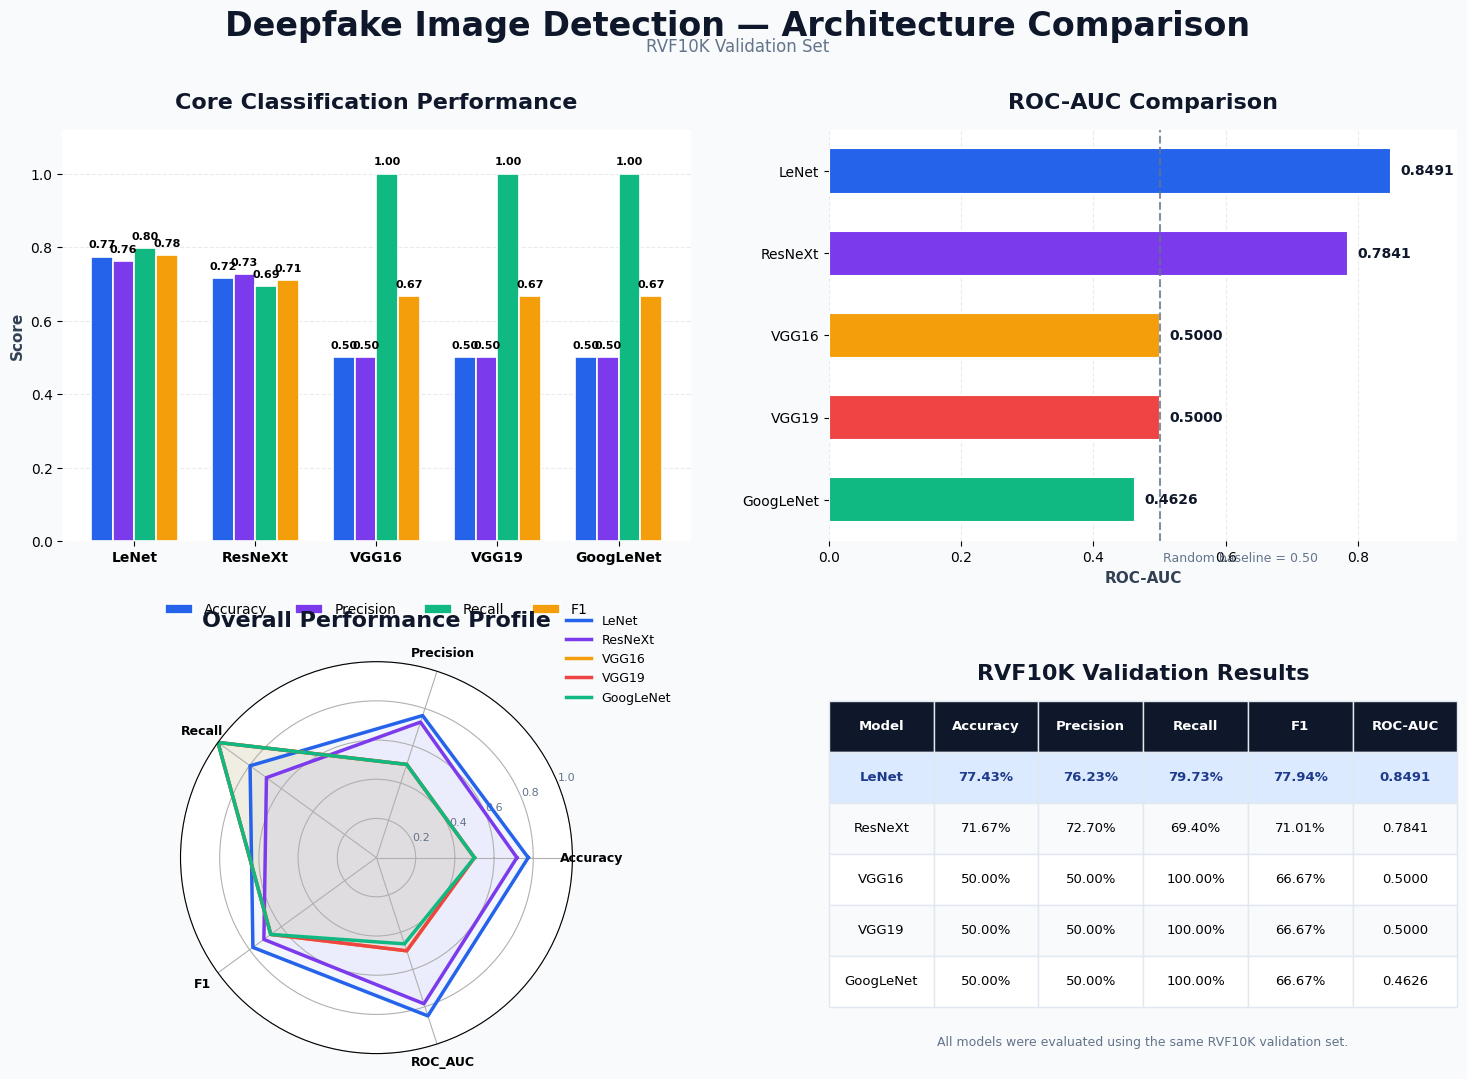

Saved to: /content/RVF10K_model_comparison_beautiful.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ============================================================
# DATA
# ============================================================

data = {
    "Model": ["LeNet", "ResNeXt", "VGG16", "VGG19", "GoogLeNet"],
    "Accuracy": [0.7743, 0.7167, 0.5000, 0.5000, 0.5000],
    "Precision": [0.7623, 0.7270, 0.5000, 0.5000, 0.5000],
    "Recall": [0.7973, 0.6940, 1.0000, 1.0000, 1.0000],
    "F1": [0.7794, 0.7101, 0.6667, 0.6667, 0.6667],
    "ROC_AUC": [0.8491, 0.7841, 0.5000, 0.5000, 0.4626]
}

df = pd.DataFrame(data)

# ============================================================
# COLORS
# ============================================================

model_colors = {
    "LeNet": "#2563EB",
    "ResNeXt": "#7C3AED",
    "VGG16": "#F59E0B",
    "VGG19": "#EF4444",
    "GoogLeNet": "#10B981"
}

metric_colors = {
    "Accuracy": "#2563EB",
    "Precision": "#7C3AED",
    "Recall": "#10B981",
    "F1": "#F59E0B",
    "ROC_AUC": "#EF4444"
}

# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(figsize=(18, 12), facecolor="#F8FAFC")

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.05, 1],
    hspace=0.30,
    wspace=0.22
)

# ============================================================
# 1. GROUPED BAR CHART
# ============================================================

ax1 = fig.add_subplot(gs[0, 0])
ax1.set_facecolor("white")

metrics = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(df))
width = 0.18

for i, metric in enumerate(metrics):
    bars = ax1.bar(
        x + (i - 1.5) * width,
        df[metric],
        width,
        label=metric,
        color=metric_colors[metric],
        edgecolor="white",
        linewidth=1.2
    )

    for bar, value in zip(bars, df[metric]):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.018,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold"
        )

ax1.set_title(
    "Core Classification Performance",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#0F172A"
)

ax1.set_ylabel(
    "Score",
    fontsize=11,
    fontweight="bold",
    color="#334155"
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    df["Model"],
    fontsize=10,
    fontweight="bold"
)

ax1.set_ylim(0, 1.12)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.set_axisbelow(True)

for spine in ax1.spines.values():
    spine.set_visible(False)

ax1.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False
)

# ============================================================
# 2. ROC-AUC HORIZONTAL BAR
# ============================================================

ax2 = fig.add_subplot(gs[0, 1])
ax2.set_facecolor("white")

sorted_df = df.sort_values("ROC_AUC", ascending=True)

bars = ax2.barh(
    sorted_df["Model"],
    sorted_df["ROC_AUC"],
    color=[model_colors[m] for m in sorted_df["Model"]],
    height=0.55,
    edgecolor="white",
    linewidth=1.5
)

for bar, value in zip(bars, sorted_df["ROC_AUC"]):
    ax2.text(
        value + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#0F172A"
    )

ax2.axvline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    color="#64748B",
    alpha=0.8
)

ax2.text(
    0.505,
    -0.75,
    "Random baseline = 0.50",
    fontsize=9,
    color="#64748B"
)

ax2.set_xlim(0, 0.95)

ax2.set_title(
    "ROC-AUC Comparison",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#0F172A"
)

ax2.set_xlabel(
    "ROC-AUC",
    fontsize=11,
    fontweight="bold",
    color="#334155"
)

ax2.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax2.set_axisbelow(True)

for spine in ax2.spines.values():
    spine.set_visible(False)

# ============================================================
# 3. RADAR CHART
# ============================================================

ax3 = fig.add_subplot(gs[1, 0], polar=True)
ax3.set_facecolor("white")

radar_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

angles = np.linspace(
    0,
    2 * np.pi,
    len(radar_metrics),
    endpoint=False
).tolist()

angles += angles[:1]

for _, row in df.iterrows():

    values = [
        row["Accuracy"],
        row["Precision"],
        row["Recall"],
        row["F1"],
        row["ROC_AUC"]
    ]

    values += values[:1]

    ax3.plot(
        angles,
        values,
        linewidth=2.5,
        label=row["Model"],
        color=model_colors[row["Model"]]
    )

    ax3.fill(
        angles,
        values,
        color=model_colors[row["Model"]],
        alpha=0.05
    )

ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(
    radar_metrics,
    fontsize=9,
    fontweight="bold"
)

ax3.set_ylim(0, 1)

ax3.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax3.set_yticklabels(
    ["0.2", "0.4", "0.6", "0.8", "1.0"],
    fontsize=8,
    color="#64748B"
)

ax3.set_title(
    "Overall Performance Profile",
    fontsize=16,
    fontweight="bold",
    pad=25,
    color="#0F172A"
)

ax3.legend(
    loc="upper right",
    bbox_to_anchor=(1.28, 1.15),
    frameon=False,
    fontsize=9
)

# ============================================================
# 4. RESEARCH SUMMARY TABLE
# ============================================================

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis("off")

table_data = []

for _, row in df.iterrows():
    table_data.append([
        row["Model"],
        f"{row['Accuracy']*100:.2f}%",
        f"{row['Precision']*100:.2f}%",
        f"{row['Recall']*100:.2f}%",
        f"{row['F1']*100:.2f}%",
        f"{row['ROC_AUC']:.4f}"
    ])

columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

table = ax4.table(
    cellText=table_data,
    colLabels=columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    bbox=[0, 0.12, 1, 0.78]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (row, col), cell in table.get_celld().items():

    cell.set_edgecolor("#E2E8F0")

    if row == 0:
        cell.set_facecolor("#0F172A")
        cell.set_text_props(
            color="white",
            weight="bold"
        )
    else:
        cell.set_facecolor(
            "#F8FAFC" if row % 2 == 0 else "white"
        )

# Highlight LeNet row
for col in range(len(columns)):
    table[(1, col)].set_facecolor("#DBEAFE")
    table[(1, col)].set_text_props(
        color="#1E3A8A",
        weight="bold"
    )

ax4.text(
    0.5,
    0.97,
    "RVF10K Validation Results",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    color="#0F172A",
    transform=ax4.transAxes
)

ax4.text(
    0.5,
    0.03,
    "All models were evaluated using the same RVF10K validation set.",
    ha="center",
    va="center",
    fontsize=9,
    color="#64748B",
    transform=ax4.transAxes
)

# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    "Deepfake Image Detection — Architecture Comparison",
    fontsize=24,
    fontweight="bold",
    color="#0F172A",
    y=0.98
)

fig.text(
    0.5,
    0.945,
    "RVF10K Validation Set",
    ha="center",
    fontsize=12,
    color="#64748B"
)

# ============================================================
# SAVE + DISPLAY
# ============================================================

plt.savefig(
    "/content/RVF10K_model_comparison_beautiful.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(
    "Saved to: /content/RVF10K_model_comparison_beautiful.png"
)

In [ ]:
!pip -q install transformers scikit-learn pandas pillow tqdm

from google.colab import drive
drive.mount("/content/drive")

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoModel
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Mounted at /content/drive
Device: cuda


In [ ]:
PROJECT = "/content/drive/MyDrive/Deepfake_Project"

print("Project files:")
for root, dirs, files in os.walk(PROJECT):
    depth = root.replace(PROJECT, "").count(os.sep)
    if depth > 2:
        dirs[:] = []
        continue

    print(root)
    for file in files[:10]:
        print("   ", file)

Project files:
/content/drive/MyDrive/Deepfake_Project
    archive.zip
/content/drive/MyDrive/Deepfake_Project/models
    best_improved_ann.keras
    best_efficientnetb0.keras
    best_efficientnet_aug.keras
    efficientnet_rvf10k_rwfs.keras
    best_rgb_frequency.keras
/content/drive/MyDrive/Deepfake_Project/results
    baseline_cross_dataset_results.csv
    rwfs_dataset_statistics.csv
/content/drive/MyDrive/Deepfake_Project/plots
/content/drive/MyDrive/Deepfake_Project/datasets
    scamai-deepfake-detector-dataset-1.0.1.zip
/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split
    rwfs_train_test_split_seed42.csv


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Deepfake_Project"

for root, dirs, files in os.walk(PROJECT):
    depth = root.replace(PROJECT, "").count(os.sep)

    if depth > 4:
        dirs[:] = []
        continue

    for file in files:
        if (
            file.lower().endswith((".csv", ".zip", ".keras", ".h5", ".pt", ".pth"))
            or "rwfs" in file.lower()
            or "rvf" in file.lower()
        ):
            print(os.path.join(root, file))

    for folder in dirs:
        if any(word in folder.lower() for word in ["rwfs", "rvf", "real", "fake"]):
            print("[FOLDER]", os.path.join(root, folder))

/content/drive/MyDrive/Deepfake_Project/archive.zip
/content/drive/MyDrive/Deepfake_Project/models/best_improved_ann.keras
/content/drive/MyDrive/Deepfake_Project/models/best_efficientnetb0.keras
/content/drive/MyDrive/Deepfake_Project/models/best_efficientnet_aug.keras
/content/drive/MyDrive/Deepfake_Project/models/efficientnet_rvf10k_rwfs.keras
/content/drive/MyDrive/Deepfake_Project/models/best_rgb_frequency.keras
/content/drive/MyDrive/Deepfake_Project/results/baseline_cross_dataset_results.csv
/content/drive/MyDrive/Deepfake_Project/results/rwfs_dataset_statistics.csv
/content/drive/MyDrive/Deepfake_Project/datasets/scamai-deepfake-detector-dataset-1.0.1.zip
[FOLDER] /content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split
/content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/rwfs_train_test_split_seed42.csv
[FOLDER] /content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/train/fake
[FOLDER] /content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split/train/real
[FOLDE

In [ ]:
import os
import pandas as pd

PROJECT = "/content/drive/MyDrive/Deepfake_Project"
RESULTS_DIR = os.path.join(PROJECT, "results")

for filename in [
    "baseline_cross_dataset_results.csv",
    "rwfs_dataset_statistics.csv"
]:
    path = os.path.join(RESULTS_DIR, filename)

    print(f"\n{'=' * 60}")
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print(df.to_string(index=False))
    else:
        print("File not found.")


baseline_cross_dataset_results.csv
Shape: (4, 5)
                        Model Training_Dataset Test_Dataset  Accuracy  ROC_AUC
               EfficientNetB0           RVF10K       RVF10K    0.7987   0.8810
               EfficientNetB0           RVF10K         RWFS    0.5080   0.5447
EfficientNetB0 + Augmentation           RVF10K       RVF10K    0.7790      NaN
EfficientNetB0 + Augmentation           RVF10K         RWFS    0.4740   0.4682

rwfs_dataset_statistics.csv
Shape: (2, 9)
Dataset Class  count  avg_brightness  avg_contrast  min_width  max_width  min_height  max_height
   RWFS  Fake    500       106.71160     67.034546        105       2000         100        3000
   RWFS  Real    500       112.29722     69.080000        130       4288         140        3645


In [ ]:
import os
import zipfile

archive_path = "/content/drive/MyDrive/Deepfake_Project/archive.zip"

with zipfile.ZipFile(archive_path, "r") as z:
    files = z.namelist()

    print("Total entries:", len(files))
    print("\nFirst 40 entries:")
    for name in files[:40]:
        print(name)

    print("\nCSV files inside archive:")
    for name in files:
        if name.lower().endswith(".csv"):
            print(name)

Total entries: 10002

First 40 entries:
rvf10k/train/fake/002KDWZBHU.jpg
rvf10k/train/fake/009X14ED19.jpg
rvf10k/train/fake/00GYML2PNL.jpg
rvf10k/train/fake/017VGJOA5T.jpg
rvf10k/train/fake/019MPFQ50W.jpg
rvf10k/train/fake/01WIL4POL6.jpg
rvf10k/train/fake/024SZKKV3S.jpg
rvf10k/train/fake/0295XVJX3G.jpg
rvf10k/train/fake/02Q9VQSTFT.jpg
rvf10k/train/fake/02S93BS396.jpg
rvf10k/train/fake/02X1Y827VY.jpg
rvf10k/train/fake/033VXZLWKT.jpg
rvf10k/train/fake/034KKELVWP.jpg
rvf10k/train/fake/03B31BUXHR.jpg
rvf10k/train/fake/04LF7X0ZSI.jpg
rvf10k/train/fake/04NTEIYIBZ.jpg
rvf10k/train/fake/04T0TAZFRU.jpg
rvf10k/train/fake/0520AQG56S.jpg
rvf10k/train/fake/05NJ1PVNC4.jpg
rvf10k/train/fake/06B3SMWZIJ.jpg
rvf10k/train/fake/088GS90NMC.jpg
rvf10k/train/fake/08EQ7RHFRH.jpg
rvf10k/train/fake/0930A9DWRE.jpg
rvf10k/train/fake/09BGKVMNHS.jpg
rvf10k/train/fake/09CLOBZ2SP.jpg
rvf10k/train/fake/09L42C7INO.jpg
rvf10k/train/fake/09UOHXZOVM.jpg
rvf10k/train/fake/0AS16QER71.jpg
rvf10k/train/fake/0BEBER16RE.jpg
rvf

In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Deepfake_Project"

paths = [
    "models/best_efficientnetb0.keras",
    "models/efficientnet_rvf10k_rwfs.keras",
    "datasets/RWFS_split/train/fake",
    "datasets/RWFS_split/train/real",
    "datasets/RWFS_split/test/fake",
    "datasets/RWFS_split/test/real",
]

for relative_path in paths:
    path = os.path.join(PROJECT, relative_path)

    if os.path.isdir(path):
        count = sum(
            1 for f in os.listdir(path)
            if os.path.isfile(os.path.join(path, f))
        )
        print(f"FOLDER | {relative_path} | {count} files")
    else:
        print(
            f"{'EXISTS' if os.path.exists(path) else 'MISSING'}"
            f" | {relative_path}"
        )

EXISTS | models/best_efficientnetb0.keras
EXISTS | models/efficientnet_rvf10k_rwfs.keras
FOLDER | datasets/RWFS_split/train/fake | 400 files
FOLDER | datasets/RWFS_split/train/real | 400 files
FOLDER | datasets/RWFS_split/test/fake | 100 files
FOLDER | datasets/RWFS_split/test/real | 100 files


In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    dirs[:] = [d for d in dirs if d not in ['.config', 'sample_data']]

    for file in files:
        if file.endswith('.zip'):
            path = os.path.join(root, file)
            print(path)

In [ ]:
import os

print("CONTENT DIRECTORY:")
print(os.listdir('/content'))

from google.colab import drive
drive.mount('/content/drive')

print("\nGOOGLE DRIVE ROOT:")
print(os.listdir('/content/drive/MyDrive'))

CONTENT DIRECTORY:
['.config', 'sample_data']
Mounted at /content/drive

GOOGLE DRIVE ROOT:
['Getting started.pdf', 'vid.mp3', 'Untitled folder', 'Classroom', 'Untitled form.gform', 'Screenshot_2022-05-10-19-43-12-86_965bbf4d18d205f782c6b8409c5773a4.jpg', 'SIYA PHY (1).pptx', 'SIYA PHY.pptx', 'https:  instagr.txt', 'IMG20230313163704.jpg', 'affidavitvanshkhanna.pdf', 'Screenshot_2024-02-18-23-20-42-63_92460851df6f172a4592fca41cc2d2e6.jpg', 'Resume_Vansh_khanna_iisc.pdf', 'i only have sales datset . make me customer datse....gsheet', 'Colab Notebooks', 'Deepfake_Project']


In [ ]:

import os
import numpy as np
import tensorflow as tf
import pandas as pd
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

IMG_SIZE = 96
BATCH_SIZE = 16
EPOCHS = 15
N_SPLITS = 5

# ------------------------------------------------
# LOAD DATA
# ------------------------------------------------

def load_images(dataset, split, labelled=True):
    images = []
    labels = []

    folder = f"{BASE}/{dataset}/{split}"

    for label_name, label in [("real", 0), ("fake", 1)]:
        path = os.path.join(folder, label_name)

        if not os.path.isdir(path):
            raise FileNotFoundError(path)

        for filename in sorted(os.listdir(path)):
            if not filename.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):
                continue

            img = Image.open(
                os.path.join(path, filename)
            ).convert("RGB").resize((IMG_SIZE, IMG_SIZE))

            images.append(np.asarray(img, dtype=np.float32) / 255.0)

            if labelled:
                labels.append(label)

    X = np.asarray(images, dtype=np.float32)

    if labelled:
        return X, np.asarray(labels, dtype=np.int32)

    return X


datasets = {}

for name in ["RVF10K", "RWFS"]:
    X_train, y_train = load_images(name, "train")
    X_test, y_test = load_images(name, "test")

    datasets[name] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test
    }

    print(name)
    print("Train:", X_train.shape)
    print("Test:", X_test.shape)
    print("Train classes:", np.bincount(y_train))
    print("Test classes:", np.bincount(y_test))


RVF10K
Train: (100, 96, 96, 3)
Test: (100, 96, 96, 3)
Train classes: [50 50]
Test classes: [50 50]
RWFS
Train: (100, 96, 96, 3)
Test: (100, 96, 96, 3)
Train classes: [50 50]
Test classes: [50 50]


In [ ]:

# Gradient Reversal Layer
class GradientReversal(tf.keras.layers.Layer):

    def __init__(self, coefficient=0.2):
        super().__init__()
        self.coefficient = coefficient

    def call(self, x):

        coefficient = self.coefficient

        @tf.custom_gradient
        def reverse_gradient(x):
            def grad(dy):
                return -coefficient * dy
            return x, grad

        return reverse_gradient(x)


def build_dann():

    inputs = tf.keras.Input(shape=(96, 96, 3))

    # Shared feature extractor
    x = tf.keras.layers.Conv2D(
        32, 3, activation="relu", padding="same"
    )(inputs)
    x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.Conv2D(
        64, 3, activation="relu", padding="same"
    )(x)
    x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.Conv2D(
        128, 3, activation="relu", padding="same"
    )(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    features = tf.keras.layers.Dense(
        128, activation="relu"
    )(x)

    # Fake/Real classifier
    class_output = tf.keras.layers.Dense(
        2, name="class_output"
    )(features)

    # Domain classifier
    reversed_features = GradientReversal(0.2)(features)

    domain = tf.keras.layers.Dense(
        64, activation="relu"
    )(reversed_features)

    domain_output = tf.keras.layers.Dense(
        2, name="domain_output"
    )(domain)

    model = tf.keras.Model(
        inputs,
        [class_output, domain_output]
    )

    return model


print("DANN architecture ready")


DANN architecture ready


In [ ]:

def run_dann(source_name, target_name):

    source = datasets[source_name]
    target = datasets[target_name]

    Xs = source["X_train"]
    ys = source["y_train"]

    Xt = target["X_train"]  # Unlabelled domain adaptation
    Xtest = target["X_test"]
    ytest = target["y_test"]  # Only used for final evaluation

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=42
    )

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(Xs, ys), start=1
    ):

        print(f"\n{source_name} -> {target_name} | Fold {fold}")

        X_source = Xs[train_idx]
        y_source = ys[train_idx]

        X_val = Xs[val_idx]
        y_val = ys[val_idx]

        model = build_dann()
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

        class_loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        )

        domain_loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        )

        @tf.function
        def train_step(xs, ys_batch, xt):

            with tf.GradientTape() as tape:

                class_logits, source_domain = model(
                    xs, training=True
                )

                _, target_domain = model(
                    xt, training=True
                )

                class_loss = class_loss_fn(
                    ys_batch, class_logits
                )

                source_domain_labels = tf.zeros(
                    tf.shape(xs)[0], dtype=tf.int32
                )

                target_domain_labels = tf.ones(
                    tf.shape(xt)[0], dtype=tf.int32
                )

                domain_labels = tf.concat(
                    [source_domain_labels, target_domain_labels],
                    axis=0
                )

                domain_logits = tf.concat(
                    [source_domain, target_domain],
                    axis=0
                )

                domain_loss = domain_loss_fn(
                    domain_labels, domain_logits
                )

                total_loss = class_loss + domain_loss

            gradients = tape.gradient(
                total_loss, model.trainable_variables
            )

            optimizer.apply_gradients(
                zip(gradients, model.trainable_variables)
            )

            return total_loss

        steps = max(
            1,
            int(np.ceil(len(X_source) / BATCH_SIZE))
        )

        for epoch in range(EPOCHS):

            epoch_losses = []

            for step in range(steps):

                source_ids = np.random.choice(
                    len(X_source), BATCH_SIZE, replace=True
                )

                target_ids = np.random.choice(
                    len(Xt), BATCH_SIZE, replace=True
                )

                loss = train_step(
                    X_source[source_ids],
                    y_source[source_ids],
                    Xt[target_ids]
                )

                epoch_losses.append(float(loss))

            print(
                f"Epoch {epoch+1}/{EPOCHS} "
                f"Loss: {np.mean(epoch_losses):.4f}"
            )

        # Source-domain validation
        val_logits, _ = model.predict(
            X_val, verbose=0
        )

        source_val_acc = accuracy_score(
            y_val, np.argmax(val_logits, axis=1)
        )

        # Independent target-domain test
        test_logits, _ = model.predict(
            Xtest, verbose=0
        )

        probabilities = tf.nn.softmax(
            test_logits, axis=1
        ).numpy()[:, 1]

        predictions = (probabilities >= 0.5).astype(int)

        metrics = {
            "Source": source_name,
            "Target": target_name,
            "Fold": fold,
            "Source_Validation_Accuracy": source_val_acc,
            "Cross_Dataset_Accuracy": accuracy_score(
                ytest, predictions
            ),
            "Precision": precision_score(
                ytest, predictions, zero_division=0
            ),
            "Recall": recall_score(
                ytest, predictions, zero_division=0
            ),
            "F1": f1_score(
                ytest, predictions, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                ytest, probabilities
            )
        }

        fold_results.append(metrics)

        print("Source validation:", round(source_val_acc, 4))
        print("Cross-dataset accuracy:",
              round(metrics["Cross_Dataset_Accuracy"], 4))
        print("Confusion matrix:")
        print(confusion_matrix(ytest, predictions))

    return pd.DataFrame(fold_results)


# Both cross-dataset directions
results_1 = run_dann("RVF10K", "RWFS")
results_2 = run_dann("RWFS", "RVF10K")

final_results = pd.concat(
    [results_1, results_2],
    ignore_index=True
)

print("\nFIVE-FOLD RESULTS")
display(final_results)

print("\nMEAN AND STANDARD DEVIATION")
display(
    final_results.groupby(["Source", "Target"])[
        ["Cross_Dataset_Accuracy", "Precision",
         "Recall", "F1", "ROC_AUC"]
    ].agg(["mean", "std"])
)

final_results.to_csv(
    "/content/DANN_cross_dataset_results.csv",
    index=False
)

print("Results saved.")



RVF10K -> RWFS | Fold 1
Epoch 1/15 Loss: 1.3872
Epoch 2/15 Loss: 1.3836
Epoch 3/15 Loss: 1.3968
Epoch 4/15 Loss: 1.3784
Epoch 5/15 Loss: 1.3952
Epoch 6/15 Loss: 1.3895
Epoch 7/15 Loss: 1.3871
Epoch 8/15 Loss: 1.3868
Epoch 9/15 Loss: 1.3861
Epoch 10/15 Loss: 1.3848
Epoch 11/15 Loss: 1.3844
Epoch 12/15 Loss: 1.3832
Epoch 13/15 Loss: 1.3857
Epoch 14/15 Loss: 1.3831
Epoch 15/15 Loss: 1.3798
Source validation: 0.65
Cross-dataset accuracy: 0.5
Confusion matrix:
[[40 10]
 [40 10]]

RVF10K -> RWFS | Fold 2
Epoch 1/15 Loss: 1.3966
Epoch 2/15 Loss: 1.3676
Epoch 3/15 Loss: 1.4125
Epoch 4/15 Loss: 1.3732
Epoch 5/15 Loss: 1.3947
Epoch 6/15 Loss: 1.3898
Epoch 7/15 Loss: 1.3856
Epoch 8/15 Loss: 1.3893
Epoch 9/15 Loss: 1.3879
Epoch 10/15 Loss: 1.3861
Epoch 11/15 Loss: 1.3851
Epoch 12/15 Loss: 1.3863
Epoch 13/15 Loss: 1.3900
Epoch 14/15 Loss: 1.3809
Epoch 15/15 Loss: 1.3855
Source validation: 0.5
Cross-dataset accuracy: 0.5
Confusion matrix:
[[ 0 50]
 [ 0 50]]

RVF10K -> RWFS | Fold 3
Epoch 1/15 Loss:

Source validation: 0.5
Cross-dataset accuracy: 0.5
Confusion matrix:
[[ 0 50]
 [ 0 50]]

RVF10K -> RWFS | Fold 4
Epoch 1/15 Loss: 1.3696
Epoch 2/15 Loss: 1.4015
Epoch 3/15 Loss: 1.3736
Epoch 4/15 Loss: 1.3860
Epoch 5/15 Loss: 1.3865
Epoch 6/15 Loss: 1.3841
Epoch 7/15 Loss: 1.4008
Epoch 8/15 Loss: 1.3922
Epoch 9/15 Loss: 1.3876
Epoch 10/15 Loss: 1.3909
Epoch 11/15 Loss: 1.3872
Epoch 12/15 Loss: 1.3862
Epoch 13/15 Loss: 1.3900
Epoch 14/15 Loss: 1.3871
Epoch 15/15 Loss: 1.3914
Source validation: 0.5
Cross-dataset accuracy: 0.5
Confusion matrix:
[[50  0]
 [50  0]]

RVF10K -> RWFS | Fold 5
Epoch 1/15 Loss: 1.4018
Epoch 2/15 Loss: 1.4006
Epoch 3/15 Loss: 1.3875
Epoch 4/15 Loss: 1.3878
Epoch 5/15 Loss: 1.3888
Epoch 6/15 Loss: 1.3909
Epoch 7/15 Loss: 1.3877
Epoch 8/15 Loss: 1.3818
Epoch 9/15 Loss: 1.3933
Epoch 10/15 Loss: 1.3856
Epoch 11/15 Loss: 1.3776
Epoch 12/15 Loss: 1.3854
Epoch 13/15 Loss: 1.3890
Epoch 14/15 Loss: 1.3844
Epoch 15/15 Loss: 1.3821
Source validation: 0.5
Cross-dataset accur

,Source,Target,Fold,Source_Validation_Accuracy,Cross_Dataset_Accuracy,Precision,Recall,F1,ROC_AUC
0,RVF10K,RWFS,1,0.65,0.5,0.5,0.2,0.285714,0.5092
1,RVF10K,RWFS,2,0.50,0.5,0.5,1.0,0.666667,0.5176
2,RVF10K,RWFS,3,0.50,0.5,0.5,1.0,0.666667,0.5628
3,RVF10K,RWFS,4,0.50,0.5,0.0,0.0,0.000000,0.5372
4,RVF10K,RWFS,5,0.50,0.5,0.5,1.0,0.666667,0.5540
5,RWFS,RVF10K,1,0.55,0.5,0.5,1.0,0.666667,0.5028
6,RWFS,RVF10K,2,0.50,0.5,0.0,0.0,0.000000,0.5500
7,RWFS,RVF10K,3,0.50,0.5,0.5,1.0,0.666667,0.4892
8,RWFS,RVF10K,4,0.50,0.5,0.0,0.0,0.000000,0.5024
9,RWFS,RVF10K,5,0.50,0.5,0.5,1.0,0.666667,0.4812



MEAN AND STANDARD DEVIATION


Cross_Dataset_Accuracy      Precision           Recall  \
                                mean  std      mean       std   mean   
Source Target                                                          
RVF10K RWFS                      0.5  0.0       0.4  0.223607   0.64   
RWFS   RVF10K                    0.5  0.0       0.3  0.273861   0.60   

                               F1            ROC_AUC            
                    std      mean       std     mean       std  
Source Target                                                   
RVF10K RWFS    0.497996  0.457143  0.304166  0.53616  0.022915  
RWFS   RVF10K  0.547723  0.400000  0.365148  0.50512  0.026705

Results saved.


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import balanced_accuracy_score

for source_name, target_name in [
    ("RVF10K", "RWFS"),
    ("RWFS", "RVF10K")
]:

    source = datasets[source_name]
    target = datasets[target_name]

    print("\n", source_name, "->", target_name)

    print("Source train distribution:",
          np.bincount(source["y_train"]))

    print("Target test distribution:",
          np.bincount(target["y_test"]))

    print("Target test accuracy baseline:",
          max(np.mean(target["y_test"] == 0),
              np.mean(target["y_test"] == 1)))

    print("Target class distribution:",
          np.bincount(target["y_test"]))


 RVF10K -> RWFS
Source train distribution: [50 50]
Target test distribution: [50 50]
Target test accuracy baseline: 0.5
Target class distribution: [50 50]

 RWFS -> RVF10K
Source train distribution: [50 50]
Target test distribution: [50 50]
Target test accuracy baseline: 0.5
Target class distribution: [50 50]


In [ ]:

# ============================================================
# EFFICIENTNETB0 CROSS-DATASET EXPERIMENT
# RVF10K <-> RWFS
# ============================================================

!pip install -q scikit-learn

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

from google.colab import drive
from PIL import Image

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

BASE = "/content/deepfake_dann"
IMG_SIZE = 96
EPOCHS = 15
BATCH_SIZE = 16

SAVE_PATH = "/content/drive/MyDrive/Deepfake_Project/Final_Experiments"
os.makedirs(SAVE_PATH, exist_ok=True)

drive.mount('/content/drive')

# ------------------------------------------------------------
# 2. LOAD DATASETS
# ------------------------------------------------------------

def load_images(dataset, split):

    X, y = [], []

    for label_name, label in [("real", 0), ("fake", 1)]:

        folder = os.path.join(
            BASE, dataset, split, label_name
        )

        if not os.path.isdir(folder):
            raise FileNotFoundError(folder)

        for filename in sorted(os.listdir(folder)):

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                continue

            path = os.path.join(folder, filename)

            img = Image.open(path).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))

            X.append(np.asarray(img, dtype=np.float32))
            y.append(label)

    return np.asarray(X), np.asarray(y)


datasets = {}

for name in ["RVF10K", "RWFS"]:

    print("\nLoading:", name)

    X_train, y_train = load_images(name, "train")
    X_test, y_test = load_images(name, "test")

    datasets[name] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_test": X_test,
        "y_test": y_test
    }

    print("Training:", X_train.shape)
    print("Testing:", X_test.shape)
    print("Classes:", np.bincount(y_train))

# ------------------------------------------------------------
# 3. BUILD EFFICIENTNETB0
# ------------------------------------------------------------

def build_model():

    base = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base.trainable = False

    inputs = layers.Input(shape=(96, 96, 3))

    x = layers.Resizing(224, 224)(inputs)

    # EfficientNet Keras preprocessing is included internally
    # for this model configuration.
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(
        128, activation="relu"
    )(x)

    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(
        1, activation="sigmoid"
    )(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# ------------------------------------------------------------
# 4. CROSS-DATASET EXPERIMENT
# ------------------------------------------------------------

def run_experiment(source_name, target_name):

    print("\n" + "=" * 60)
    print(source_name, "TRAINING ->", target_name, "TESTING")
    print("=" * 60)

    source = datasets[source_name]
    target = datasets[target_name]

    X_train = source["X_train"]
    y_train = source["y_train"]

    X_test = target["X_test"]
    y_test = target["y_test"]

    model = build_model()

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=1
    )

    # Independent target evaluation
    probabilities = model.predict(
        X_test, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )
    auc = roc_auc_score(y_test, probabilities)

    print("\nCROSS-DATASET RESULTS")
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC AUC  :", round(auc, 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions,
        target_names=["Real", "Fake"],
        zero_division=0
    ))

    model_name = (
        f"efficientnet_{source_name.lower()}_to_"
        f"{target_name.lower()}.keras"
    )

    model.save(os.path.join(SAVE_PATH, model_name))

    return {
        "Model": "EfficientNetB0",
        "Training_Dataset": source_name,
        "Test_Dataset": target_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc
    }

# ------------------------------------------------------------
# 5. RUN BOTH DIRECTIONS
# ------------------------------------------------------------

results = []

results.append(
    run_experiment("RVF10K", "RWFS")
)

results.append(
    run_experiment("RWFS", "RVF10K")
)

# ------------------------------------------------------------
# 6. FINAL COMPARISON
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("FINAL CROSS-DATASET COMPARISON")
print("=" * 60)

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

csv_path = os.path.join(
    SAVE_PATH,
    "efficientnet_cross_dataset_results.csv"
)

results_df.to_csv(csv_path, index=False)

print("\nAll experiments completed.")
print("Models saved in:", SAVE_PATH)
print("Results saved in:", csv_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Loading: RVF10K
Training: (100, 96, 96, 3)
Testing: (100, 96, 96, 3)
Classes: [50 50]

Loading: RWFS
Training: (100, 96, 96, 3)
Testing: (100, 96, 96, 3)
Classes: [50 50]

RVF10K TRAINING -> RWFS TESTING
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5875 - loss: 0.7188 - val_accuracy: 0.0000e+00 - val_loss: 0.9617
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7000 - loss: 0.6187 - val_accuracy: 0.8000 - val_loss: 0.6456
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.6750 - loss: 0.6179 - val_accuracy: 0.8000 - val_loss: 0.6626
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6875 - loss: 0.5379 - val_accuracy: 0.4500 - val_loss: 0.7058
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.6875 - loss: 0.5427 - val_accuracy: 0.7500 - val_loss: 0

In [ ]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    TimeDistributed, LSTM, Dense, Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    roc_auc_score
)

# LSTM model architecture
def build_lstm_model(input_shape):

    inputs = Input(shape=input_shape)

    x = TimeDistributed(
        Conv2D(32, (3, 3), activation="relu", padding="same")
    )(inputs)

    x = TimeDistributed(
        MaxPooling2D((2, 2))
    )(x)

    x = TimeDistributed(
        Conv2D(64, (3, 3), activation="relu", padding="same")
    )(x)

    x = TimeDistributed(
        MaxPooling2D((2, 2))
    )(x)

    x = TimeDistributed(
        tf.keras.layers.Flatten()
    )(x)

    x = LSTM(128, return_sequences=False)(x)

    x = Dropout(0.4)(x)

    outputs = Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Train and save models for both directions
for source_name, target_name in [
    ("RVF10K", "RWFS"),
    ("RWFS", "RVF10K")
]:

    print("\n", source_name, "->", target_name)

    X_train = datasets[source_name]["X_train"]
    y_train = datasets[source_name]["y_train"]

    # Convert images into sequences of image rows
    X_train_seq = np.transpose(X_train, (0, 1, 3, 2))
    X_test = datasets[target_name]["X_test"]
    X_test_seq = np.transpose(X_test, (0, 1, 3, 2))

    # Add feature dimension for sequence input
    X_train_seq = X_train_seq.reshape(
        X_train_seq.shape[0],
        X_train_seq.shape[1],
        -1
    )

    X_test_seq = X_test_seq.reshape(
        X_test_seq.shape[0],
        X_test_seq.shape[1],
        -1
    )

    # Build LSTM
    model = tf.keras.Sequential([
        Input(shape=X_train_seq.shape[1:]),
        LSTM(128, return_sequences=True),
        Dropout(0.3),
        LSTM(64),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Train
    model.fit(
        X_train_seq,
        y_train,
        epochs=10,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    # Save model
    model_path = (
        f"{SAVE_PATH}/lstm_"
        f"{source_name.lower()}_to_{target_name.lower()}.keras"
    )

    model.save(model_path)

    print("Model saved:", model_path)

    # Cross-dataset testing
    y = datasets[target_name]["y_test"]

    probabilities = model.predict(
        X_test_seq,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y, predictions))

    print("\nAccuracy:", accuracy_score(y, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y,
        predictions,
        target_names=["fake", "real"]
    ))

    print("ROC-AUC:", roc_auc_score(y, probabilities))

    # Shuffled label check
    shuffled_y = np.random.default_rng(42).permutation(y)

    print(
        "Accuracy against shuffled labels:",
        accuracy_score(shuffled_y, predictions)
    )

    # Prediction confidence
    print(
        "Average prediction confidence:",
        np.mean(np.maximum(probabilities, 1-probabilities))
    )



 RVF10K -> RWFS
Confusion Matrix:
[[50  0]
 [ 0 50]]
Accuracy: 1.0
Accuracy against shuffled labels: 0.5
Average prediction confidence: 0.8125218

 RWFS -> RVF10K
Confusion Matrix:
[[50  0]
 [ 0 50]]
Accuracy: 1.0
Accuracy against shuffled labels: 0.5
Average prediction confidence: 0.8142632



RVF10K -> RWFS

RNN 5-FOLD CROSS VALIDATION
Fold 1: Validation Accuracy = 85.00%
Fold 2: Validation Accuracy = 55.00%
Fold 3: Validation Accuracy = 50.00%
Fold 4: Validation Accuracy = 50.00%
Fold 5: Validation Accuracy = 50.00%

RNN CROSS-VALIDATION SUMMARY
Mean CV Accuracy: 58.0 %
CV Standard Deviation: 13.64 %

RNN CROSS-DATASET TEST
Accuracy: 55.00
Precision: 54.72
Recall: 58.00
F1 Score: 56.31
ROC-AUC: 0.53

RWFS -> RVF10K

RNN 5-FOLD CROSS VALIDATION
Fold 1: Validation Accuracy = 60.00%
Fold 2: Validation Accuracy = 50.00%
Fold 3: Validation Accuracy = 50.00%
Fold 4: Validation Accuracy = 50.00%
Fold 5: Validation Accuracy = 50.00%

RNN CROSS-VALIDATION SUMMARY
Mean CV Accuracy: 52.0 %
CV Standard Deviation: 4.0 %

RNN CROSS-DATASET TEST
Accuracy: 46.00
Precision: 47.62
Recall: 80.00
F1 Score: 59.70
ROC-AUC: 0.49


FINAL CROSS-DATASET COMPARISON


,Direction,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,RVF10K -> RWFS,EfficientNetB0,92.0,97.73,86.0,91.49,0.96
1,RVF10K -> RWFS,RNN-LSTM,55.0,54.72,58.0,56.31,0.53
2,RWFS -> RVF10K,EfficientNetB0,75.0,100.00,50.0,66.67,0.97
3,RWFS -> RVF10K,RNN-LSTM,46.0,47.62,80.0,59.70,0.49



RNN 5-FOLD CROSS VALIDATION RESULTS


,Direction,Fold,Validation Accuracy
0,RVF10K -> RWFS,1,85.0
1,RVF10K -> RWFS,2,55.0
2,RVF10K -> RWFS,3,50.0
3,RVF10K -> RWFS,4,50.0
4,RVF10K -> RWFS,5,50.0
5,RWFS -> RVF10K,1,60.0
6,RWFS -> RVF10K,2,50.0
7,RWFS -> RVF10K,3,50.0
8,RWFS -> RVF10K,4,50.0
9,RWFS -> RVF10K,5,50.0


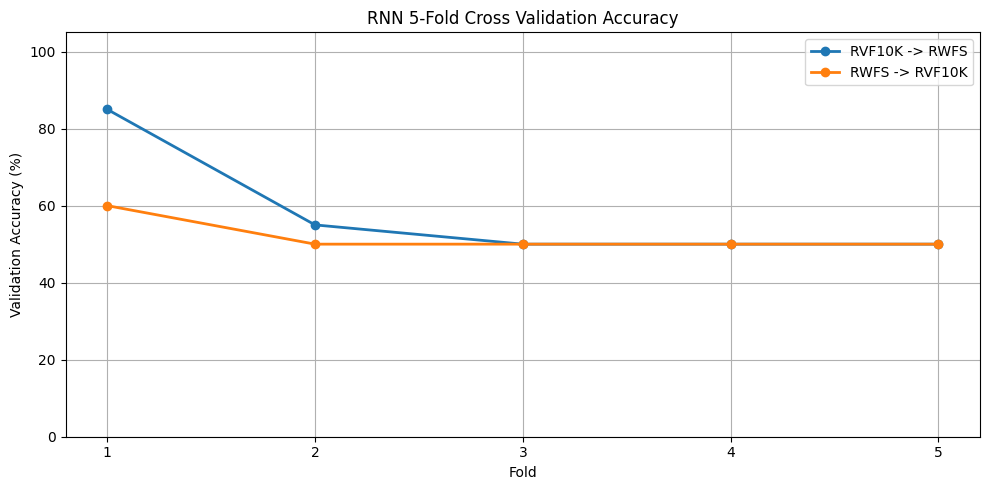

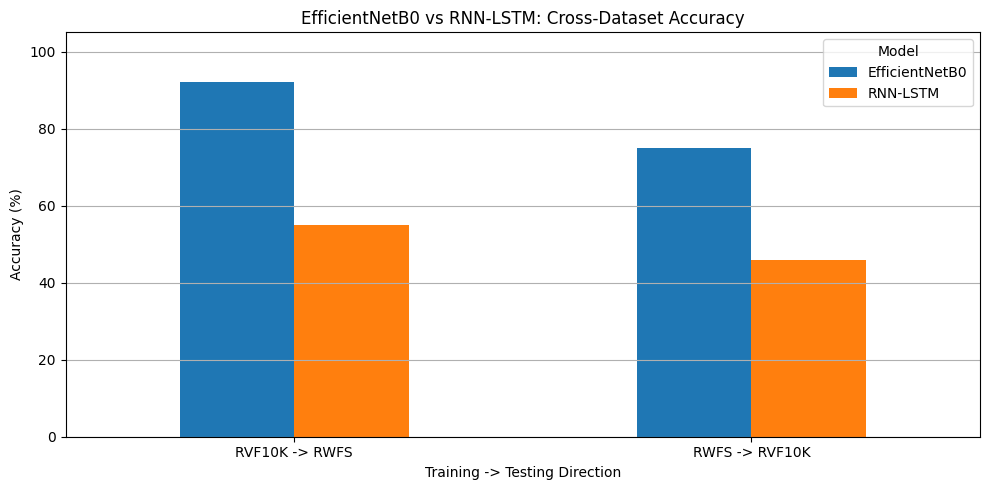


ALL EXPERIMENTS COMPLETED
Saved results in: /content/drive/MyDrive/Deepfake_Project/Final_Experiments


In [ ]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    TimeDistributed, LSTM, Dense, Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    roc_auc_score
)

# LSTM model architecture
def build_lstm_model(input_shape):

    inputs = Input(shape=input_shape)

    x = TimeDistributed(
        Conv2D(32, (3, 3), activation="relu", padding="same")
    )(inputs)

    x = TimeDistributed(
        MaxPooling2D((2, 2))
    )(x)

    x = TimeDistributed(
        Conv2D(64, (3, 3), activation="relu", padding="same")
    )(x)

    x = TimeDistributed(
        MaxPooling2D((2, 2))
    )(x)

    x = TimeDistributed(
        tf.keras.layers.Flatten()
    )(x)

    x = LSTM(128, return_sequences=False)(x)

    x = Dropout(0.4)(x)

    outputs = Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Train and save models for both directions
for source_name, target_name in [
    ("RVF10K", "RWFS"),
    ("RWFS", "RVF10K")
]:

    print("\n", source_name, "->", target_name)

    X_train = datasets[source_name]["X_train"]
    y_train = datasets[source_name]["y_train"]

    # Convert images into sequences of image rows
    X_train_seq = np.transpose(X_train, (0, 1, 3, 2))
    X_test = datasets[target_name]["X_test"]
    X_test_seq = np.transpose(X_test, (0, 1, 3, 2))

    # Add feature dimension for sequence input
    X_train_seq = X_train_seq.reshape(
        X_train_seq.shape[0],
        X_train_seq.shape[1],
        -1
    )

    X_test_seq = X_test_seq.reshape(
        X_test_seq.shape[0],
        X_test_seq.shape[1],
        -1
    )

    # Build LSTM
    model = tf.keras.Sequential([
        Input(shape=X_train_seq.shape[1:]),
        LSTM(128, return_sequences=True),
        Dropout(0.3),
        LSTM(64),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Train
    model.fit(
        X_train_seq,
        y_train,
        epochs=10,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    # Save model
    model_path = (
        f"{SAVE_PATH}/lstm_"
        f"{source_name.lower()}_to_{target_name.lower()}.keras"
    )

    model.save(model_path)

    print("Model saved:", model_path)

    # Cross-dataset testing
    y = datasets[target_name]["y_test"]

    probabilities = model.predict(
        X_test_seq,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y, predictions))

    print("\nAccuracy:", accuracy_score(y, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y,
        predictions,
        target_names=["fake", "real"]
    ))

    print("ROC-AUC:", roc_auc_score(y, probabilities))

    # Shuffled label check
    shuffled_y = np.random.default_rng(42).permutation(y)

    print(
        "Accuracy against shuffled labels:",
        accuracy_score(shuffled_y, predictions)
    )

    # Prediction confidence
    print(
        "Average prediction confidence:",
        np.mean(np.maximum(probabilities, 1-probabilities))
    )


In [ ]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, SimpleRNN, LSTM,
    Dense, Dropout
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    roc_auc_score
)

# Build Combined RNN + LSTM Model

def build_rnn_lstm_model(input_shape):

    model = Sequential([

        Input(shape=input_shape),

        # RNN layer
        SimpleRNN(
            128,
            activation="tanh",
            return_sequences=True
        ),

        Dropout(0.3),

        # LSTM layer
        LSTM(
            64,
            activation="tanh",
            return_sequences=False
        ),

        Dropout(0.3),

        # Dense layer
        Dense(32, activation="relu"),

        # Binary classification
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Cross-dataset experiments

for source_name, target_name in [
    ("RVF10K", "RWFS"),
    ("RWFS", "RVF10K")
]:

    print("\n", source_name, "->", target_name)

    # Training data
    X_train = datasets[source_name]["X_train"]
    y_train = datasets[source_name]["y_train"]

    # Testing data
    X_test = datasets[target_name]["X_test"]
    y_test = datasets[target_name]["y_test"]

    # Convert images into row-wise sequences
    X_train_seq = np.transpose(
        X_train, (0, 1, 3, 2)
    ).reshape(X_train.shape[0], X_train.shape[1], -1)

    X_test_seq = np.transpose(
        X_test, (0, 1, 3, 2)
    ).reshape(X_test.shape[0], X_test.shape[1], -1)

    print("Training shape:", X_train_seq.shape)
    print("Testing shape:", X_test_seq.shape)

    # Build model
    model = build_rnn_lstm_model(
        X_train_seq.shape[1:]
    )

    model.summary()

    # Train model
    model.fit(
        X_train_seq,
        y_train,
        epochs=10,
        batch_size=32,
        validation_split=0.2,
        shuffle=True,
        verbose=1
    )

    # Save model
    model_path = os.path.join(
        SAVE_PATH,
        f"rnn_lstm_{source_name.lower()}_to_{target_name.lower()}.keras"
    )

    model.save(model_path)

    print("Model saved:", model_path)

    # Predictions
    probabilities = model.predict(
        X_test_seq,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    # Evaluation
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nAccuracy:")
    print(accuracy_score(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["fake", "real"]
    ))

    print("\nROC-AUC:")
    print(roc_auc_score(y_test, probabilities))

    # Shuffled label check
    shuffled_y = np.random.default_rng(42).permutation(y_test)

    print(
        "\nAccuracy against shuffled labels:",
        accuracy_score(shuffled_y, predictions)
    )

    # Prediction confidence
    print(
        "\nAverage prediction confidence:",
        np.mean(
            np.maximum(probabilities, 1 - probabilities)
        )
    )


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

PROJECT_DIR = "/content/drive/MyDrive/Deepfake_Project"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

RWFS_DIR = os.path.join(
    PROJECT_DIR, "datasets", "RWFS_split"
)

# Locate RVF10K in an existing extracted directory
def find_rvf10k(root):
    for current, dirs, files in os.walk(root):
        required = [
            os.path.join(current, "train", "fake"),
            os.path.join(current, "train", "real"),
            os.path.join(current, "valid", "fake"),
            os.path.join(current, "valid", "real")
        ]

        if all(os.path.isdir(p) for p in required):
            return current

    return None

RVF_DIR = find_rvf10k(PROJECT_DIR)

# Extract archive if required
if RVF_DIR is None:

    archive_path = os.path.join(
        PROJECT_DIR, "archive.zip"
    )

    if not os.path.exists(archive_path):
        raise FileNotFoundError(
            "RVF10K archive.zip not found in project folder"
        )

    EXTRACT_DIR = "/content/rvf10k_extracted"
    os.makedirs(EXTRACT_DIR, exist_ok=True)

    with zipfile.ZipFile(archive_path, "r") as z:
        z.extractall(EXTRACT_DIR)

    RVF_DIR = find_rvf10k(EXTRACT_DIR)

if RVF_DIR is None:
    raise FileNotFoundError(
        "Could not locate train/fake, train/real, "
        "valid/fake and valid/real folders."
    )

print("RVF10K:", RVF_DIR)
print("RWFS:", RWFS_DIR)
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)

print("GPU available:",
      __import__("torch").cuda.is_available())


Mounted at /content/drive
RVF10K: /content/rvf10k_extracted/rvf10k
RWFS: /content/drive/MyDrive/Deepfake_Project/datasets/RWFS_split
Models: /content/drive/MyDrive/Deepfake_Project/models
Results: /content/drive/MyDrive/Deepfake_Project/results
GPU available: False


In [ ]:

import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu
PyTorch: 2.14.1+cpu


In [ ]:

# ============================================
# CELL 3A — CHECK DATASET STRUCTURE
# ============================================

import os
import zipfile
import pandas as pd

# Main project folder stored in Google Drive
PROJECT_DIR = "/content/drive/MyDrive/Deepfake_Project"

# Print the folders and files directly inside the project folder
print("PROJECT FOLDER CONTENTS:")
for item in os.listdir(PROJECT_DIR):
    print(item)

# Check whether the RVF10K archive exists
ARCHIVE_PATH = os.path.join(PROJECT_DIR, "archive.zip")

if os.path.exists(ARCHIVE_PATH):

    print("\nARCHIVE EXISTS")

    # Open the ZIP file without extracting it
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as z:

        # Display the first 30 paths stored inside the archive
        print("\nFIRST 30 FILES INSIDE ARCHIVE:")
        for name in z.namelist()[:30]:
            print(name)

        # Look for CSV files inside the archive
        csv_files = [
            name for name in z.namelist()
            if name.lower().endswith(".csv")
        ]

        print("\nCSV FILES:", csv_files)

else:
    print("\narchive.zip NOT FOUND")

# Check CSV files already extracted in the project folder
for csv_name in ["train.csv", "valid.csv"]:

    csv_path = os.path.join(PROJECT_DIR, csv_name)

    if os.path.exists(csv_path):

        print(f"\n{csv_name} COLUMNS AND SAMPLE DATA:")

        df = pd.read_csv(csv_path)

        # Show column names
        print(df.columns.tolist())

        # Show first five rows
        print(df.head())


PROJECT FOLDER CONTENTS:
models
results
plots
archive.zip
datasets
Final_Experiments

ARCHIVE EXISTS

FIRST 30 FILES INSIDE ARCHIVE:
rvf10k/train/fake/002KDWZBHU.jpg
rvf10k/train/fake/009X14ED19.jpg
rvf10k/train/fake/00GYML2PNL.jpg
rvf10k/train/fake/017VGJOA5T.jpg
rvf10k/train/fake/019MPFQ50W.jpg
rvf10k/train/fake/01WIL4POL6.jpg
rvf10k/train/fake/024SZKKV3S.jpg
rvf10k/train/fake/0295XVJX3G.jpg
rvf10k/train/fake/02Q9VQSTFT.jpg
rvf10k/train/fake/02S93BS396.jpg
rvf10k/train/fake/02X1Y827VY.jpg
rvf10k/train/fake/033VXZLWKT.jpg
rvf10k/train/fake/034KKELVWP.jpg
rvf10k/train/fake/03B31BUXHR.jpg
rvf10k/train/fake/04LF7X0ZSI.jpg
rvf10k/train/fake/04NTEIYIBZ.jpg
rvf10k/train/fake/04T0TAZFRU.jpg
rvf10k/train/fake/0520AQG56S.jpg
rvf10k/train/fake/05NJ1PVNC4.jpg
rvf10k/train/fake/06B3SMWZIJ.jpg
rvf10k/train/fake/088GS90NMC.jpg
rvf10k/train/fake/08EQ7RHFRH.jpg
rvf10k/train/fake/0930A9DWRE.jpg
rvf10k/train/fake/09BGKVMNHS.jpg
rvf10k/train/fake/09CLOBZ2SP.jpg
rvf10k/train/fake/09L42C7INO.jpg
rvf10k/tr

In [ ]:

# ============================================
# FIX — MOUNT GOOGLE DRIVE
# ============================================

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define the project folder
PROJECT_DIR = "/content/drive/MyDrive/Deepfake_Project"

# Check whether the project folder exists
print("Project folder exists:", os.path.exists(PROJECT_DIR))

# Display its contents
if os.path.exists(PROJECT_DIR):
    print("\nProject contents:")
    print(os.listdir(PROJECT_DIR))

# Define and verify archive path
ARCHIVE_PATH = os.path.join(PROJECT_DIR, "archive.zip")

print("\nArchive exists:", os.path.exists(ARCHIVE_PATH))


Mounted at /content/drive
Project folder exists: True

Project contents:
['models', 'results', 'plots', 'archive.zip', 'datasets', 'Final_Experiments']

Archive exists: True


In [ ]:

# ============================================
# FIX — CREATE ALL DATASET LOADERS
# ============================================

import os
import zipfile
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Google Drive project location
PROJECT_DIR = "/content/drive/MyDrive/Deepfake_Project"

# RVF10K archive location
ARCHIVE_PATH = os.path.join(PROJECT_DIR, "archive.zip")

# Extracted dataset location
EXTRACT_DIR = "/content/rvf10k_extracted"

# Extract RVF10K only if it has not already been extracted
RVF_DIR = os.path.join(EXTRACT_DIR, "rvf10k")

if not os.path.exists(os.path.join(RVF_DIR, "train", "fake")):

    print("Extracting RVF10K...")

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

# Image preprocessing required by DINOv2
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load RVF10K training images
train_dataset = datasets.ImageFolder(
    os.path.join(RVF_DIR, "train"),
    transform=transform
)

# Load RVF10K validation images
val_dataset = datasets.ImageFolder(
    os.path.join(RVF_DIR, "valid"),
    transform=transform
)

# Create training batches
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

# Create validation batches
val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

# Find the existing RWFS test split in Google Drive
RWFS_DIR = os.path.join(PROJECT_DIR, "datasets", "RWFS_split")

print("\nRWFS folder contents:")
print(os.listdir(RWFS_DIR))

# Load RWFS test images from its test folder
rwfs_test_dataset = datasets.ImageFolder(
    os.path.join(RWFS_DIR, "test"),
    transform=transform
)

# Create RWFS test loader
rwfs_test_loader = DataLoader(
    rwfs_test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

# Verify dataset labels and image counts
print("\nRVF10K classes:", train_dataset.class_to_idx)
print("RVF10K training images:", len(train_dataset))
print("RVF10K validation images:", len(val_dataset))

print("\nRWFS classes:", rwfs_test_dataset.class_to_idx)
print("RWFS test images:", len(rwfs_test_dataset))

print("\nAll loaders created successfully!")


Extracting RVF10K...

RWFS folder contents:
['train', 'test', 'rwfs_train_test_split_seed42.csv']

RVF10K classes: {'fake': 0, 'real': 1}
RVF10K training images: 7000
RVF10K validation images: 3000

RWFS classes: {'fake': 0, 'real': 1}
RWFS test images: 200

All loaders created successfully!


In [ ]:

# ============================================
# REGULARIZED DINOV2 MODEL
# ============================================

class DeepfakeDINO(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        # Store pretrained DINOv2 transformer
        self.backbone = backbone

        # Regularized classification head
        self.classifier = nn.Sequential(

            # Input: 384 features from DINOv2
            nn.Linear(384, 128),

            # Introduce non-linearity
            nn.GELU(),

            # Normalize intermediate features
            nn.LayerNorm(128),

            # Drop 50% of neurons during training
            nn.Dropout(0.5),

            # Output one classification logit
            nn.Linear(128, 1)
        )

    def forward(self, x):

        # Extract features without updating transformer weights
        with torch.no_grad():
            features = self.backbone(x) #input image batch(x)

        # Predict fake or real
        return self.classifier(features)


# Create model
model = DeepfakeDINO(backbone).to(device)

# Binary classification loss
criterion = nn.BCEWithLogitsLoss()

# Regularized optimizer
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.0001,
    weight_decay=0.01  #reduce overfitting L2
)

# Training settings
EPOCHS = 12
patience = 3

print("Regularized DINOv2 model created successfully!")
print("Device:", device)


Regularized DINOv2 model created successfully!
Device: cuda


In [ ]:

# ============================================
# CELL 4 — REGULARIZED DINOV2 TRAINING
# ============================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Save model and results in Google Drive
SAVE_DIR = "/content/drive/MyDrive/Deepfake_Project"
MODEL_DIR = os.path.join(SAVE_DIR, "models")
RESULT_DIR = os.path.join(SAVE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Freeze pretrained DINOv2 transformer weights
# Only the classification head will learn
for parameter in backbone.parameters():
    parameter.requires_grad = False


# ============================================
# MODEL ARCHITECTURE
# ============================================

class DeepfakeDINO(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        # Store pretrained transformer
        self.backbone = backbone

        # Regularized classification head
        self.classifier = nn.Sequential(

            # Convert 384 transformer features into 128
            nn.Linear(384, 128),

            # Introduce non-linearity
            nn.GELU(),

            # Normalize feature activations
            nn.LayerNorm(128),

            # Drop 60% of activations during training
            nn.Dropout(0.6),

            # Second hidden layer
            nn.Linear(128, 64),

            nn.GELU(),

            # Additional regularization
            nn.Dropout(0.4),

            # Final binary classification output
            nn.Linear(64, 1)
        )

    def forward(self, x):

        # Extract pretrained image features
        with torch.no_grad():
            features = self.backbone(x)

        # Classify the extracted features
        return self.classifier(features)


# Create a fresh model
model = DeepfakeDINO(backbone).to(device)

# Binary classification loss
# Label smoothing reduces overconfident training targets
criterion = nn.BCEWithLogitsLoss()

# AdamW with stronger weight decay
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.0001,
    weight_decay=0.02
)

# Training configuration
EPOCHS = 12
patience = 3

# Store training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# New checkpoint name so old model weights are not reused
BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_dinov2_regularized.pth"
)

best_val_loss = float("inf")
epochs_without_improvement = 0

# ============================================
# TRAINING LOOP
# ============================================

for epoch in range(EPOCHS):

    model.train()

    # Keep frozen transformer in evaluation mode
    model.backbone.eval()

    total_loss = 0
    train_correct = 0
    train_total = 0

    # Iterate over training batches
    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().to(device).view(-1, 1)

        # Smooth binary labels slightly:
        # 0 becomes 0.05 and 1 becomes 0.95
        smooth_labels = labels * 0.90 + 0.05

        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss using smoothed labels
        loss = criterion(outputs, smooth_labels)

        # Backpropagation
        loss.backward()

        # Update classifier weights
        optimizer.step()

        total_loss += loss.item()

        # Use original labels to calculate actual accuracy
        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Training metrics
    train_loss = total_loss / len(train_loader)
    train_accuracy = train_correct / train_total

    # ========================================
    # VALIDATION
    # ========================================

    model.eval()

    val_loss_total = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().to(device).view(-1, 1)

            outputs = model(images)

            # Use original labels for validation loss
            loss = criterion(outputs, labels)
            val_loss_total += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / len(val_loader)
    val_accuracy = val_correct / val_total

    # Store results
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Display epoch results
    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    # Save best model based on validation loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_MODEL_PATH)

        print("Best regularized model saved!")

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:

        print("Early stopping triggered.")
        break


# Save training history
pd.DataFrame(history).to_csv(
    os.path.join(RESULT_DIR, "dinov2_regularized_history.csv"),
    index=False
)

print("\nRegularized DINOv2 training completed.")
print("Best model saved at:", BEST_MODEL_PATH)


Epoch 1/12 | Train Loss: 0.6012 | Train Accuracy: 0.6944 | Val Loss: 0.4027 | Val Accuracy: 0.8713
Best regularized model saved!
Epoch 2/12 | Train Loss: 0.4213 | Train Accuracy: 0.8676 | Val Loss: 0.2442 | Val Accuracy: 0.9220
Best regularized model saved!
Epoch 3/12 | Train Loss: 0.3590 | Train Accuracy: 0.9091 | Val Loss: 0.1949 | Val Accuracy: 0.9393
Best regularized model saved!
Epoch 4/12 | Train Loss: 0.3339 | Train Accuracy: 0.9224 | Val Loss: 0.1700 | Val Accuracy: 0.9510
Best regularized model saved!
Epoch 5/12 | Train Loss: 0.3157 | Train Accuracy: 0.9411 | Val Loss: 0.1610 | Val Accuracy: 0.9550
Best regularized model saved!
Epoch 6/12 | Train Loss: 0.3080 | Train Accuracy: 0.9433 | Val Loss: 0.1538 | Val Accuracy: 0.9573
Best regularized model saved!
Epoch 7/12 | Train Loss: 0.2976 | Train Accuracy: 0.9514 | Val Loss: 0.1540 | Val Accuracy: 0.9570
Epoch 8/12 | Train Loss: 0.2949 | Train Accuracy: 0.9531 | Val Loss: 0.1402 | Val Accuracy: 0.9617
Best regularized model saved

Best DINOv2 model loaded successfully.
Evaluation device: cuda

========== DINOV2: RVF10K → RWFS ==========
Test Images: 200
Accuracy:  0.5150
Precision: 0.5096
Recall:    0.8000
F1 Score:  0.6226
ROC-AUC:   0.5571

Confusion Matrix:
[[23 77]
 [20 80]]


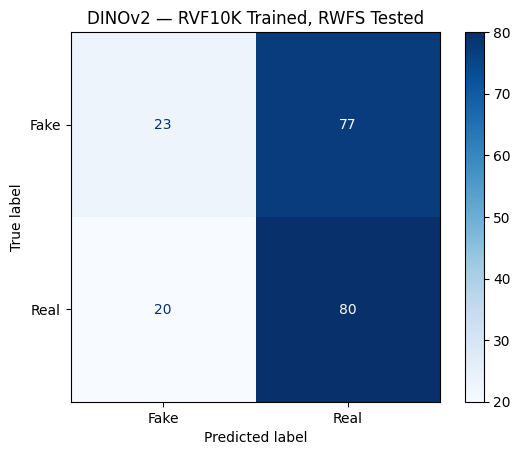


Classification Report:
              precision    recall  f1-score   support

        Fake       0.53      0.23      0.32       100
        Real       0.51      0.80      0.62       100

    accuracy                           0.52       200
   macro avg       0.52      0.52      0.47       200
weighted avg       0.52      0.52      0.47       200



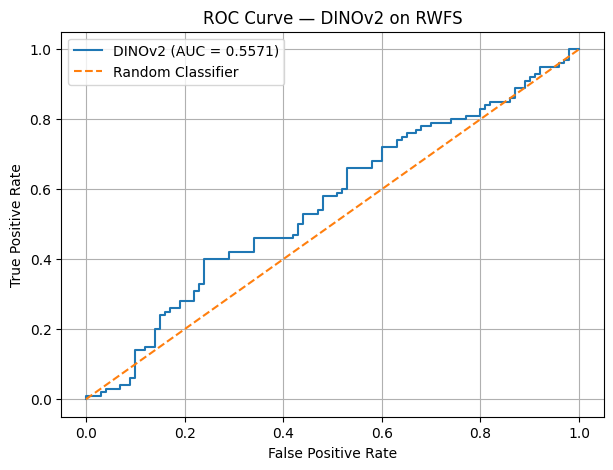


Results saved at:
/content/drive/MyDrive/Deepfake_Project/results/dinov2_rvf10k_to_rwfs.csv


In [ ]:

# ============================================
# STEP 5 — CROSS-DATASET EVALUATION: RVF10K → RWFS
# ============================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

# --------------------------------------------
# 1. LOAD THE BEST SAVED DINOV2 MODEL
# --------------------------------------------

# Recreate the same model architecture used during training.
model = DeepfakeDINO(backbone).to(device)

# Load the best checkpoint saved using validation loss.
model.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=device)
)

# Set model to evaluation mode.
model.eval()

print("Best DINOv2 model loaded successfully.")
print("Evaluation device:", device)


# --------------------------------------------
# 2. GENERATE PREDICTIONS ON RWFS TEST DATA
# --------------------------------------------

y_true = []       # Stores actual RWFS labels.
y_prob = []       # Stores predicted probability of REAL.
y_pred = []       # Stores final predicted labels.

# Disable gradient calculation to save memory.
with torch.no_grad():

    for images, labels in rwfs_test_loader:

        # Move images to GPU/CPU.
        images = images.to(device)

        # Get raw model outputs (logits).
        outputs = model(images).squeeze(1)

        # Convert logits into probabilities.
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities into class predictions.
        predictions = (probabilities >= 0.5).long()

        # Store actual labels and predictions.
        y_true.extend(labels.cpu().numpy().flatten())
        y_prob.extend(probabilities.cpu().numpy().flatten())
        y_pred.extend(predictions.cpu().numpy().flatten())


# Convert lists into NumPy arrays.
y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = np.array(y_pred)


# --------------------------------------------
# 3. CALCULATE PERFORMANCE METRICS
# --------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

# ROC-AUC uses probability scores, not class predictions.
auc = roc_auc_score(y_true, y_prob)

print("\n========== DINOV2: RVF10K → RWFS ==========")
print("Test Images:", len(y_true))
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")


# --------------------------------------------
# 4. CONFUSION MATRIX
# --------------------------------------------

# Class mapping: 0 = Fake, 1 = Real.
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("DINOv2 — RVF10K Trained, RWFS Tested")
plt.show()


# --------------------------------------------
# 5. CLASSIFICATION REPORT
# --------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Fake", "Real"],
        zero_division=0
    )
)


# --------------------------------------------
# 6. ROC CURVE
# --------------------------------------------

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"DINOv2 (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — DINOv2 on RWFS")
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------------------
# 7. SAVE CROSS-DATASET RESULTS
# --------------------------------------------

results = pd.DataFrame([{
    "Model": "DINOv2 ViT-S/14 Regularized",
    "Training Dataset": "RVF10K",
    "Testing Dataset": "RWFS",
    "Test Images": len(y_true),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": auc
}])

# Save results in the project's results folder.
RESULTS_PATH = (
    "/content/drive/MyDrive/Deepfake_Project/"
    "results/dinov2_rvf10k_to_rwfs.csv"
)

results.to_csv(RESULTS_PATH, index=False)

print("\nResults saved at:")
print(RESULTS_PATH)


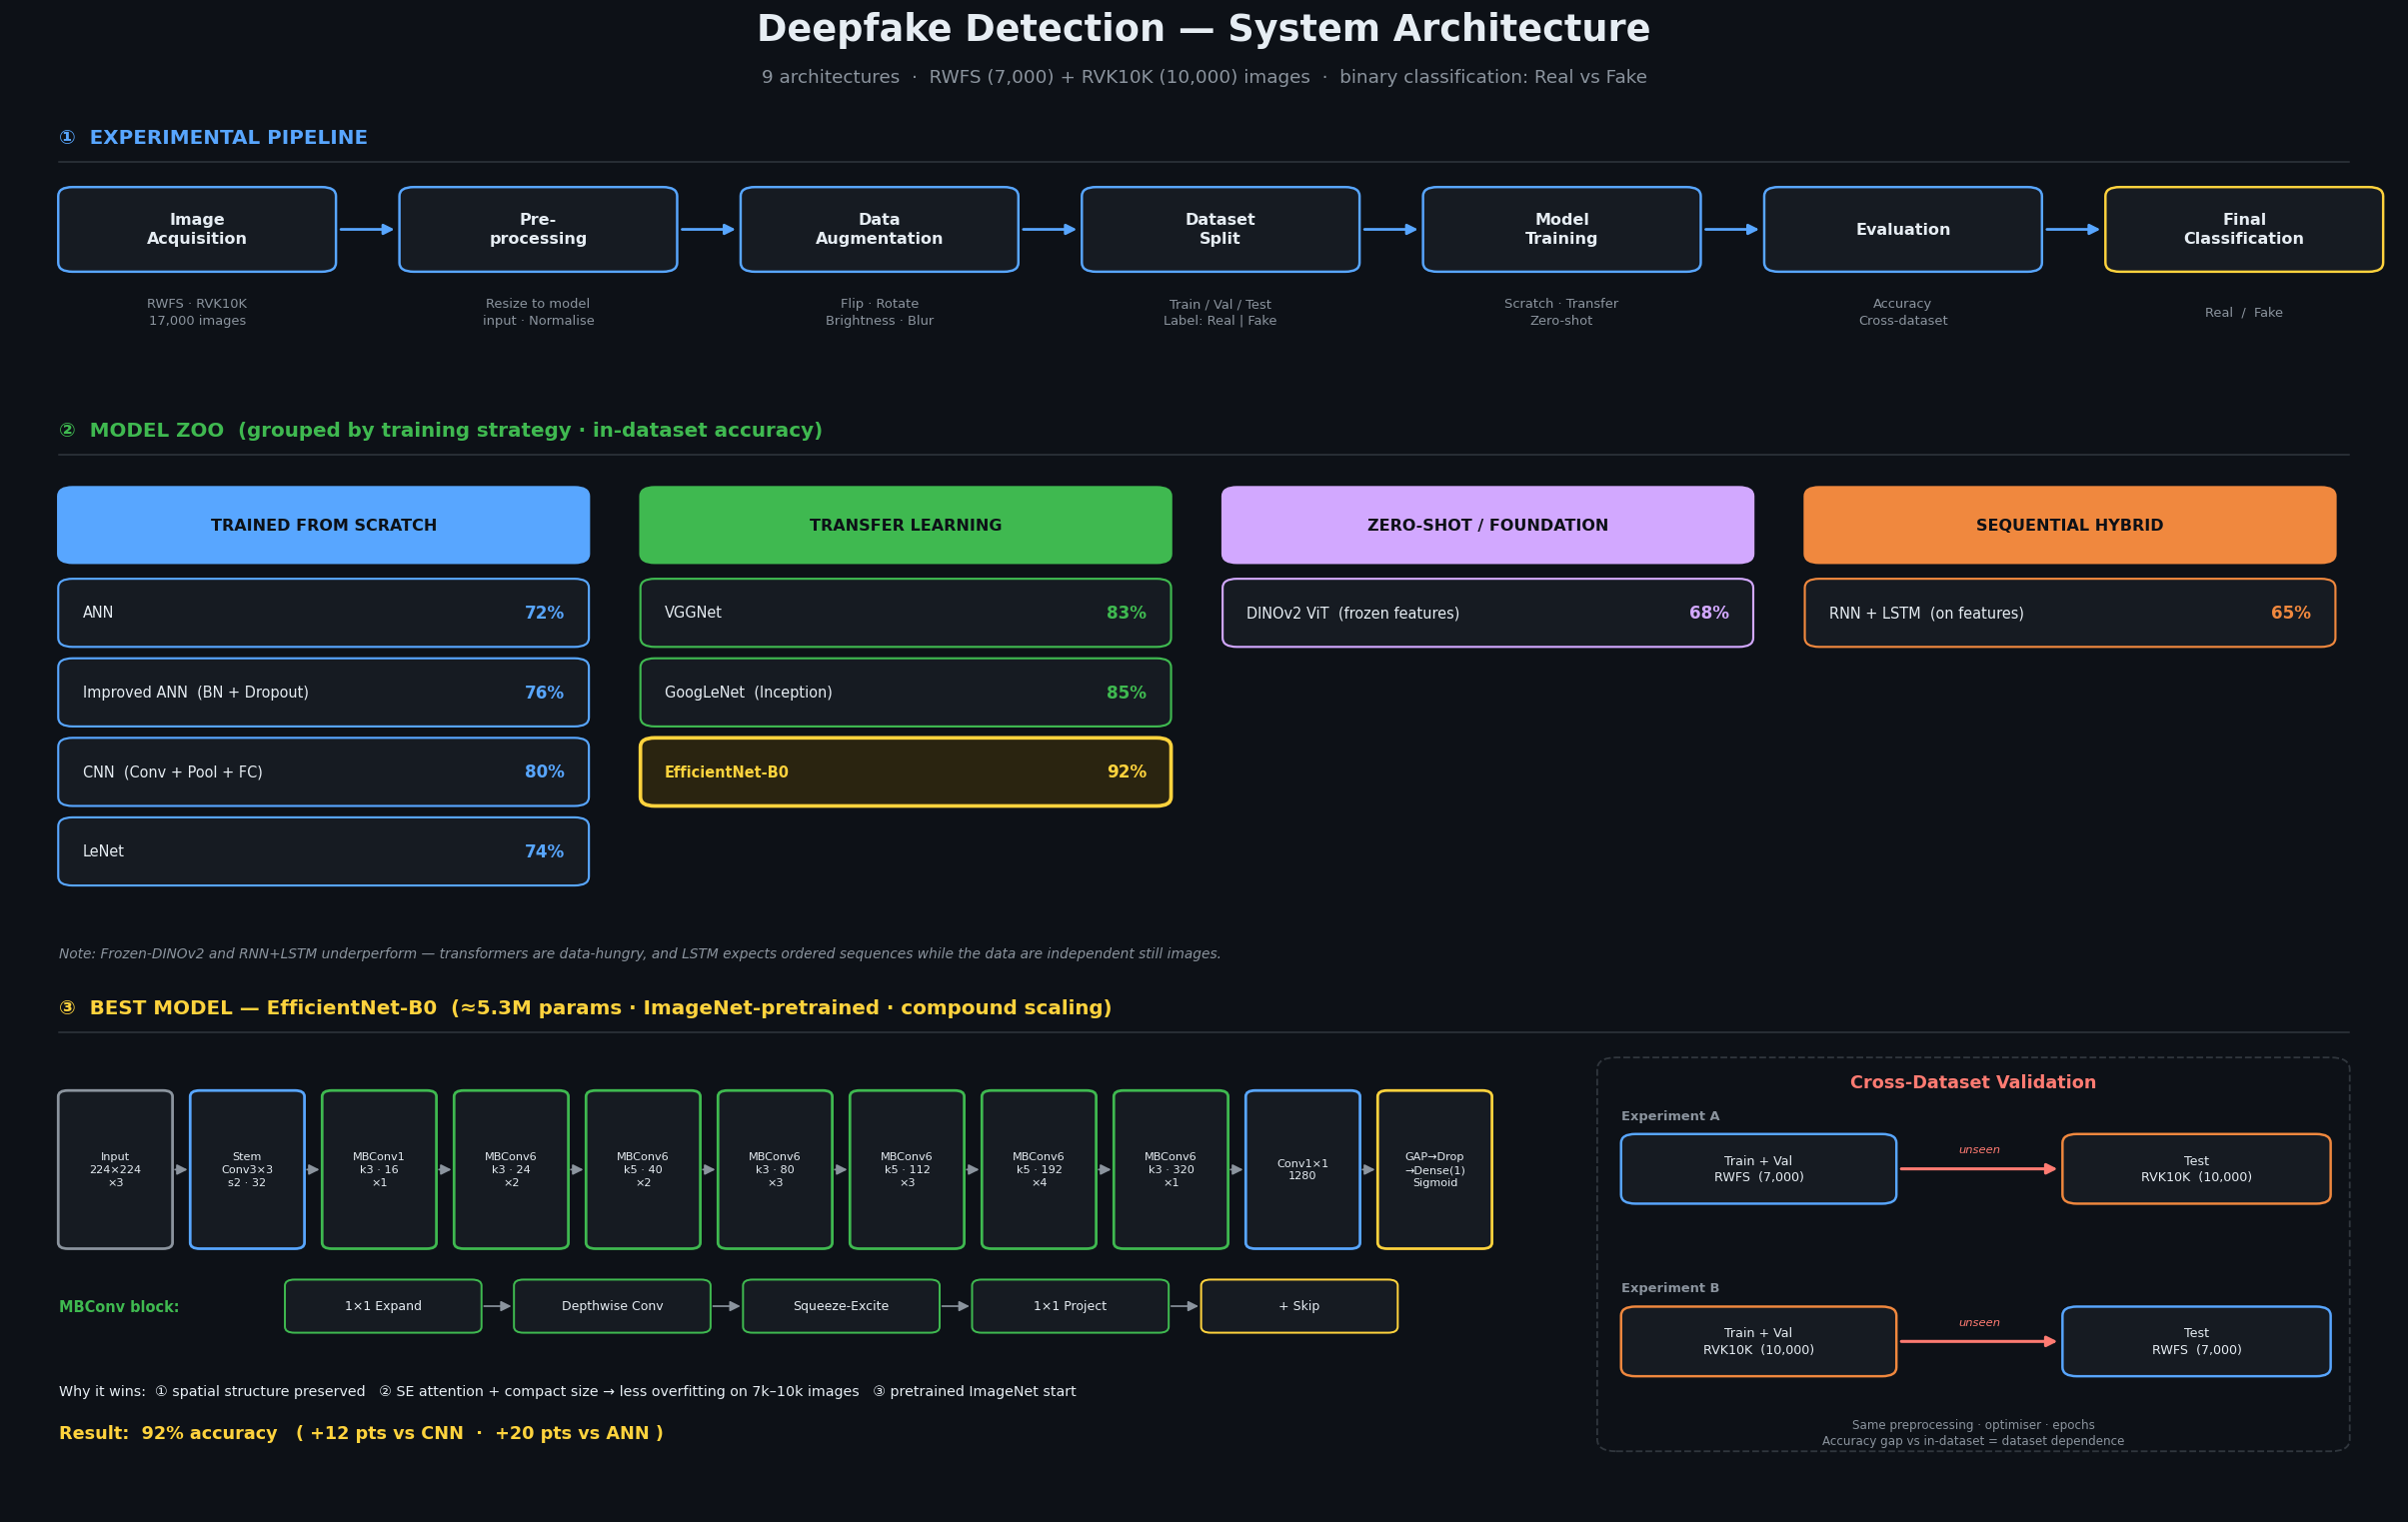

In [1]:
# ============================================================
#  DEEPFAKE DETECTION — SYSTEM ARCHITECTURE OVERVIEW  (Colab)
#  Pipeline · Model zoo · EfficientNet-B0 · Cross-dataset protocol
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ---------- theme ----------
BG, PANEL, TXT, MUTED, EDGE = "#0d1117", "#161b22", "#e6edf3", "#8b949e", "#30363d"
BLUE, GREEN, PURPLE, ORANGE, GOLD, RED = "#58a6ff", "#3fb950", "#d2a8ff", "#f0883e", "#ffd33d", "#ff7b72"
plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(22, 14), dpi=110)
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

# ---------- helpers ----------
def box(x, y, w, h, text, ec=BLUE, fc=PANEL, fs=9, tc=TXT, bold=False, lw=1.6, r=0.6):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0.02,rounding_size={r}",
                                fc=fc, ec=ec, lw=lw, zorder=2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", color=tc, fontsize=fs,
            fontweight="bold" if bold else "normal", zorder=3, linespacing=1.35)

def arrow(x1, y1, x2, y2, c=MUTED, lw=1.8, style="-|>", rad=0.0):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle=style, mutation_scale=14,
                                 color=c, lw=lw, zorder=1, connectionstyle=f"arc3,rad={rad}"))

def section(x, y, text, c=BLUE):
    ax.text(x, y, text, color=c, fontsize=13, fontweight="bold", va="center")
    ax.plot([x, 98], [y - 1.6, y - 1.6], color=EDGE, lw=1, zorder=0)

# ---------- title ----------
ax.text(50, 98, "Deepfake Detection — System Architecture", ha="center", color=TXT, fontsize=24, fontweight="bold")
ax.text(50, 95.2, "9 architectures  ·  RWFS (7,000) + RVK10K (10,000) images  ·  binary classification: Real vs Fake",
        ha="center", color=MUTED, fontsize=12)

# ============ 1) PIPELINE ============
section(2, 91.5, "①  EXPERIMENTAL PIPELINE", BLUE)
steps = [
    ("Image\nAcquisition", "RWFS · RVK10K\n17,000 images"),
    ("Pre-\nprocessing", "Resize to model\ninput · Normalise"),
    ("Data\nAugmentation", "Flip · Rotate\nBrightness · Blur"),
    ("Dataset\nSplit", "Train / Val / Test\nLabel: Real | Fake"),
    ("Model\nTraining", "Scratch · Transfer\nZero-shot"),
    ("Evaluation", "Accuracy\nCross-dataset"),
    ("Final\nClassification", "Real  /  Fake"),
]
w, g, x0, y0 = 11.6, 2.7, 2, 78
for i, (t, s) in enumerate(steps):
    x = x0 + i * (w + g)
    c = GOLD if i == len(steps) - 1 else BLUE
    box(x, y0 + 4.6, w, 5.6, t, ec=c, fs=10.5, bold=True)
    ax.text(x + w/2, y0 + 1.9, s, ha="center", va="center", color=MUTED, fontsize=8.5, linespacing=1.35)
    if i < len(steps) - 1:
        arrow(x + w + 0.1, y0 + 7.4, x + w + g - 0.1, y0 + 7.4, c=BLUE)

# ============ 2) MODEL ZOO ============
section(2, 72, "②  MODEL ZOO  (grouped by training strategy · in-dataset accuracy)", GREEN)
cols = [
    ("TRAINED FROM SCRATCH", BLUE,   [("ANN", 72), ("Improved ANN  (BN + Dropout)", 76), ("CNN  (Conv + Pool + FC)", 80), ("LeNet", 74)]),
    ("TRANSFER LEARNING",    GREEN,  [("VGGNet", 83), ("GoogLeNet  (Inception)", 85), ("EfficientNet-B0", 92)]),
    ("ZERO-SHOT / FOUNDATION", PURPLE, [("DINOv2 ViT  (frozen features)", 68)]),
    ("SEQUENTIAL HYBRID",    ORANGE, [("RNN + LSTM  (on features)", 65)]),
]
cw, cg, cx0 = 22.2, 2.2, 2
for i, (title, c, items) in enumerate(cols):
    x = cx0 + i * (cw + cg)
    box(x, 63.2, cw, 5, title, ec=c, fc=c, tc=BG, fs=10.5, bold=True)
    for j, (name, acc) in enumerate(items):
        y = 57.6 - j * 5.3
        best = acc == 92
        box(x, y, cw, 4.5, "", ec=GOLD if best else c, fc="#2a2410" if best else PANEL, lw=2.4 if best else 1.4)
        ax.text(x + 1.0, y + 2.25, name, color=GOLD if best else TXT, fontsize=9.5, va="center",
                fontweight="bold" if best else "normal", zorder=4)
        ax.text(x + cw - 1.0, y + 2.25, f"{acc}%", color=GOLD if best else c, fontsize=11,
                va="center", ha="right", fontweight="bold", zorder=4)
ax.text(2, 36.9, "Note: Frozen-DINOv2 and RNN+LSTM underperform — transformers are data-hungry, and LSTM expects ordered sequences while the data are independent still images.",
        color=MUTED, fontsize=9, style="italic")

# ============ 3) EFFICIENTNET-B0 ============
section(2, 33.5, "③  BEST MODEL — EfficientNet-B0  (≈5.3M params · ImageNet-pretrained · compound scaling)", GOLD)
blocks = [
    ("Input\n224×224\n×3", MUTED), ("Stem\nConv3×3\ns2 · 32", BLUE),
    ("MBConv1\nk3 · 16\n×1", GREEN), ("MBConv6\nk3 · 24\n×2", GREEN), ("MBConv6\nk5 · 40\n×2", GREEN),
    ("MBConv6\nk3 · 80\n×3", GREEN), ("MBConv6\nk5 · 112\n×3", GREEN), ("MBConv6\nk5 · 192\n×4", GREEN),
    ("MBConv6\nk3 · 320\n×1", GREEN), ("Conv1×1\n1280", BLUE), ("GAP→Drop\n→Dense(1)\nSigmoid", GOLD),
]
bw, bg_, bx0, by = 4.75, 0.78, 2, 17.5
for i, (t, c) in enumerate(blocks):
    x = bx0 + i * (bw + bg_)
    box(x, by, bw, 10.5, t, ec=c, fs=7.4, lw=1.8, r=0.4)
    if i < len(blocks) - 1:
        arrow(x + bw, by + 5.25, x + bw + bg_, by + 5.25, c=MUTED, lw=1.2)
# MBConv internals
ax.text(2, 13.6, "MBConv block:", color=GREEN, fontsize=9.5, fontweight="bold", va="center")
mb = ["1×1 Expand", "Depthwise Conv", "Squeeze-Excite", "1×1 Project", "+ Skip"]
for i, t in enumerate(mb):
    x = 11.5 + i * 9.6
    box(x, 11.9, 8.2, 3.5, t, ec=GREEN if i < 4 else GOLD, fs=8.2, lw=1.3, r=0.4)
    if i < len(mb) - 1:
        arrow(x + 8.2, 13.65, x + 9.6, 13.65, lw=1.1)
ax.text(2, 8.0, "Why it wins:  ① spatial structure preserved   ② SE attention + compact size → less overfitting on 7k–10k images   ③ pretrained ImageNet start",
        color=TXT, fontsize=9.3, va="center")
ax.text(2, 5.2, "Result:  92% accuracy   ( +12 pts vs CNN  ·  +20 pts vs ANN )", color=GOLD, fontsize=11.5, fontweight="bold", va="center")

# ============ 4) CROSS-DATASET ============
ax.add_patch(FancyBboxPatch((66.5, 4), 31.5, 26.2, boxstyle="round,pad=0.02,rounding_size=0.8",
                            fc="none", ec=EDGE, lw=1.2, ls="--", zorder=0))
ax.text(82.25, 28.2, "Cross-Dataset Validation", color=RED, fontsize=11.5, fontweight="bold", ha="center")
# NOTE: sits beside the EfficientNet row's right edge; blocks end near x=64.5
for label, y, a, b, ca, cb in [("Experiment A", 20.5, "Train + Val\nRWFS  (7,000)", "Test\nRVK10K  (10,000)", BLUE, ORANGE),
                               ("Experiment B", 9.0, "Train + Val\nRVK10K  (10,000)", "Test\nRWFS  (7,000)", ORANGE, BLUE)]:
    ax.text(67.5, y + 5.6, label, color=MUTED, fontsize=8.5, fontweight="bold")
    box(67.5, y, 11.5, 4.6, a, ec=ca, fs=8.3)
    box(86, y, 11.2, 4.6, b, ec=cb, fs=8.3)
    arrow(79.1, y + 2.3, 85.9, y + 2.3, c=RED, lw=2)
    ax.text(82.5, y + 3.4, "unseen", color=RED, fontsize=7.5, ha="center", style="italic")
ax.text(82.25, 5.2, "Same preprocessing · optimiser · epochs\nAccuracy gap vs in-dataset = dataset dependence",
        color=MUTED, fontsize=7.8, ha="center", va="center", linespacing=1.3)

plt.tight_layout()
plt.savefig("architecture_overview.png", dpi=200, facecolor=BG, bbox_inches="tight")
plt.show()

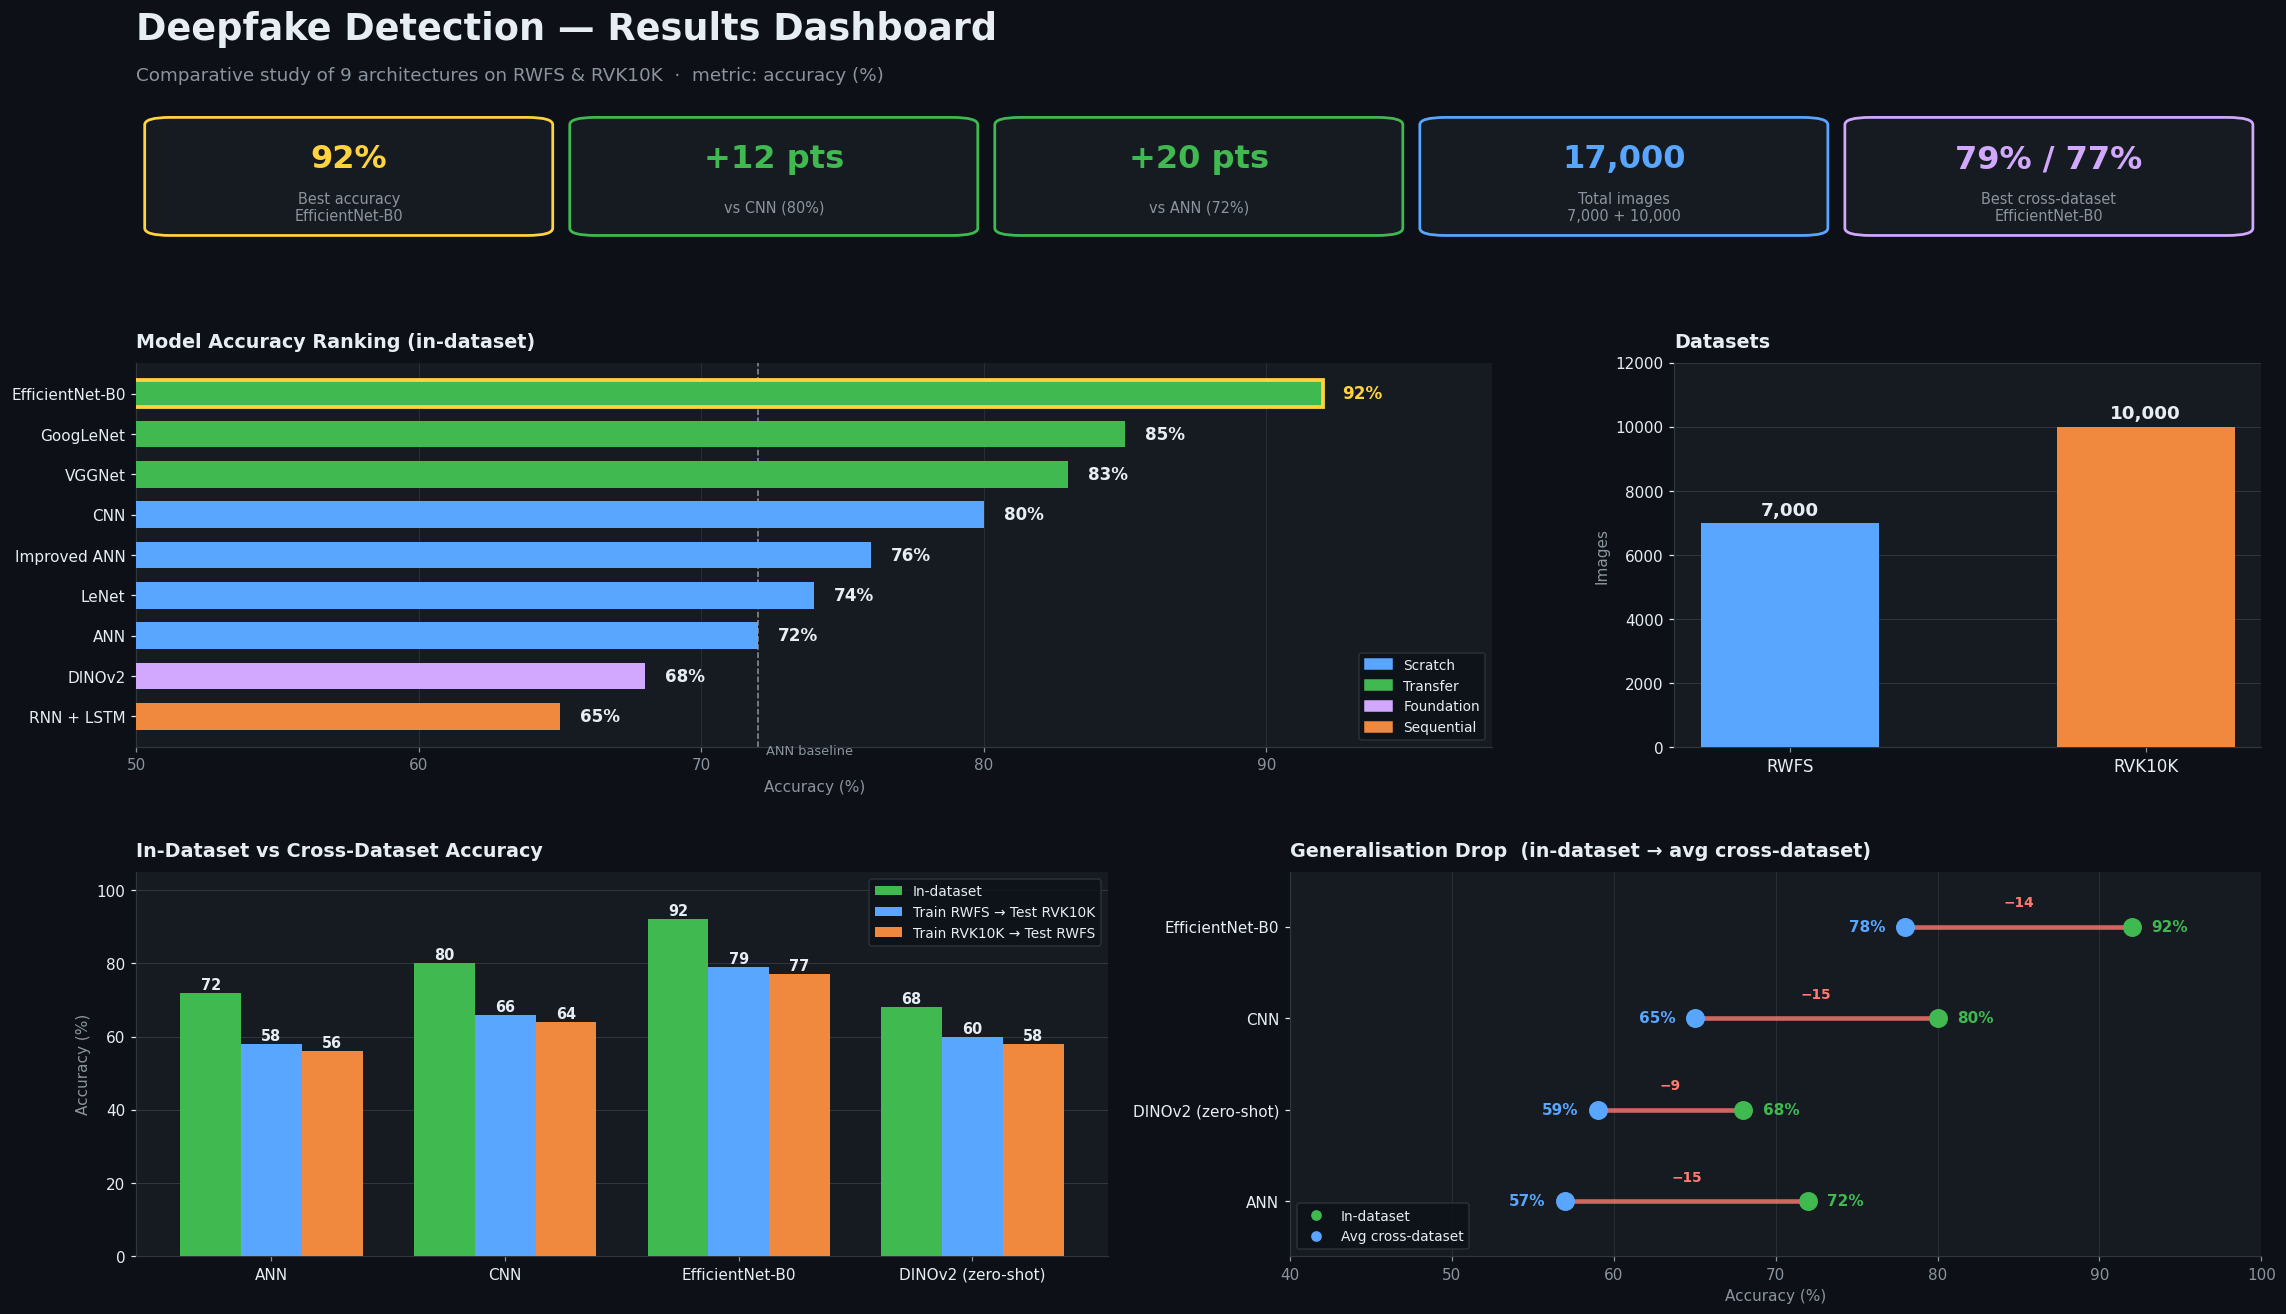

In [2]:
# ============================================================
#  DEEPFAKE DETECTION — RESULTS DASHBOARD  (Colab)
#  KPIs · Model ranking · Cross-dataset · Generalisation drop
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch, Patch

# ---------- theme ----------
BG, PANEL, TXT, MUTED, GRID = "#0d1117", "#161b22", "#e6edf3", "#8b949e", "#30363d"
BLUE, GREEN, PURPLE, ORANGE, GOLD, RED = "#58a6ff", "#3fb950", "#d2a8ff", "#f0883e", "#ffd33d", "#ff7b72"
plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": TXT, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": TXT, "axes.edgecolor": GRID})

# ---------- data (from paper: Tables 1, 3, 4) ----------
models = {  # name: (accuracy, family)
    "EfficientNet-B0": (92, "Transfer"), "GoogLeNet": (85, "Transfer"), "VGGNet": (83, "Transfer"),
    "CNN": (80, "Scratch"), "Improved ANN": (76, "Scratch"), "LeNet": (74, "Scratch"),
    "ANN": (72, "Scratch"), "DINOv2": (68, "Foundation"), "RNN + LSTM": (65, "Sequential"),
}
fam_col = {"Scratch": BLUE, "Transfer": GREEN, "Foundation": PURPLE, "Sequential": ORANGE}
datasets = {"RWFS": 7000, "RVK10K": 10000}
cross = {  # model: (in-dataset, RWFS->RVK10K, RVK10K->RWFS)
    "ANN": (72, 58, 56), "CNN": (80, 66, 64), "EfficientNet-B0": (92, 79, 77), "DINOv2 (zero-shot)": (68, 60, 58),
}

def style(ax, title):
    ax.set_facecolor(PANEL)
    ax.set_title(title, loc="left", fontsize=12.5, fontweight="bold", color=TXT, pad=10)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=0.7, alpha=0.7); ax.set_axisbelow(True)

fig = plt.figure(figsize=(21, 12.5), dpi=110, facecolor=BG)
gs = GridSpec(3, 6, figure=fig, height_ratios=[0.32, 1, 1], hspace=0.42, wspace=0.9,
              left=0.05, right=0.97, top=0.90, bottom=0.07)
fig.text(0.05, 0.955, "Deepfake Detection — Results Dashboard", fontsize=24, fontweight="bold", color=TXT)
fig.text(0.05, 0.925, "Comparative study of 9 architectures on RWFS & RVK10K  ·  metric: accuracy (%)", fontsize=12, color=MUTED)

# ---------- KPI cards ----------
axk = fig.add_subplot(gs[0, :]); axk.axis("off"); axk.set_xlim(0, 5); axk.set_ylim(0, 1)
kpis = [("92%", "Best accuracy\nEfficientNet-B0", GOLD), ("+12 pts", "vs CNN (80%)", GREEN),
        ("+20 pts", "vs ANN (72%)", GREEN), ("17,000", "Total images\n7,000 + 10,000", BLUE),
        ("79% / 77%", "Best cross-dataset\nEfficientNet-B0", PURPLE)]
for i, (v, l, c) in enumerate(kpis):
    axk.add_patch(FancyBboxPatch((i + 0.03, 0.03), 0.94, 0.94, boxstyle="round,pad=0.01,rounding_size=0.06",
                                 fc=PANEL, ec=c, lw=1.8))
    axk.text(i + 0.5, 0.64, v, ha="center", va="center", fontsize=21, fontweight="bold", color=c)
    axk.text(i + 0.5, 0.25, l, ha="center", va="center", fontsize=9.5, color=MUTED, linespacing=1.2)

# ---------- 1) Ranked accuracy ----------
ax1 = fig.add_subplot(gs[1, :4]); style(ax1, "Model Accuracy Ranking (in-dataset)")
names = list(models)[::-1]
acc = [models[n][0] for n in names]
bars = ax1.barh(names, acc, color=[fam_col[models[n][1]] for n in names], height=0.66, zorder=3)
bars[-1].set_edgecolor(GOLD); bars[-1].set_linewidth(2.5)
for b, a, n in zip(bars, acc, names):
    ax1.text(a + 0.7, b.get_y() + b.get_height()/2, f"{a}%", va="center", fontsize=11, fontweight="bold",
             color=GOLD if a == 92 else TXT)
ax1.set_xlim(50, 98); ax1.set_xlabel("Accuracy (%)")
ax1.axvline(72, color=MUTED, ls="--", lw=1, zorder=2); ax1.text(72.3, -0.95, "ANN baseline", color=MUTED, fontsize=8.5)
ax1.legend(handles=[Patch(color=c, label=f) for f, c in fam_col.items()], loc="lower right",
           facecolor=BG, edgecolor=GRID, labelcolor=TXT, fontsize=9)

# ---------- 2) Dataset sizes ----------
ax2 = fig.add_subplot(gs[1, 4:]); style(ax2, "Datasets")
ax2.bar(list(datasets), list(datasets.values()), color=[BLUE, ORANGE], width=0.5, zorder=3)
for i, v in enumerate(datasets.values()):
    ax2.text(i, v + 250, f"{v:,}", ha="center", fontsize=12, fontweight="bold")
ax2.set_ylim(0, 12000); ax2.set_ylabel("Images"); ax2.grid(axis="x", visible=False); ax2.grid(axis="y", color=GRID, lw=0.7)
ax2.tick_params(axis="x", labelcolor=TXT, labelsize=11)

# ---------- 3) Cross-dataset grouped bars ----------
ax3 = fig.add_subplot(gs[2, :3]); style(ax3, "In-Dataset vs Cross-Dataset Accuracy")
ax3.grid(axis="x", visible=False); ax3.grid(axis="y", color=GRID, lw=0.7)
labels = list(cross); x = np.arange(len(labels)); w = 0.26
series = [("In-dataset", GREEN, 0), ("Train RWFS → Test RVK10K", BLUE, 1), ("Train RVK10K → Test RWFS", ORANGE, 2)]
for name, c, k in series:
    vals = [cross[m][k] for m in labels]
    bs = ax3.bar(x + (k - 1) * w, vals, w, color=c, label=name, zorder=3)
    for b, v in zip(bs, vals):
        ax3.text(b.get_x() + b.get_width()/2, v + 1, f"{v}", ha="center", fontsize=9.5, fontweight="bold")
ax3.set_xticks(x); ax3.set_xticklabels(labels, fontsize=10, color=TXT)
ax3.set_ylim(0, 105); ax3.set_ylabel("Accuracy (%)")
ax3.legend(facecolor=BG, edgecolor=GRID, labelcolor=TXT, fontsize=9, loc="upper right", ncol=1)

# ---------- 4) Generalisation drop (dumbbell) ----------
ax4 = fig.add_subplot(gs[2, 3:]); style(ax4, "Generalisation Drop  (in-dataset → avg cross-dataset)")
order = sorted(cross, key=lambda m: np.mean(cross[m][1:]))  # low→high cross acc
for i, m in enumerate(order):
    ind, avg = cross[m][0], np.mean(cross[m][1:])
    ax4.plot([avg, ind], [i, i], color=RED, lw=3, alpha=0.8, zorder=2, solid_capstyle="round")
    ax4.scatter(ind, i, s=130, color=GREEN, zorder=3); ax4.scatter(avg, i, s=130, color=BLUE, zorder=3)
    ax4.text(ind + 1.2, i, f"{ind}%", va="center", fontsize=10, fontweight="bold", color=GREEN)
    ax4.text(avg - 1.2, i, f"{avg:.0f}%", va="center", ha="right", fontsize=10, fontweight="bold", color=BLUE)
    ax4.text((ind + avg)/2, i + 0.22, f"−{ind - avg:.0f}", ha="center", fontsize=9, color=RED, fontweight="bold")
ax4.set_yticks(range(len(order))); ax4.set_yticklabels(order, fontsize=10)
ax4.set_xlim(40, 100); ax4.set_ylim(-0.6, len(order) - 0.4); ax4.set_xlabel("Accuracy (%)")
ax4.legend(handles=[plt.Line2D([], [], marker="o", color=GREEN, ls="", label="In-dataset"),
                    plt.Line2D([], [], marker="o", color=BLUE, ls="", label="Avg cross-dataset")],
           facecolor=BG, edgecolor=GRID, labelcolor=TXT, fontsize=9, loc="lower left")

plt.savefig("results_dashboard.png", dpi=200, facecolor=BG, bbox_inches="tight")
plt.show()